# Uber & Lyft in Boston: price analysis, trip distribution and a small revenue model

Course project for *Transportation Planning* (Industrial Engineering, Sharif University of Technology, fall 1404 / 2025).
Group: Amirabbas Donyadideh, Arshia Sattari Khavas, Alireza Faraji. Instructor: Dr. Hassannayebi.

The data is the Kaggle "Uber and Lyft Dataset Boston, MA" (`rideshare_kaggle.csv`): about 693k price
quotes for 12 neighbourhoods in central Boston between 26 Nov and 18 Dec 2018, with the weather at the
time of each quote.

The project had two phases and this notebook does both, top to bottom:

* **Part A (phase 1)**: a first look at the data, statistical tests on price, weather analysis
  (PCA, clustering, predicting rain) and price models (linear, random forest, XGBoost, Taguchi vs grid
  search, stacking).
* **Part B (phase 2)**: origin-destination matrices, trip distribution with Furness, Detroit, Fratar and
  the gravity model, and an integer program that plans trips for a new competitor.

One thing worth knowing before reading the results: this file is not a log of real trips. Someone
queried the Uber and Lyft apps on a fixed schedule and saved the quoted prices. So whenever we count
"trips" we are really counting quotes, and those counts follow the scraper's schedule, not demand.
This comes up again in A-1.2, A-2.8 and in Part B.

All figures are written to `figures/`. The full run takes around 10 minutes on a laptop, most of it in A-4.5.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.diagnostic import lilliefors

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

SEED = 42
rng = np.random.default_rng(SEED)

# Looks for the csv in data/ first, then next to the notebook.
CANDIDATES = [Path("data/rideshare_kaggle.csv"), Path("rideshare_kaggle.csv"), Path("../rideshare_kaggle.csv")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
assert DATA_PATH is not None, "Download rideshare_kaggle.csv from Kaggle and put it in data/ (see README)."

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight"})
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


def savefig(name):
    """Save the current figure into figures/ and show it."""
    plt.savefig(FIG_DIR / f"{name}.png")
    plt.show()

---
# Part A: Phase 1

## A-1. First look at the data
### A-1.1 Overview

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (693071, 39)


,id,hour,day,month,source,destination,cab_type,product_id,name,price,distance,surge_multiplier,latitude,longitude,temperature,apparentTemperature,short_summary,long_summary,precipIntensity,precipProbability,humidity,windSpeed,windGust,visibility,temperatureHigh,temperatureLow,apparentTemperatureHigh,apparentTemperatureLow,dewPoint,pressure,windBearing,cloudCover,uvIndex,ozone,moonPhase,temperatureMin,temperatureMax,apparentTemperatureMin,apparentTemperatureMax
0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,9,16,12,Haymarket Square,North Station,Lyft,lyft_line,Shared,5.0,0.44,1.0,42.2148,-71.033,42.34,37.12,Mostly Cloudy,Rain throughout the day.,0.0000,0.0,0.68,8.66,9.17,10.000,43.68,34.19,37.95,27.39,32.70,1021.98,57,0.72,0,303.8,0.30,39.89,43.68,33.73,38.07
1,4bd23055-6827-41c6-b23b-3c491f24e74d,2,27,11,Haymarket Square,North Station,Lyft,lyft_premier,Lux,11.0,0.44,1.0,42.2148,-71.033,43.58,37.35,Rain,"Rain until morning, starting again in the eve...",0.1299,1.0,0.94,11.98,11.98,4.786,47.30,42.10,43.92,36.20,41.83,1003.97,90,1.00,0,291.1,0.64,40.49,47.30,36.20,43.92
2,981a3613-77af-4620-a42a-0c0866077d1e,1,28,11,Haymarket Square,North Station,Lyft,lyft,Lyft,7.0,0.44,1.0,42.2148,-71.033,38.33,32.93,Clear,Light rain in the morning.,0.0000,0.0,0.75,7.33,7.33,10.000,47.55,33.10,44.12,29.11,31.10,992.28,240,0.03,0,315.7,0.68,35.36,47.55,31.04,44.12
3,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,4,30,11,Haymarket Square,North Station,Lyft,lyft_luxsuv,Lux Black XL,26.0,0.44,1.0,42.2148,-71.033,34.38,29.63,Clear,Partly cloudy throughout the day.,0.0000,0.0,0.73,5.28,5.28,10.000,45.03,28.90,38.53,26.20,26.64,1013.73,310,0.00,0,291.1,0.75,34.67,45.03,30.30,38.53
4,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,3,29,11,Haymarket Square,North Station,Lyft,lyft_plus,Lyft XL,9.0,0.44,1.0,42.2148,-71.033,37.44,30.88,Partly Cloudy,Mostly cloudy throughout the day.,0.0000,0.0,0.70,9.14,9.14,10.000,42.18,36.71,35.75,30.29,28.61,998.36,303,0.44,0,347.7,0.72,33.10,42.18,29.11,35.75


In [3]:
raw.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 693071 entries, 0 to 693070
Data columns (total 39 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       693071 non-null  str    
 1   hour                     693071 non-null  int64  
 2   day                      693071 non-null  int64  
 3   month                    693071 non-null  int64  
 4   source                   693071 non-null  str    
 5   destination              693071 non-null  str    
 6   cab_type                 693071 non-null  str    
 7   product_id               693071 non-null  str    
 8   name                     693071 non-null  str    
 9   price                    637976 non-null  float64
 10  distance                 693071 non-null  float64
 11  surge_multiplier         693071 non-null  float64
 12  latitude                 693071 non-null  float64
 13  longitude                693071 non-null  float64
 14  temperature    

In [4]:
# Missing values: only `price` has any.
missing = raw.isna().sum()
print(missing[missing > 0])
print("\nShare of missing price per service type:")
print(raw.groupby("name")["price"].apply(lambda s: s.isna().mean()).sort_values(ascending=False).head(3))

price    55095
dtype: int64

Share of missing price per service type:


name
Taxi         1.0
Black SUV    0.0
Lux          0.0
Name: price, dtype: float64


All 55,095 missing prices belong to `Taxi`, and no Taxi row has a price at all. There is nothing to
impute from, so the Taxi rows are dropped from everything that involves price.

In [5]:
# Duplicates and basic sanity checks
print("Duplicated ids:", raw["id"].duplicated().sum())
print("Rows identical in every column except id:", raw.drop(columns="id").duplicated().sum())

checks = {
    "price <= 0": (raw["price"] <= 0).sum(),
    "distance <= 0": (raw["distance"] <= 0).sum(),
    "surge < 1": (raw["surge_multiplier"] < 1).sum(),
    "hour outside 0-23": (~raw["hour"].between(0, 23)).sum(),
    "humidity outside [0,1]": (~raw["humidity"].between(0, 1)).sum(),
}
print(pd.Series(checks, name="invalid rows"))

Duplicated ids: 0


Rows identical in every column except id: 78063
price <= 0                0
distance <= 0             0
surge < 1                 0
hour outside 0-23         0
humidity outside [0,1]    0
Name: invalid rows, dtype: int64


No invalid values. About 78k rows are exact copies of another row apart from `id`. They look like
genuine repeated quotes (same route, product, hour and price), so we keep them.

Some text columns have padding spaces (`" Rain "`), which we strip. There is no timestamp column in the
course version of the file, only `month`, `day` and `hour`. The statement says the data is from 2018, so
we build a datetime with that year.

In [6]:
df = raw.copy()
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

df["datetime"] = pd.to_datetime(dict(year=2018, month=df["month"], day=df["day"], hour=df["hour"]))
df["date"] = df["datetime"].dt.normalize()
df["weekday"] = pd.Categorical(df["datetime"].dt.day_name(), categories=WEEKDAYS, ordered=True)

print("Time window:", df["datetime"].min(), "->", df["datetime"].max())
rows_per_date = df.groupby("date").size()
print(f"Distinct dates: {rows_per_date.size}")
rows_per_date.rename("rows").to_frame().T

Time window: 2018-11-26 03:00:00 -> 2018-12-18 19:00:00
Distinct dates: 17


date,2018-11-26,2018-11-27,2018-11-28,2018-11-29,2018-11-30,2018-12-01,2018-12-02,2018-12-03,2018-12-04,2018-12-09,2018-12-10,2018-12-13,2018-12-14,2018-12-15,2018-12-16,2018-12-17,2018-12-18
rows,31587,76121,73691,59974,45084,45240,44928,44928,12636,1674,2773,38531,44928,44928,44928,44928,36192


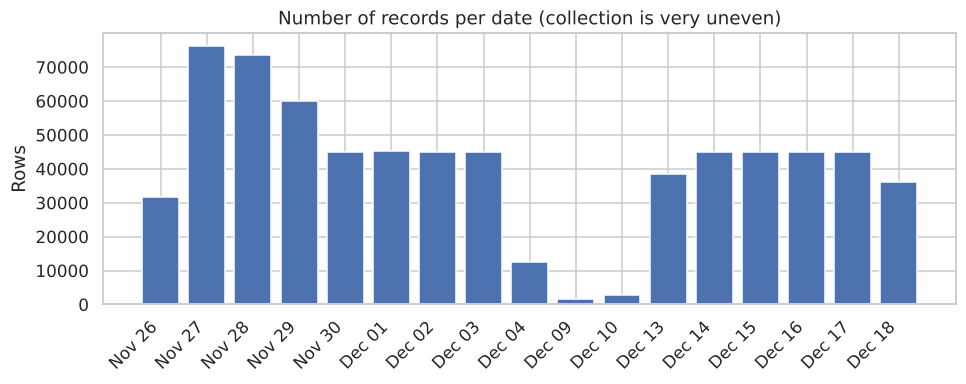

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(rows_per_date.index.strftime("%b %d"), rows_per_date.values, color="#4C72B0")
ax.set_ylabel("Rows")
ax.set_title("Number of records per date (collection is very uneven)")
plt.xticks(rotation=45, ha="right")
savefig("A1_1_rows_per_date")

Only 17 dates appear, and a few of them (4, 9 and 10 December) are only partly covered. Keep this in
mind for anything per weekday: a weekday that shows up on more dates simply has more rows.

In [8]:
num_summary = df.describe().T[["mean", "std", "min", "50%", "max"]]
num_summary.round(2)

,mean,std,min,50%,max
hour,11.619137,6.948114,0.0,12.0,23.0
day,17.794365,9.982286,1.0,17.0,30.0
month,11.586684,0.492429,11.0,12.0,12.0
price,16.545125,9.324359,2.5,13.5,97.5
distance,2.18943,1.138937,0.02,2.16,7.86
surge_multiplier,1.01387,0.091641,1.0,1.0,3.0
latitude,42.338172,0.04784,42.2148,42.3519,42.3661
longitude,-71.066151,0.020302,-71.1054,-71.0631,-71.033
temperature,39.584388,6.726084,18.91,40.49,57.22
apparentTemperature,35.881222,7.918707,12.13,35.9,57.22


In [9]:
# Columns dropped and why
drop_cols = {
    "id": "unique row identifier, no information",
    "product_id": "1-to-1 copy of `name` (shown in 1-3)",
    "latitude": "coordinates of the weather station, not of the trip (12 values unrelated to source)",
    "longitude": "same as latitude",
}
pd.Series(drop_cols, name="reason").to_frame()

,reason
id,"unique row identifier, no information"
product_id,1-to-1 copy of `name` (shown in 1-3)
latitude,"coordinates of the weather station, not of the..."
longitude,same as latitude


In [10]:
# Cleaned frame used from here on: Taxi rows removed, redundant columns dropped.
df_all = df.copy()                                    # kept with Taxi for route counts (1-2)
df = df[df["name"] != "Taxi"].drop(columns=list(drop_cols)).reset_index(drop=True)
print("Rows after removing Taxi:", len(df), f"({len(df_all) - len(df):,} removed)")
print("Remaining missing values:", int(df.isna().sum().sum()))

Rows after removing Taxi: 637976 (55,095 removed)
Remaining missing values: 0


### A-1.2 Origins, destinations and the busiest routes

In [11]:
print("Origins     :", sorted(df_all["source"].unique()))
print("Destinations:", sorted(df_all["destination"].unique()))

od = pd.crosstab(df_all["source"], df_all["destination"])
routes = od.stack().rename("records").reset_index()
routes = routes[routes["records"] > 0].sort_values("records", ascending=False)
print(f"\nRoutes that appear in the data: {len(routes)} of {12 * 11} possible")
routes.head(10)

Origins     : ['Back Bay', 'Beacon Hill', 'Boston University', 'Fenway', 'Financial District', 'Haymarket Square', 'North End', 'North Station', 'Northeastern University', 'South Station', 'Theatre District', 'West End']
Destinations: ['Back Bay', 'Beacon Hill', 'Boston University', 'Fenway', 'Financial District', 'Haymarket Square', 'North End', 'North Station', 'Northeastern University', 'South Station', 'Theatre District', 'West End']



Routes that appear in the data: 72 of 132 possible


,source,destination,records
112,South Station,Financial District,10352
57,Financial District,South Station,10352
6,Back Bay,North End,10225
72,North End,Back Bay,10225
47,Fenway,West End,10165
135,West End,Fenway,10165
64,Haymarket Square,Financial District,10134
53,Financial District,Haymarket Square,10133
73,North End,Beacon Hill,10039
18,Beacon Hill,North End,10039


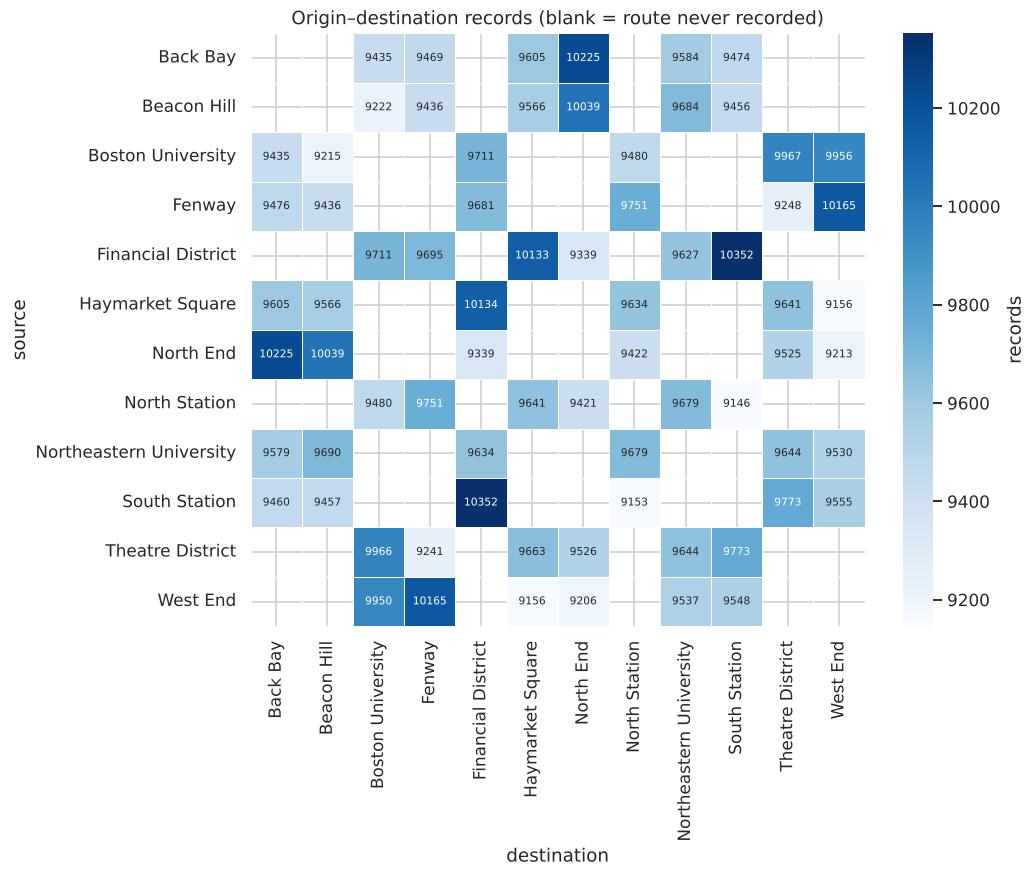

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(od.replace(0, np.nan), annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "records"},
            annot_kws={"size": 7}, linewidths=0.5, ax=ax)
ax.set_title("Origin–destination records (blank = route never recorded)")
ax.set_xlabel("destination"); ax.set_ylabel("source")
savefig("A1_2_od_matrix")

In [13]:
outflow = od.sum(axis=1)
inflow = od.sum(axis=0)
flow = pd.DataFrame({"outflow": outflow, "inflow": inflow})
flow["inflow - outflow"] = flow["inflow"] - flow["outflow"]
print("Locations with outgoing but no incoming trips:", list(flow.index[(flow.outflow > 0) & (flow.inflow == 0)]))
print("Locations with incoming but no outgoing trips:", list(flow.index[(flow.inflow > 0) & (flow.outflow == 0)]))
flow.sort_values("inflow - outflow")

Locations with outgoing but no incoming trips: []
Locations with incoming but no outgoing trips: []


,outflow,inflow,inflow - outflow
Theatre District,57813,57798,-15
Back Bay,57792,57780,-12
North End,57763,57756,-7
Financial District,58857,58851,-6
Northeastern University,57756,57755,-1
South Station,57750,57749,-1
Fenway,57757,57757,0
Beacon Hill,57403,57403,0
Boston University,57764,57764,0
North Station,57118,57119,1


In [14]:
# The 72 recorded routes form a bipartite network: two groups of 6 zones, trips only go between groups.
reach = {s: set(od.columns[od.loc[s] > 0]) for s in od.index}
group_a = sorted(reach["Boston University"])
group_b = sorted(set(od.index) - set(group_a))
print("Group A:", group_a)
print("Group B:", group_b)
assert all(reach[s] == set(group_b) for s in group_a) and all(reach[s] == set(group_a) for s in group_b)

Group A: ['Back Bay', 'Beacon Hill', 'Financial District', 'North Station', 'Theatre District', 'West End']
Group B: ['Boston University', 'Fenway', 'Haymarket Square', 'North End', 'Northeastern University', 'South Station']


There are 12 origins and the same 12 destinations. Only 72 of the 132 possible routes ever show up,
and the pattern is very regular: the zones split into two groups of six and every route goes from one
group to the other. Nothing happens inside a group and there are no intrazonal trips. That is clearly a
choice made when the data was collected.

Each route has roughly 9 to 10 thousand records. The busiest pair is Financial District and South Station
(10,352 each way), followed by Back Bay / North End and Fenway / West End.

No zone has trips going out without trips coming in, or the other way round. Inflow and outflow are
almost identical everywhere (the biggest gap is 28 records out of about 57k) because routes are recorded
in both directions about equally often.

### A-1.3 `product_id` or `name`?

In [15]:
pairs = df_all[["product_id", "name"]].drop_duplicates()
print("Unique product_id:", df_all["product_id"].nunique(), "| unique name:", df_all["name"].nunique(),
      "| unique (product_id, name) pairs:", len(pairs))
pairs.sort_values("name").reset_index(drop=True)

Unique product_id: 13 | unique name: 13 | unique (product_id, name) pairs: 13


,product_id,name
0,6c84fd89-3f11-4782-9b50-97c468b19529,Black
1,6d318bcc-22a3-4af6-bddd-b409bfce1546,Black SUV
2,lyft_premier,Lux
3,lyft_lux,Lux Black
4,lyft_luxsuv,Lux Black XL
5,lyft,Lyft
6,lyft_plus,Lyft XL
7,lyft_line,Shared
8,8cf7e821-f0d3-49c6-8eba-e679c0ebcf6a,Taxi
9,997acbb5-e102-41e1-b155-9df7de0a73f2,UberPool


13 product ids, 13 names, 13 pairs: the two columns are the same thing written differently. We keep
`name` because it is readable and drop `product_id`; keeping both would only add a perfectly collinear
copy.

### A-1.4 Which services does each company offer?

In [16]:
svc = (df_all.groupby(["cab_type", "name"]).size().rename("records").reset_index()
       .sort_values(["cab_type", "records"], ascending=[True, False]))
svc["share in company (%)"] = (svc["records"] / svc.groupby("cab_type")["records"].transform("sum") * 100).round(1)
svc

,cab_type,name,records,share in company (%)
0,Lyft,Lux,51235,16.7
1,Lyft,Lux Black,51235,16.7
2,Lyft,Lux Black XL,51235,16.7
3,Lyft,Lyft,51235,16.7
4,Lyft,Lyft XL,51235,16.7
5,Lyft,Shared,51233,16.7
7,Uber,Black SUV,55096,14.3
11,Uber,UberXL,55096,14.3
12,Uber,WAV,55096,14.3
6,Uber,Black,55095,14.3


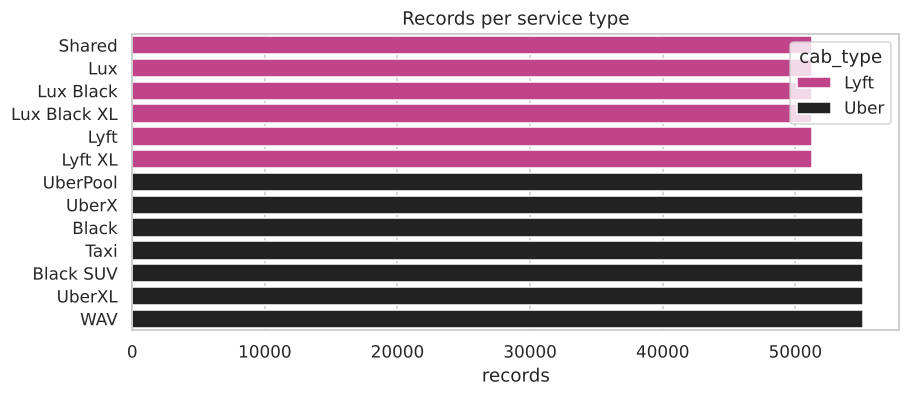

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.5))
order = svc.sort_values(["cab_type", "records"])["name"]
sns.barplot(data=svc, y="name", x="records", hue="cab_type", order=order,
            palette={"Lyft": "#D62F8C", "Uber": "#222222"}, ax=ax, dodge=False)
ax.set_title("Records per service type"); ax.set_ylabel("")
savefig("A1_4_services")

Lyft has six products (Shared, Lyft, Lyft XL, Lux, Lux Black, Lux Black XL) and Uber has seven (UberPool,
UberX, WAV, UberXL, Black, Black SUV, Taxi). No name is shared, so `name` also tells you the company.
Within each company the products have almost exactly the same number of records, which again points to
systematic scraping rather than real rides.

### A-1.5 Turning categories into numbers

Models want numbers, so columns like `name`, `source`, `destination` or `short_summary` need encoding.
The two usual options:

**One-hot (dummy) encoding** makes one 0/1 column per category (drop one of them for linear models).
It doesn't pretend the categories are ordered, every category gets its own coefficient, and the result is
easy to read. The downside is width: a column with k categories becomes k-1 columns, which gets sparse
and heavy for high-cardinality data, and you have to decide what to do with categories that only appear
at prediction time.

**Label (ordinal) encoding** maps each category to an integer. It's one column and works fine for tree
models, which only split on thresholds, and it is the natural choice when the categories really are
ordered. For nominal data it invents an order and equal spacing (`Black=0, Lux=2, UberX=9`), and a linear
model will take that literally.

A third option is target encoding (replace each category by the mean target). It is compact and strong,
but it has to be fitted on training folds only, otherwise it leaks the target.

In [18]:
demo = df[["name"]].drop_duplicates().sort_values("name").reset_index(drop=True)
demo["label_code"] = demo["name"].astype("category").cat.codes
pd.concat([demo, pd.get_dummies(demo["name"], prefix="is", dtype=int).iloc[:, :4]], axis=1)

,name,label_code,is_Black,is_Black SUV,is_Lux,is_Lux Black
0,Black,0,1,0,0,0
1,Black SUV,1,0,1,0,0
2,Lux,2,0,0,1,0
3,Lux Black,3,0,0,0,1
4,Lux Black XL,4,0,0,0,0
5,Lyft,5,0,0,0,0
6,Lyft XL,6,0,0,0,0
7,Shared,7,0,0,0,0
8,UberPool,8,0,0,0,0
9,UberX,9,0,0,0,0


### A-1.6 Encoding `name` and using it
We one-hot encode `name` for the linear models and also give it an ordinal "tier" code, ordered by median
price, for the trees and the correlation matrix. To see whether it matters, here is a linear model of
price on distance, with and without the name dummies.

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

name_order = df.groupby("name")["price"].median().sort_values().index.tolist()
df["name_tier"] = df["name"].map({n: i for i, n in enumerate(name_order)})
name_dummies = pd.get_dummies(df["name"], prefix="name", drop_first=True, dtype=int)

y = df["price"]
X_dist = df[["distance"]]
X_dist_name = pd.concat([df[["distance"]], name_dummies], axis=1)

res = {}
for label, X in {"distance only": X_dist, "distance + name (one-hot)": X_dist_name}.items():
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
    m = LinearRegression().fit(Xtr, ytr)
    p = m.predict(Xte)
    res[label] = {"R2": r2_score(yte, p), "MAE ($)": mean_absolute_error(yte, p), "n features": X.shape[1]}
pd.DataFrame(res).T.round(3)

,R2,MAE ($),n features
distance only,0.119,7.106,1.0
distance + name (one-hot),0.893,1.956,12.0


In [20]:
print("Ordinal tier code (cheapest -> most expensive):")
print({n: i for i, n in enumerate(name_order)})

Ordinal tier code (cheapest -> most expensive):
{'Shared': 0, 'UberPool': 1, 'Lyft': 2, 'UberX': 3, 'WAV': 4, 'Lyft XL': 5, 'UberXL': 6, 'Lux': 7, 'Black': 8, 'Lux Black': 9, 'Black SUV': 10, 'Lux Black XL': 11}


Distance alone explains about 12% of the variance (MAE around \$7). Adding the service type pushes R² to
0.89 and the error down to about \$2. The service type is by far the biggest driver of price, so it goes
into every model from here on.

## A-2. Exploratory and statistical analysis
Everything in A-2.1 to A-2.6 uses the cleaned data (Taxi removed) before any outlier removal.

### A-2.1 Does the service type change the price?
H0: all 12 services have the same mean price. H1: at least one is different.
One-way ANOVA assumes normal groups with equal variances, so we run Levene's test first and back the
result up with Welch's ANOVA (no equal-variance assumption) and Kruskal-Wallis (no normality
assumption).

In [21]:
from statsmodels.stats.oneway import anova_oneway

groups = [g["price"].to_numpy() for _, g in df.groupby("name")]
by_name = df.groupby("name")["price"].agg(["count", "mean", "std", "median"]).sort_values("mean")

lev = stats.levene(*groups, center="median")
f_classic = stats.f_oneway(*groups)
welch = anova_oneway(df["price"], df["name"], use_var="unequal")
kw = stats.kruskal(*groups)

grand = df["price"].mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ss_total = ((df["price"] - grand) ** 2).sum()
eta2 = ss_between / ss_total

tests_21 = pd.DataFrame({
    "statistic": [lev.statistic, f_classic.statistic, welch.statistic, kw.statistic],
    "p-value": [lev.pvalue, f_classic.pvalue, welch.pvalue, kw.pvalue],
}, index=["Levene (equal variances?)", "One-way ANOVA", "Welch ANOVA", "Kruskal–Wallis"])
print(tests_21.to_string(float_format=lambda v: f"{v:,.4g}"))
print(f"\nEffect size eta^2 = {eta2:.3f}  (share of price variance explained by service type)")
by_name.round(2)

                           statistic  p-value
Levene (equal variances?)      7,967        0
One-way ANOVA              1.989e+05        0
Welch ANOVA                2.075e+05        0
Kruskal–Wallis             5.233e+05        0

Effect size eta^2 = 0.774  (share of price variance explained by service type)


,count,mean,std,median
name,,,,
Shared,51233,6.03,2.11,7.0
UberPool,55091,8.75,2.11,8.5
Lyft,51235,9.61,2.53,9.0
WAV,55096,9.77,2.47,9.5
UberX,55094,9.77,2.47,9.5
Lyft XL,51235,15.31,4.56,13.5
UberXL,55096,15.68,4.52,15.0
Lux,51235,17.77,5.29,16.5
Black,55095,20.52,4.95,19.5


All four tests reject with p essentially zero. The variances are not equal (Levene), but Welch and
Kruskal-Wallis, which don't need that assumption, say the same thing as the plain ANOVA: the service type
changes the price. And not by a little: η² is about 0.77, so the service type alone explains roughly 77%
of the variance in price.

### A-2.2 Which services differ from each other?
For the 66 pairwise comparisons we use Tukey's HSD. Since Levene rejected equal variances, we also run
Games-Howell, which is the same idea with Welch standard errors.

In [22]:
tukey = pairwise_tukeyhsd(df["price"], df["name"], alpha=0.05)
tk = pd.DataFrame(tukey._results_table.data[1:], columns=tukey._results_table.data[0])
print(f"Tukey HSD: {tk['reject'].sum()} of {len(tk)} pairs differ significantly")
tk.loc[~tk["reject"]]

Tukey HSD: 65 of 66 pairs differ significantly


,group1,group2,meandiff,p-adj,lower,upper,reject
64,UberX,WAV,-0.0001,1.0,-0.0873,0.0872,False


In [23]:
def games_howell(data, value, group):
    """Games–Howell pairwise test (no equal-variance assumption)."""
    g = data.groupby(group)[value].agg(["mean", "var", "count"])
    k = len(g)
    rows = []
    names = g.index.tolist()
    for i in range(k):
        for j in range(i + 1, k):
            a, b = g.iloc[i], g.iloc[j]
            va, vb = a["var"] / a["count"], b["var"] / b["count"]
            se = np.sqrt(va + vb)
            dof = (va + vb) ** 2 / (va ** 2 / (a["count"] - 1) + vb ** 2 / (b["count"] - 1))
            q = abs(a["mean"] - b["mean"]) / se * np.sqrt(2)
            p = stats.studentized_range.sf(q, k, min(dof, 1e4))   # dof is huge; cap for numerical stability
            rows.append((names[i], names[j], b["mean"] - a["mean"], p))
    out = pd.DataFrame(rows, columns=["group1", "group2", "meandiff", "p-adj"])
    out["reject"] = out["p-adj"] < 0.05
    return out


gh = games_howell(df, "price", "name")
print(f"Games–Howell: {gh['reject'].sum()} of {len(gh)} pairs differ significantly")
gh.loc[~gh["reject"]].round(4)

Games–Howell: 65 of 66 pairs differ significantly


,group1,group2,meandiff,p-adj,reject
64,UberX,WAV,-0.0001,1.0,False


Both give the same answer: 65 of the 66 pairs are different. The one exception is UberX vs WAV, both at
\$9.77 (WAV is the wheelchair-accessible version of UberX and costs the same). With 600k observations
even tiny gaps come out significant; Lyft and UberX differ by only \$0.16, which is significant but
hardly matters in practice.

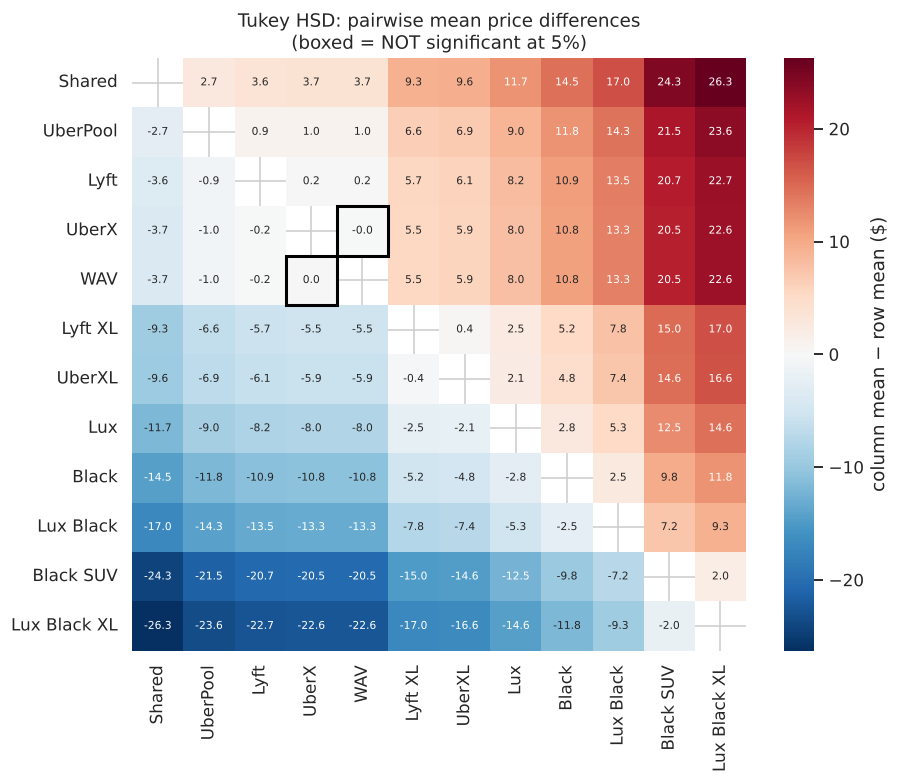

In [24]:
# Matrix view of the Tukey result: mean difference, crossed out where not significant
tk_mat = pd.DataFrame(np.nan, index=name_order, columns=name_order)
sig_mat = pd.DataFrame(True, index=name_order, columns=name_order)
for _, r in tk.iterrows():
    tk_mat.loc[r.group1, r.group2] = r.meandiff
    tk_mat.loc[r.group2, r.group1] = -r.meandiff
    sig_mat.loc[r.group1, r.group2] = sig_mat.loc[r.group2, r.group1] = r.reject
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(tk_mat, cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7},
            mask=np.eye(len(name_order), dtype=bool), cbar_kws={"label": "column mean − row mean ($)"}, ax=ax)
for i, a in enumerate(name_order):
    for j, b in enumerate(name_order):
        if i != j and not sig_mat.loc[a, b]:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", lw=2))
ax.set_title("Tukey HSD: pairwise mean price differences\n(boxed = NOT significant at 5%)")
savefig("A2_2_tukey_matrix")

### A-2.3 Visual check

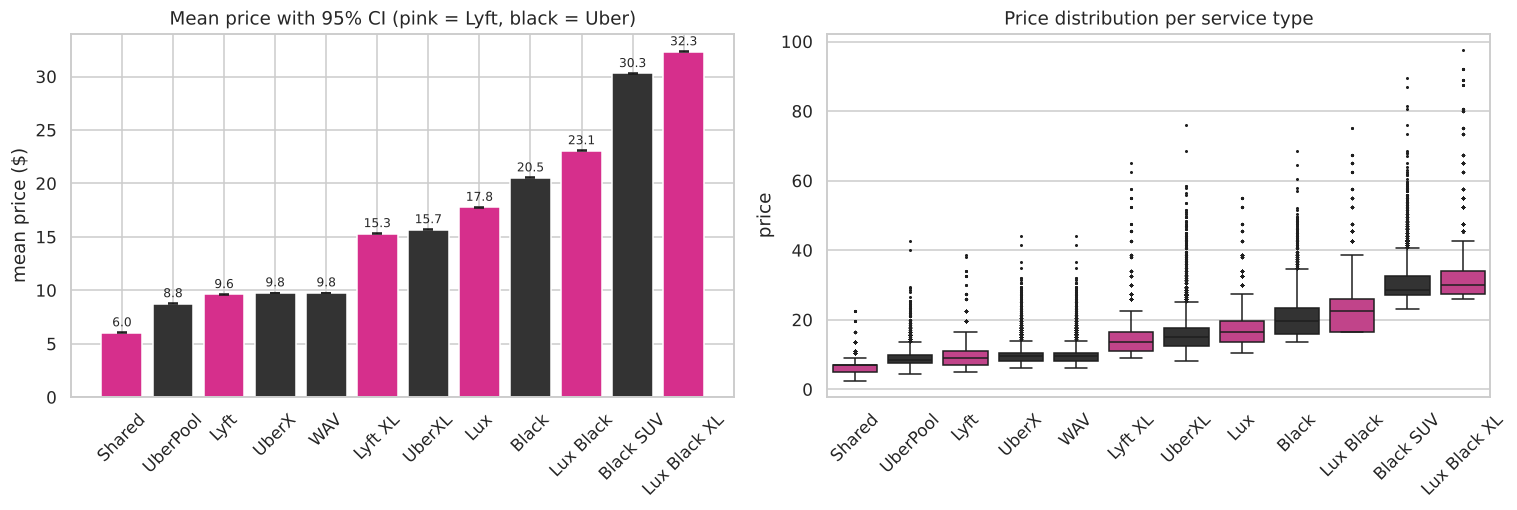

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
palette = {n: ("#D62F8C" if n in svc.loc[svc.cab_type == "Lyft", "name"].values else "#333333") for n in name_order}
ci = df.groupby("name")["price"].agg(["mean", "sem"]).loc[name_order]
axes[0].bar(name_order, ci["mean"], yerr=1.96 * ci["sem"], color=[palette[n] for n in name_order], capsize=3)
for i, v in enumerate(ci["mean"]):
    axes[0].text(i, v + 0.6, f"{v:.1f}", ha="center", fontsize=8)
axes[0].set_ylabel("mean price ($)"); axes[0].set_title("Mean price with 95% CI (pink = Lyft, black = Uber)")
axes[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=df, x="name", y="price", order=name_order, palette=palette, fliersize=1, ax=axes[1])
axes[1].set_title("Price distribution per service type"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
savefig("A2_3_price_by_name")

The picture matches the tests. Shared rides are cheapest (Shared, UberPool), then the standard tier
(Lyft, UberX, WAV at about \$9.6 to 9.8), the XL cars (about \$15 to 16), Lux and Black (about \$18 to 23)
and the large premium cars (Black SUV and Lux Black XL at \$30 to 32). The UberX and WAV bars are
identical. The spread grows with the tier too, which is why Levene rejected equal variances.

### A-2.4 How does price change over time?
A plain hourly average mixes real price changes with changes in which services happened to be quoted in
that hour, so we also look at the daily mean of each service separately. Days with no data are left as
gaps.

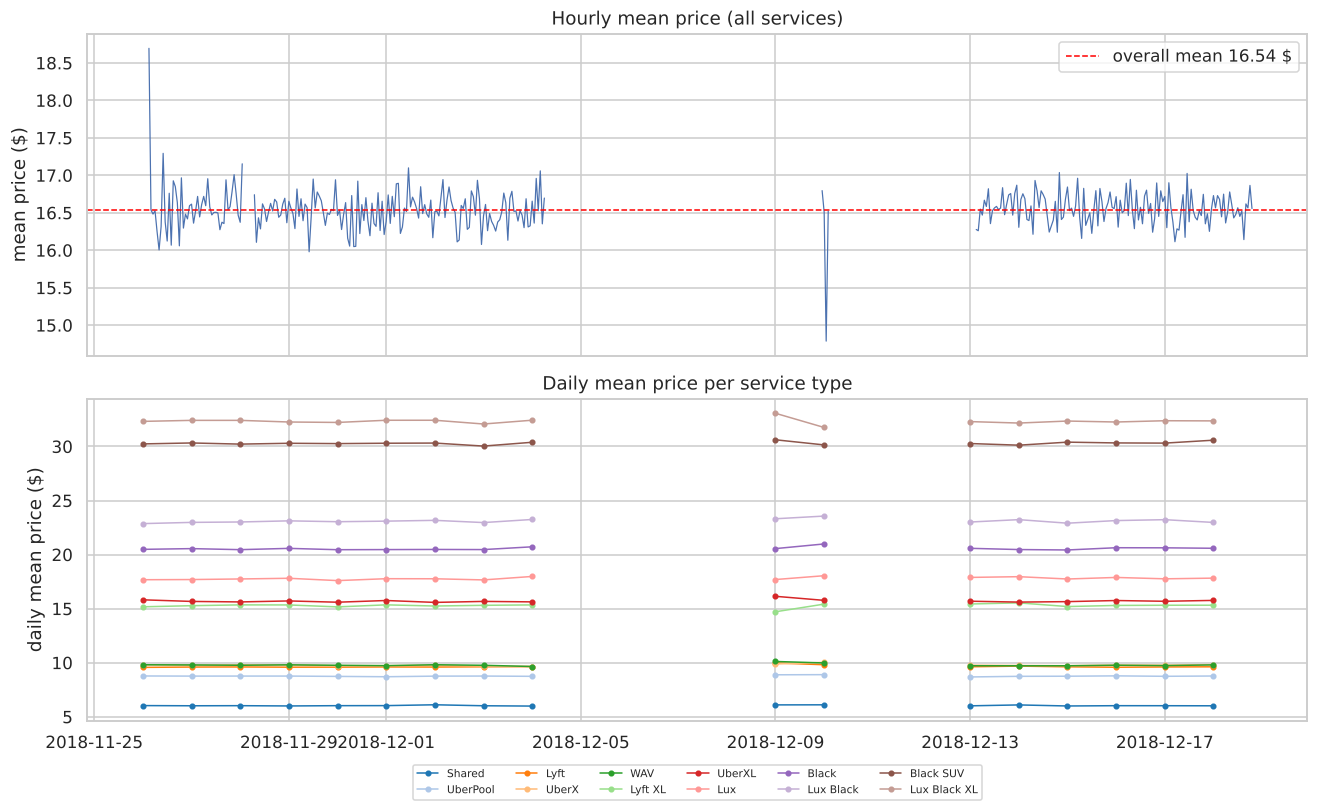

Hourly mean price: {'count': 332.0, 'mean': 16.544, 'std': 0.269, 'min': 14.787, '25%': 16.393, '50%': 16.529, '75%': 16.688, 'max': 18.695}

Day-to-day coefficient of variation per service (%):
name
Black SUV       0.48
UberPool        0.60
Shared          0.65
Black           0.66
Lux             0.69
Lux Black       0.75
Lux Black XL    0.79
UberXL          0.83
UberX           0.88
Lyft            1.07
WAV             1.10
Lyft XL         1.14


In [26]:
# reindex to a regular calendar so that days without data show as gaps instead of straight lines
hourly = df.groupby("datetime")["price"].mean().asfreq("h")
daily_by_name = df.groupby(["date", "name"])["price"].mean().unstack().asfreq("D")

fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
axes[0].plot(hourly.index, hourly.values, lw=0.8, color="#4C72B0")
axes[0].axhline(hourly.mean(), color="red", ls="--", lw=1, label=f"overall mean {hourly.mean():.2f} $")
axes[0].set_ylabel("mean price ($)"); axes[0].legend(); axes[0].set_title("Hourly mean price (all services)")
cmap20 = plt.get_cmap("tab20")
for k, n in enumerate(name_order):
    axes[1].plot(daily_by_name.index, daily_by_name[n], marker="o", ms=3, lw=1, label=n, color=cmap20(k))
axes[1].set_ylabel("daily mean price ($)"); axes[1].set_title("Daily mean price per service type")
axes[1].legend(ncol=6, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
savefig("A2_4_price_over_time")

print("Hourly mean price:", hourly.dropna().describe().round(3).to_dict())
day_cv = (daily_by_name.std() / daily_by_name.mean() * 100).round(2)
print("\nDay-to-day coefficient of variation per service (%):")
print(day_cv.sort_values().to_string())

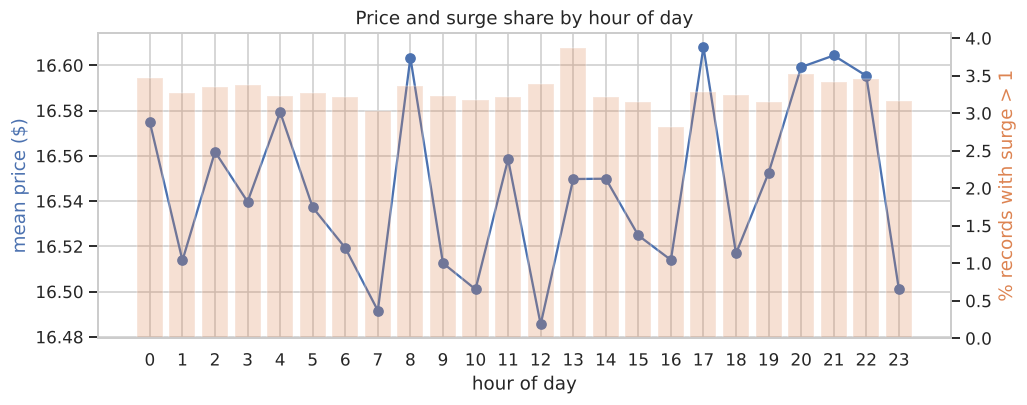

Share of records with surge > 1 (%): {'Lyft': 6.82, 'Uber': 0.0}
Price range of hourly means by hour of day: 16.49 – 16.61 $


In [27]:
by_hour = df.groupby("hour").agg(price=("price", "mean"),
                                 surge_share=("surge_multiplier", lambda s: (s > 1).mean() * 100))
fig, ax1 = plt.subplots(figsize=(10, 3.6))
ax1.plot(by_hour.index, by_hour["price"], marker="o", color="#4C72B0", label="mean price")
ax1.set_xlabel("hour of day"); ax1.set_ylabel("mean price ($)", color="#4C72B0"); ax1.set_xticks(range(24))
ax2 = ax1.twinx()
ax2.bar(by_hour.index, by_hour["surge_share"], alpha=0.25, color="#DD8452", label="% rides with surge")
ax2.set_ylabel("% records with surge > 1", color="#DD8452"); ax2.grid(False)
ax1.set_title("Price and surge share by hour of day")
savefig("A2_4_price_by_hour")

surge_by_cab = df.groupby("cab_type")["surge_multiplier"].agg(lambda s: (s > 1).mean() * 100)
print("Share of records with surge > 1 (%):", surge_by_cab.round(2).to_dict())
print("Price range of hourly means by hour of day: "
      f"{by_hour['price'].min():.2f} – {by_hour['price'].max():.2f} $")

Prices are basically flat. The hourly mean stays between \$16 and \$17 except for a few hours with very
few records (the start of 26 Nov and the half-empty 9 and 10 Dec), and each service's daily mean moves by
about 0.5 to 1% from one day to the next. By hour of day the mean only moves by around ten cents.

Surge pricing only exists for Lyft (6.8% of Lyft quotes, none for Uber) and it isn't tied to particular
hours. So over these three weeks there is no trend and no visible rush-hour pricing.

### A-2.5 Distribution and outliers of price

/tmp/ipykernel_250/3951300956.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(price, vert=False, widths=0.6, flierprops={"markersize": 2})


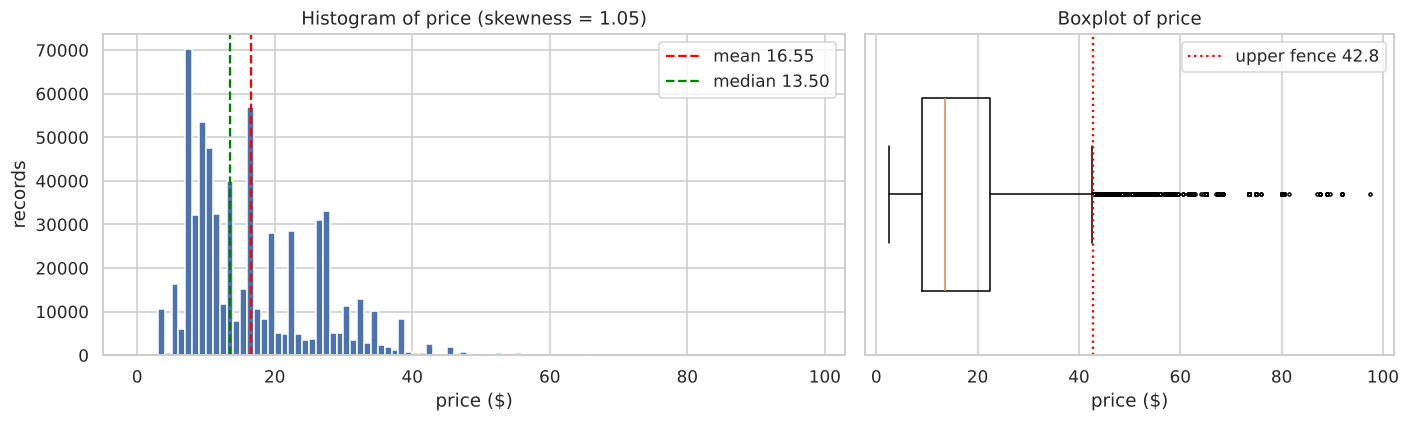

{'count': 637976.0, 'mean': 16.55, 'std': 9.32, 'min': 2.5, '25%': 9.0, '50%': 13.5, '75%': 22.5, 'max': 97.5}
Q1=9.0, Q3=22.5, IQR=13.5, fences=[-11.25, 42.75]
Global IQR outliers: 5,589 (0.88%)

Who are the global outliers?
name
Lux Black XL    3365
Black SUV       1357
Lux Black        569
Lux              116
Black             77
UberXL            61
Lyft XL           42
UberX              1
WAV                1
Mean surge of outliers: 1.337 | overall: 1.015
Mean distance of outliers: 4.12 | overall: 2.19


In [28]:
price = df["price"]
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
global_out = (price < lo) | (price > hi)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].hist(price, bins=np.arange(0, price.max() + 1, 1), color="#4C72B0", edgecolor="white")
axes[0].axvline(price.mean(), color="red", ls="--", label=f"mean {price.mean():.2f}")
axes[0].axvline(price.median(), color="green", ls="--", label=f"median {price.median():.2f}")
axes[0].set_xlabel("price ($)"); axes[0].set_ylabel("records"); axes[0].legend()
axes[0].set_title(f"Histogram of price (skewness = {price.skew():.2f})")
axes[1].boxplot(price, vert=False, widths=0.6, flierprops={"markersize": 2})
axes[1].axvline(hi, color="red", ls=":", label=f"upper fence {hi:.1f}")
axes[1].set_xlabel("price ($)"); axes[1].set_yticks([]); axes[1].legend()
axes[1].set_title("Boxplot of price")
plt.tight_layout()
savefig("A2_5_price_hist_box")

print(price.describe().round(2).to_dict())
print(f"Q1={q1}, Q3={q3}, IQR={iqr}, fences=[{lo}, {hi}]")
print(f"Global IQR outliers: {global_out.sum():,} ({global_out.mean() * 100:.2f}%)")
print("\nWho are the global outliers?")
print(df.loc[global_out, "name"].value_counts().to_string())
print("Mean surge of outliers:", round(df.loc[global_out, "surge_multiplier"].mean(), 3),
      "| overall:", round(df["surge_multiplier"].mean(), 3))
print("Mean distance of outliers:", round(df.loc[global_out, "distance"].mean(), 2),
      "| overall:", round(df["distance"].mean(), 2))

The distribution is right-skewed (skewness about 1.05): most quotes are between \$5 and \$25 with a long
tail past \$40. The IQR rule flags 5,589 quotes (0.9%) above \$42.75. These aren't errors. Almost all
of them are Lux Black XL or Black SUV, they are about twice as long as the average trip (4.1 vs 2.2
miles) and their mean surge is 1.34. That matters for how we clean the column in A-2.7.

### A-2.6 Is price normally distributed?
We use four tests: Shapiro-Wilk, D'Agostino-Pearson K², Anderson-Darling and Kolmogorov-Smirnov
(Lilliefors), plus a Q-Q plot. Shapiro-Wilk's p-value is only reliable up to about 5,000 points, and with
600k rows every test rejects even a negligible deviation, so all four run on the same random sample of
5,000 prices.

Quick notes on each: Shapiro-Wilk is the most powerful for small and medium samples but breaks down for
large n. D'Agostino-Pearson is built from skewness and kurtosis, so it also tells you what kind of
departure you have, but it is weak for small samples. Anderson-Darling puts extra weight on the tails,
which suits a long-tailed variable like price. Lilliefors is the simplest to understand and the least
powerful of the four.

                        statistic                    p-value / decision
Shapiro–Wilk             0.906758                              4.86e-48
D'Agostino–Pearson K²  788.770838                             5.26e-172
Anderson–Darling       144.166203  stat > critical 0.752 (5%) -> reject
Lilliefors (KS)          0.135642                              1.00e-03

skewness = 1.046, excess kurtosis = 1.225


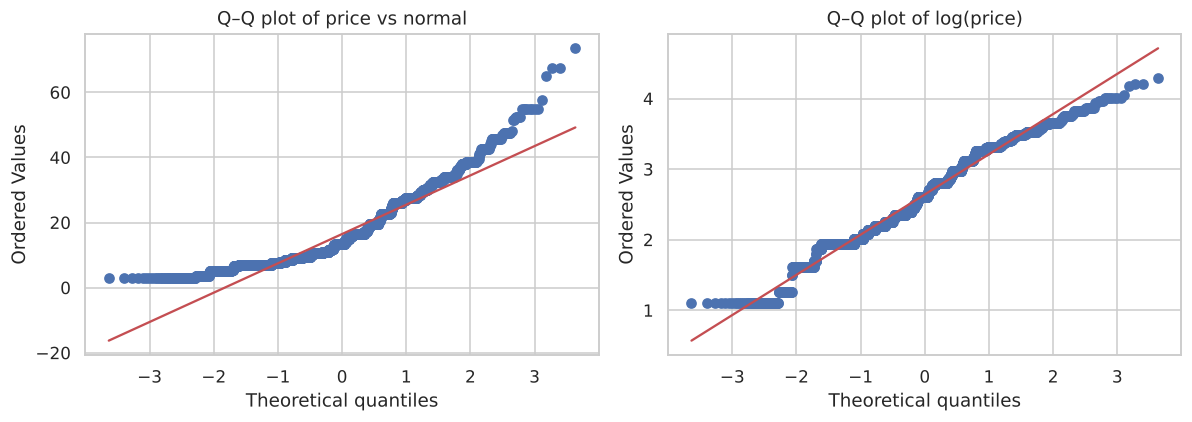

In [29]:
sample = price.sample(5000, random_state=SEED)
sw = stats.shapiro(sample)
k2 = stats.normaltest(sample)
ad = stats.anderson(sample, dist="norm")
ks_stat, ks_p = lilliefors(sample, dist="norm")
normality = pd.DataFrame({
    "statistic": [sw.statistic, k2.statistic, ad.statistic, ks_stat],
    "p-value / decision": [f"{sw.pvalue:.2e}", f"{k2.pvalue:.2e}",
                           f"stat > critical {ad.critical_values[2]:.3f} (5%) -> reject", f"{ks_p:.2e}"],
}, index=["Shapiro–Wilk", "D'Agostino–Pearson K²", "Anderson–Darling", "Lilliefors (KS)"])
print(normality)
print(f"\nskewness = {price.skew():.3f}, excess kurtosis = {price.kurt():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
stats.probplot(sample, dist="norm", plot=axes[0]); axes[0].set_title("Q–Q plot of price vs normal")
stats.probplot(np.log(sample), dist="norm", plot=axes[1]); axes[1].set_title("Q–Q plot of log(price)")
plt.tight_layout()
savefig("A2_6_qq")

All four reject normality by a wide margin and the Q-Q plot bends away in both tails. That's expected:
price is a mix of 12 different service-level distributions. Even log(price) isn't normal. So the
rank-based Kruskal-Wallis in A-2.1 was a useful check, and none of the models below rely on normal
errors.

### A-2.7 Removing outliers
The two standard rules are:

1. IQR (Tukey's fences): drop anything outside [Q1 - 1.5·IQR, Q3 + 1.5·IQR]. Non-parametric and fine with
   skewed data, though the 1.5 is just a convention.
2. Z-score: drop anything with |z| > 3. Simple, but it assumes a roughly normal variable, and the mean and
   standard deviation are themselves pulled around by the outliers.

Applied to the pooled price, both rules mostly throw away legitimate expensive rides, because price is a
mixture of 12 services. So we also apply them *within each service*, which flags rides that are odd for
their own service (a \$20 UberX, say). The within-service IQR rule is the one we keep for modelling.

In [30]:
def iqr_mask(s, k=1.5):
    a, b = s.quantile([0.25, 0.75])
    return (s < a - k * (b - a)) | (s > b + k * (b - a))


def z_mask(s, t=3):
    return ((s - s.mean()) / s.std()).abs() > t


masks = {
    "IQR, pooled": iqr_mask(df["price"]),
    "Z-score, pooled": z_mask(df["price"]),
    "IQR, within service": df.groupby("name")["price"].transform(lambda s: iqr_mask(s)).astype(bool),
    "Z-score, within service": df.groupby("name")["price"].transform(lambda s: z_mask(s)).astype(bool),
}
summary_27 = pd.DataFrame({
    "removed": {k: int(m.sum()) for k, m in masks.items()},
    "removed %": {k: round(m.mean() * 100, 2) for k, m in masks.items()},
    "share of removed with surge>1 (%)": {k: round((df.loc[m, "surge_multiplier"] > 1).mean() * 100, 1) for k, m in masks.items()},
    "mean distance of removed": {k: round(df.loc[m, "distance"].mean(), 2) for k, m in masks.items()},
})
summary_27

,removed,removed %,share of removed with surge>1 (%),mean distance of removed
"IQR, pooled",5589,0.88,50.3,4.12
"Z-score, pooled",5114,0.80,55.0,4.04
"IQR, within service",21665,3.40,25.8,4.14
"Z-score, within service",8587,1.35,39.2,4.16


In [31]:
print("Removed by pooled IQR, per service:\n", df.loc[masks["IQR, pooled"], "name"].value_counts().to_string())
print("\nRemoved by within-service IQR, per service:\n",
      df.loc[masks["IQR, within service"], "name"].value_counts().to_string())

df_model = df.loc[~masks["IQR, within service"]].reset_index(drop=True)
print(f"\nRows kept for modelling: {len(df_model):,}")

Removed by pooled IQR, per service:
 name
Lux Black XL    3365
Black SUV       1357
Lux Black        569
Lux              116
Black             77
UberXL            61
Lyft XL           42
UberX              1
WAV                1

Removed by within-service IQR, per service:
 name
Lux Black XL    3365
WAV             2697
UberX           2697
Shared          2423
Black SUV       2278
UberXL          1886
UberPool        1465
Lyft XL         1446
Lux             1320
Black            865
Lux Black        775
Lyft             448

Rows kept for modelling: 616,311


The pooled IQR and z-score rules remove about the same 0.8 to 0.9% of rows, and half of what they remove
has a surge, so they are mainly cutting real expensive rides. The within-service IQR removes 3.4%, spread
over all services. That leaves 616,311 rows for modelling.

### A-2.8 Heatmap by weekday and hour
Because only 17 dates are in the file (Monday shows up on more dates than Wednesday, for example), raw
counts mostly show when the scraper was running. We plot the raw counts, the number of dates behind
each cell, and the counts divided by that number.

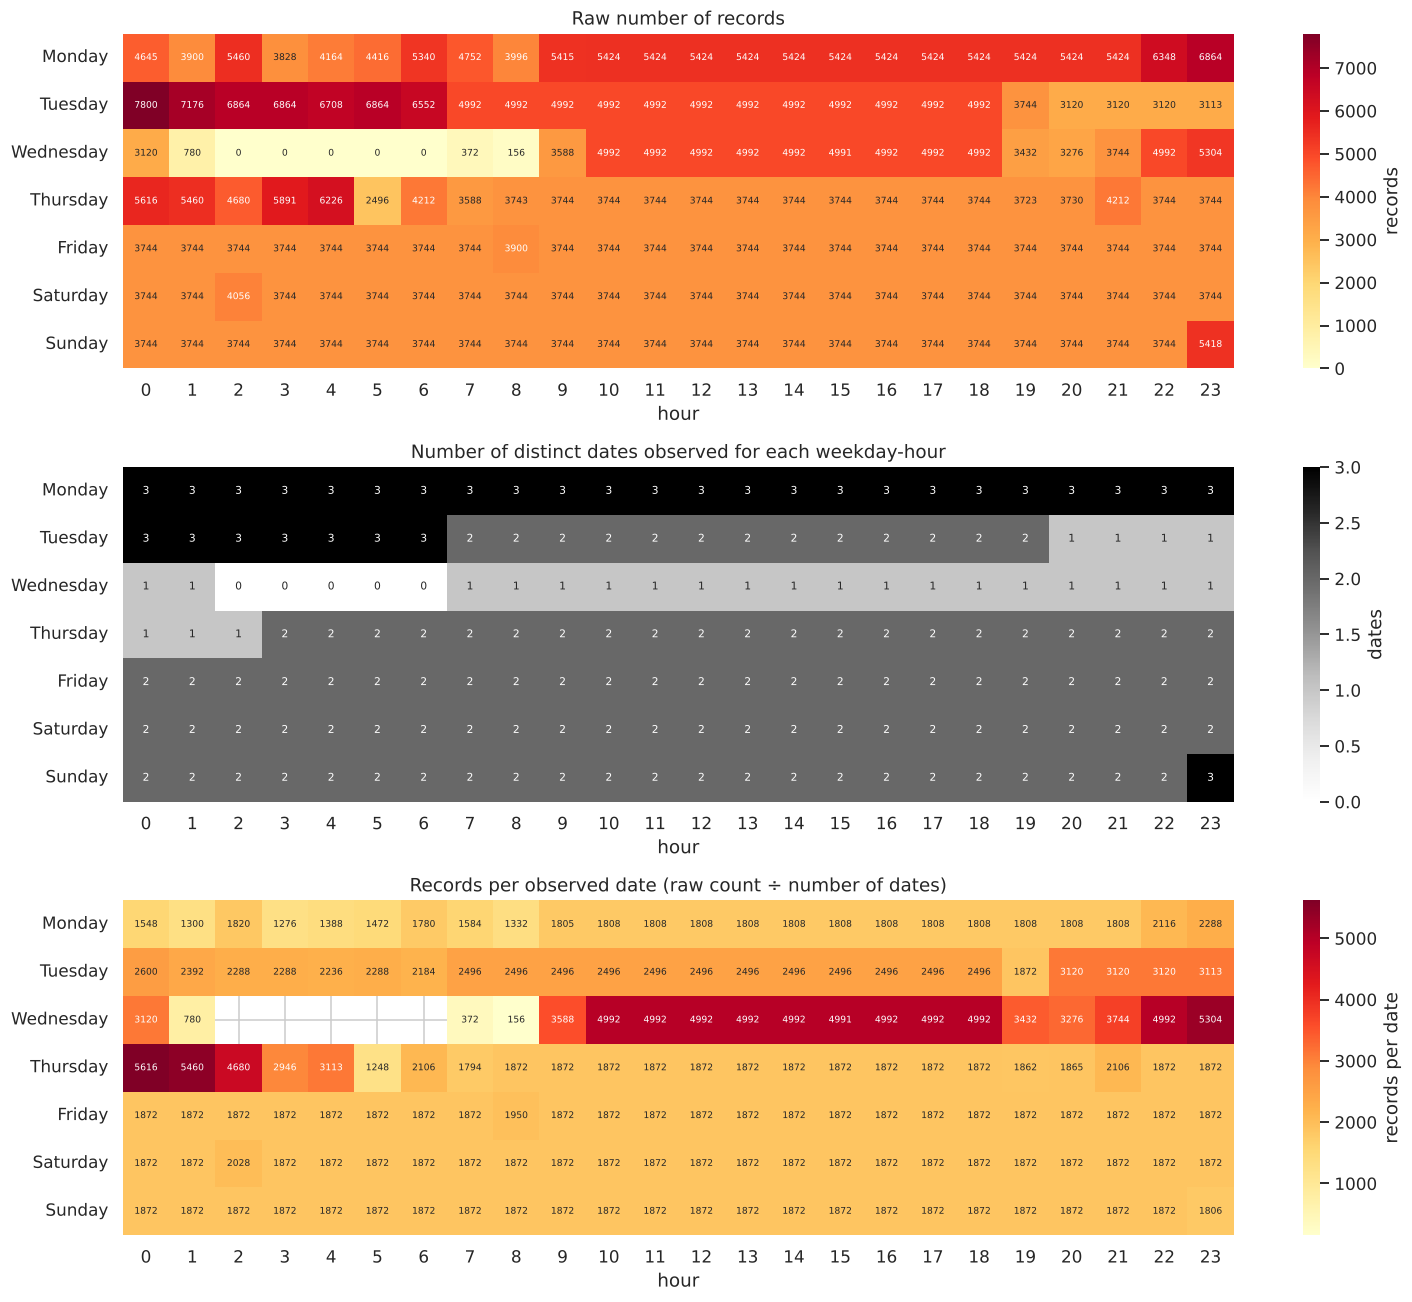

Dates per weekday: {'Monday': 4, 'Tuesday': 3, 'Wednesday': 1, 'Thursday': 2, 'Friday': 2, 'Saturday': 2, 'Sunday': 3}
Per-slot records: min 156, median 1872, max 5616


In [32]:
cnt = df_all.pivot_table(index="weekday", columns="hour", values="price", aggfunc="size", observed=False).reindex(WEEKDAYS)
n_dates = (df_all.groupby(["weekday", "hour"], observed=False)["date"].nunique().unstack().reindex(WEEKDAYS))
per_slot = cnt / n_dates.replace(0, np.nan)

fig, axes = plt.subplots(3, 1, figsize=(14, 12))
sns.heatmap(cnt, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 6}, ax=axes[0], cbar_kws={"label": "records"})
axes[0].set_title("Raw number of records")
sns.heatmap(n_dates, cmap="Greys", annot=True, fmt=".0f", annot_kws={"size": 7}, ax=axes[1], cbar_kws={"label": "dates"})
axes[1].set_title("Number of distinct dates observed for each weekday-hour")
sns.heatmap(per_slot, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 6}, ax=axes[2], cbar_kws={"label": "records per date"})
axes[2].set_title("Records per observed date (raw count ÷ number of dates)")
for a in axes:
    a.set_xlabel("hour"); a.set_ylabel("")
plt.tight_layout()
savefig("A2_8_heatmap")

print("Dates per weekday:", df_all.groupby("weekday", observed=False)["date"].nunique().to_dict())
print("Per-slot records: min %.0f, median %.0f, max %.0f" % (np.nanmin(per_slot), np.nanmedian(per_slot), np.nanmax(per_slot)))

### A-2.9 Records by hour and by weekday

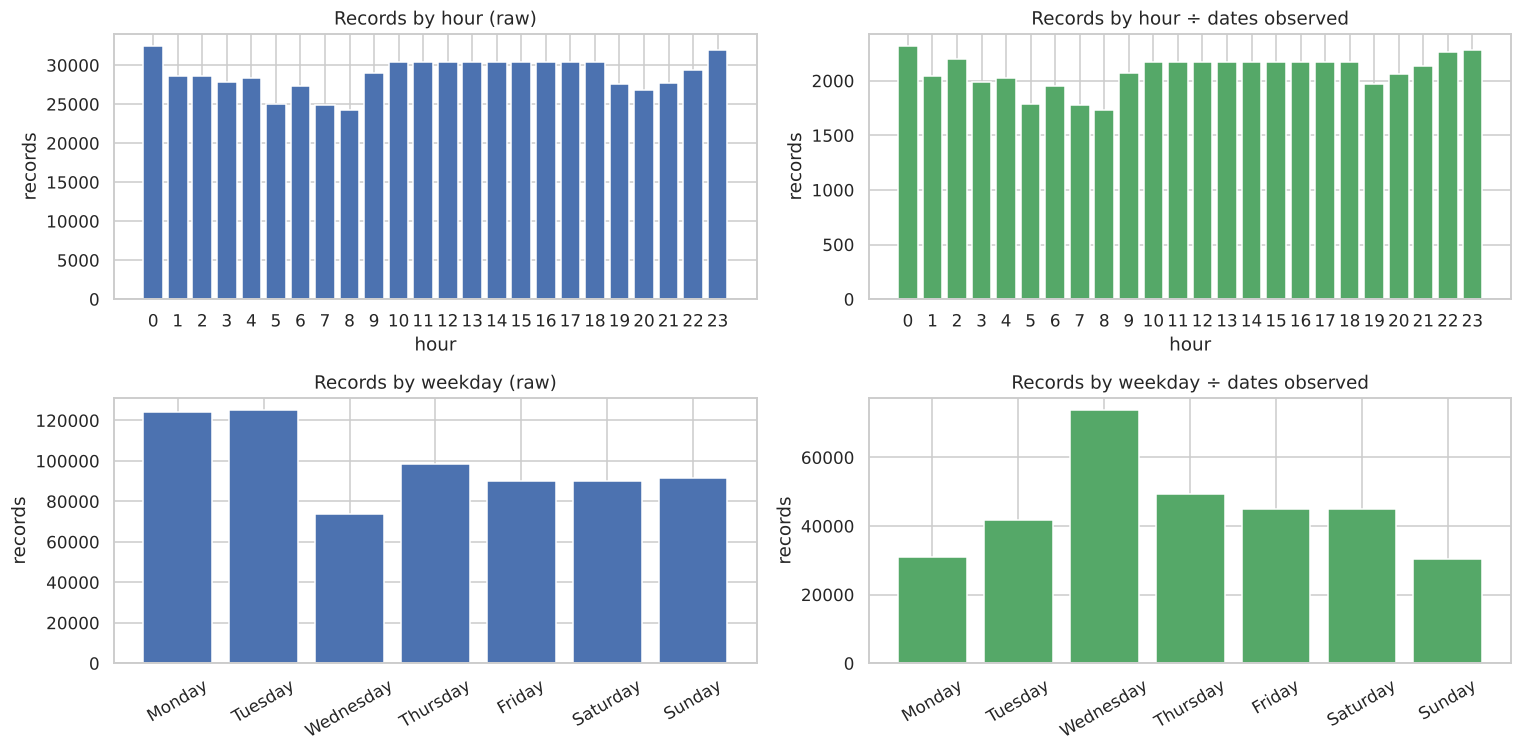

,records,dates,records per date
weekday,,,
Monday,124216,4,31054.0
Tuesday,124949,3,41650.0
Wednesday,73691,1,73691.0
Thursday,98505,2,49252.0
Friday,90012,2,45006.0
Saturday,90168,2,45084.0
Sunday,91530,3,30510.0


In [33]:
by_hour_cnt = df_all.groupby("hour").size()
hour_dates = df_all.groupby("hour")["date"].nunique()
by_wd_cnt = df_all.groupby("weekday", observed=False).size()
wd_dates = df_all.groupby("weekday", observed=False)["date"].nunique()

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
axes[0, 0].bar(by_hour_cnt.index, by_hour_cnt.values, color="#4C72B0"); axes[0, 0].set_title("Records by hour (raw)")
axes[0, 1].bar(by_hour_cnt.index, (by_hour_cnt / hour_dates).values, color="#55A868"); axes[0, 1].set_title("Records by hour ÷ dates observed")
axes[1, 0].bar(WEEKDAYS, by_wd_cnt.values, color="#4C72B0"); axes[1, 0].set_title("Records by weekday (raw)")
axes[1, 1].bar(WEEKDAYS, (by_wd_cnt / wd_dates).values, color="#55A868"); axes[1, 1].set_title("Records by weekday ÷ dates observed")
for a in axes[0]:
    a.set_xticks(range(24)); a.set_xlabel("hour")
for a in axes[1]:
    a.tick_params(axis="x", rotation=30)
for a in axes.flat:
    a.set_ylabel("records")
plt.tight_layout()
savefig("A2_9_hour_weekday")

pd.DataFrame({"records": by_wd_cnt, "dates": wd_dates, "records per date": (by_wd_cnt / wd_dates).round(0)})

Taken together, A-2.8 and A-2.9 look like a demand pattern at first (busy Tuesday nights, an empty early
Wednesday), but once you divide by the number of dates the picture is almost perfectly flat. Most cells
have exactly 1,872 records per date, which is 156 per zone per hour, and the only exceptions are a few
days (27 to 29 Nov) when the scraper ran faster. The empty Wednesday morning is just a gap in collection.

So no, this is not what you'd expect from real rides. Real demand would peak at commute times and on
Friday and Saturday nights. Here the counts tell us about the scraper, not about riders, and the same
applies to the OD matrices in Part B.

### A-2.10 Correlation matrix
Only real predictors go in. Anything computed from price (price per mile, for instance) would leak the
target. `name` enters through its tier code and `cab_type` as a 0/1 flag. We also show Spearman, since
price is skewed and some relationships are monotone without being linear.

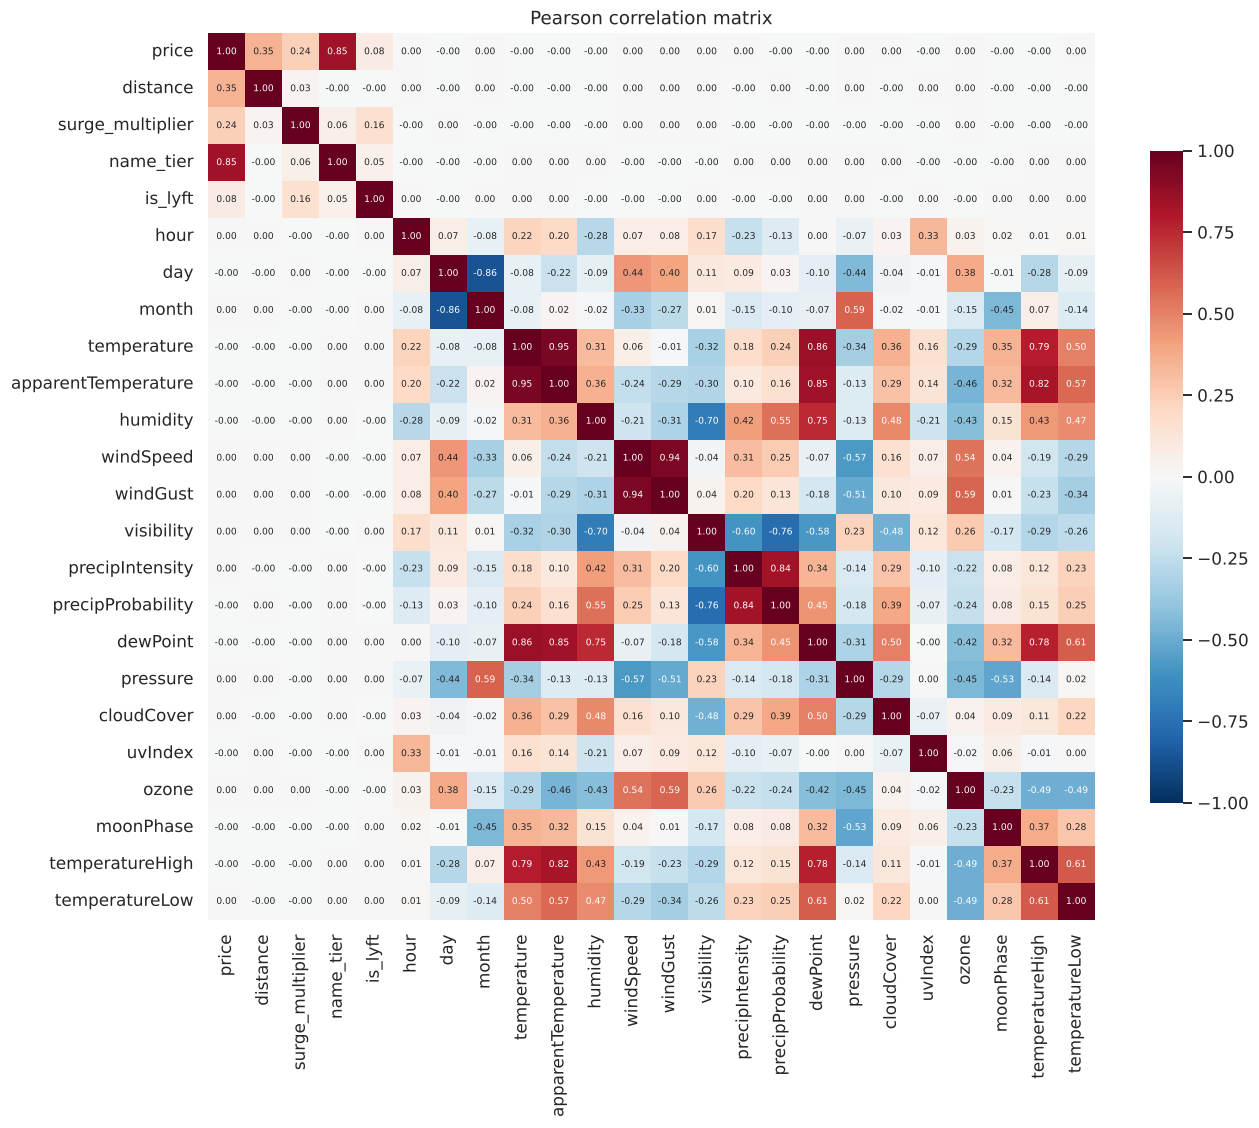

,Pearson,Spearman
name_tier,0.846,0.892
distance,0.345,0.334
surge_multiplier,0.240,0.166
is_lyft,0.083,0.069
moonPhase,-0.002,-0.002
visibility,0.001,0.001
humidity,-0.001,-0.001
windGust,0.001,0.001
windSpeed,0.001,0.001
month,0.001,0.001


In [34]:
corr_df = df[["price", "distance", "surge_multiplier", "name_tier", "hour", "day", "month",
              "temperature", "apparentTemperature", "humidity", "windSpeed", "windGust", "visibility",
              "precipIntensity", "precipProbability", "dewPoint", "pressure", "cloudCover", "uvIndex",
              "ozone", "moonPhase", "temperatureHigh", "temperatureLow"]].copy()
corr_df.insert(4, "is_lyft", (df["cab_type"] == "Lyft").astype(int))
pearson = corr_df.corr()
spearman = corr_df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(pearson, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 6}, square=True, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Pearson correlation matrix")
savefig("A2_10_corr_matrix")

target_corr = pd.DataFrame({"Pearson": pearson["price"], "Spearman": spearman["price"]}).drop("price")
target_corr = target_corr.reindex(target_corr["Pearson"].abs().sort_values(ascending=False).index)
target_corr.round(3)

In [35]:
# Highly inter-correlated weather variables (|r| > 0.9): redundant information
w_pairs = (pearson.where(np.triu(np.ones(pearson.shape, dtype=bool), 1)).stack()
           .rename("r").reset_index().query("abs(r) > 0.9").sort_values("r", key=abs, ascending=False))
w_pairs.round(3)

,level_0,level_1,r
201,temperature,apparentTemperature,0.946
276,windSpeed,windGust,0.938


Price is strongly correlated with the service tier (r ≈ 0.85), moderately with distance (≈ 0.35) and
weakly with surge (≈ 0.24). Every weather variable, the hour and the date have |r| < 0.01. Some weather
columns are near-duplicates (temperature and apparent temperature at 0.95, wind speed and gust at 0.94),
so they shouldn't all go into one linear model.

## A-3. Weather
The weather is recorded once per zone per hour and copied onto every quote in that hour, so the 693k
rows contain only 3,984 distinct weather observations. If we worked on the copies, each observation would
count thousands of times, and in A-3.2 copies of the same hour would land in both train and test. So this
section uses one row per (zone, hour).

In [36]:
WEATHER_NUM = ["temperature", "apparentTemperature", "precipIntensity", "precipProbability", "humidity",
               "windSpeed", "windGust", "visibility", "temperatureHigh", "temperatureLow",
               "apparentTemperatureHigh", "apparentTemperatureLow", "dewPoint", "pressure", "windBearing",
               "cloudCover", "uvIndex", "ozone", "moonPhase", "temperatureMin", "temperatureMax",
               "apparentTemperatureMin", "apparentTemperatureMax"]
weather = (df_all.drop_duplicates(["source", "datetime"])
           [["source", "datetime", "date", "hour", "short_summary", "long_summary"] + WEATHER_NUM]
           .reset_index(drop=True))
print("Distinct (zone, hour) weather observations:", len(weather), "from", len(df_all), "rows")
dupe_check = df_all.groupby(["source", "datetime"])[WEATHER_NUM].nunique().max().max()
print("Max distinct values of any weather variable inside one (zone, hour):", dupe_check)

Distinct (zone, hour) weather observations: 3984 from 693071 rows


Max distinct values of any weather variable inside one (zone, hour): 1


### A-3.1 Can PCA or clustering summarise the weather?
Yes. The 23 numeric weather columns overlap a lot (several versions of temperature, wind speed and gust,
and so on). We fit PCA on the standardised columns, leaving out the two precipitation columns so the
components can also be used to predict rain in A-3.2 without giving away the answer.

Explained variance of first 6 PCs: [0.471 0.161 0.097 0.059 0.05  0.041]
Components needed for 90% of variance: 7 (out of 21)


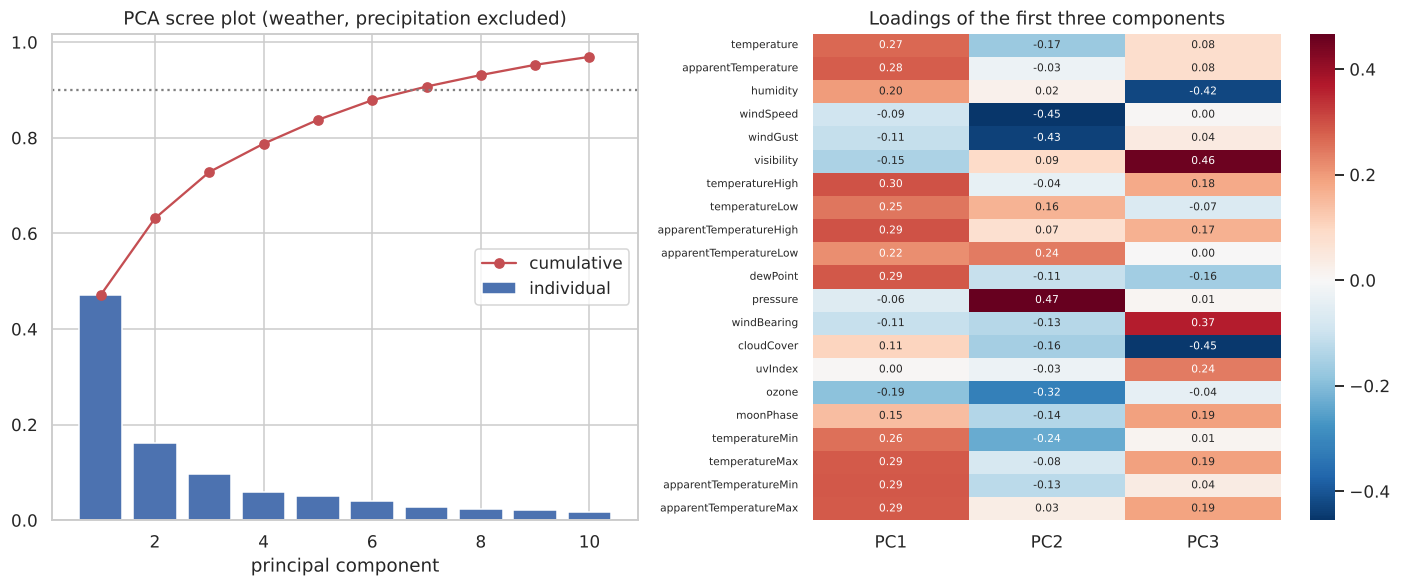

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

PCA_COLS = [c for c in WEATHER_NUM if c not in ("precipIntensity", "precipProbability")]
Zw = StandardScaler().fit_transform(weather[PCA_COLS])
pca_full = PCA(random_state=SEED).fit(Zw)
evr = pca_full.explained_variance_ratio_
n90 = int(np.searchsorted(np.cumsum(evr), 0.90) + 1)
print("Explained variance of first 6 PCs:", np.round(evr[:6], 3))
print(f"Components needed for 90% of variance: {n90} (out of {len(PCA_COLS)})")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].bar(range(1, 11), evr[:10], color="#4C72B0", label="individual")
axes[0].plot(range(1, 11), np.cumsum(evr[:10]), "o-", color="#C44E52", label="cumulative")
axes[0].axhline(0.9, ls=":", color="grey"); axes[0].set_xlabel("principal component"); axes[0].legend()
axes[0].set_title("PCA scree plot (weather, precipitation excluded)")
loadings = pd.DataFrame(pca_full.components_[:3].T, index=PCA_COLS, columns=["PC1", "PC2", "PC3"])
sns.heatmap(loadings, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, yticklabels=True, ax=axes[1])
axes[1].tick_params(axis="y", labelsize=7)
axes[1].set_title("Loadings of the first three components")
plt.tight_layout()
savefig("A3_1_pca")

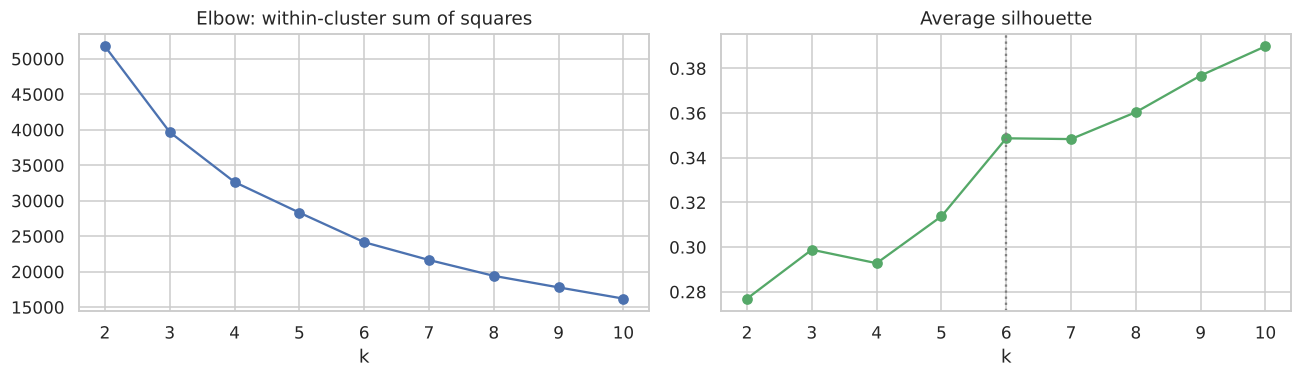

Silhouette by k: {2: 0.277, 3: 0.299, 4: 0.293, 5: 0.314, 6: 0.349, 7: 0.348, 8: 0.36, 9: 0.377, 10: 0.39}


In [38]:
pcs = PCA(n_components=n90, random_state=SEED).fit_transform(Zw)
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(pcs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(pcs, km.labels_, sample_size=3000, random_state=SEED))
best_k = list(ks)[int(np.argmax(sil))]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(list(ks), inertia, "o-"); axes[0].set_title("Elbow: within-cluster sum of squares"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), sil, "o-", color="#55A868"); axes[1].set_title("Average silhouette"); axes[1].set_xlabel("k")
axes[1].axvline(6, ls=":", color="grey")
plt.tight_layout()
savefig("A3_1_kmeans_k")
print("Silhouette by k:", {k: round(float(v), 3) for k, v in zip(ks, sil)})

In [39]:
# Silhouette keeps creeping up to k = 10 (no clear maximum), so it alone cannot pick k. The largest
# single jump happens at k = 6, after which gains are small and the elbow curve flattens; 6 clusters are
# also easy to interpret, so k = 6 is used.
K_WEATHER = 6
km = KMeans(n_clusters=K_WEATHER, n_init=10, random_state=SEED).fit(pcs)
weather["weather_cluster"] = km.labels_
profile = weather.groupby("weather_cluster").agg(
    n=("temperature", "size"), temperature=("temperature", "mean"), humidity=("humidity", "mean"),
    cloudCover=("cloudCover", "mean"), visibility=("visibility", "mean"), windSpeed=("windSpeed", "mean"),
    pressure=("pressure", "mean"), rain_share=("precipIntensity", lambda s: (s > 0).mean()))
print(profile.round(2))
pd.crosstab(weather["weather_cluster"], weather["short_summary"])

                    n  temperature  humidity  cloudCover  visibility  windSpeed  pressure  rain_share
weather_cluster                                                                                      
0                 816        44.48      0.92        1.00        4.59       4.81   1007.46        0.60
1                 360        27.06      0.60        0.42        9.90       3.12   1031.13        0.00
2                 912        36.72      0.72        0.47        9.83       3.35   1022.75        0.00
3                1236        39.69      0.73        0.73        8.92       8.18   1002.91        0.21
4                 180        28.85      0.50        0.59        9.24      13.08   1006.91        0.13
5                 480        48.30      0.72        0.53        9.67       5.37   1013.72        0.10


short_summary,Clear,Drizzle,Foggy,Light Rain,Mostly Cloudy,Overcast,Partly Cloudy,Possible Drizzle,Rain
weather_cluster,,,,,,,,,
0,0,12,72,228,0,360,0,72,72
1,144,0,0,0,84,72,60,0,0
2,276,0,0,0,216,204,216,0,0
3,72,36,0,60,300,456,252,36,24
4,36,0,0,0,60,60,24,0,0
5,72,0,0,0,108,144,156,0,0


The clusters make sense: a wet and foggy one (full cloud cover, visibility around 4.6 miles, rain in
60% of its hours), a cold dry high-pressure one (about 27°F, no rain), a windy one (about 13 mph), a mild
one (about 48°F) and a couple of in-between overcast or clear groups. The clustering finds these weather
types without being told anything about rain.

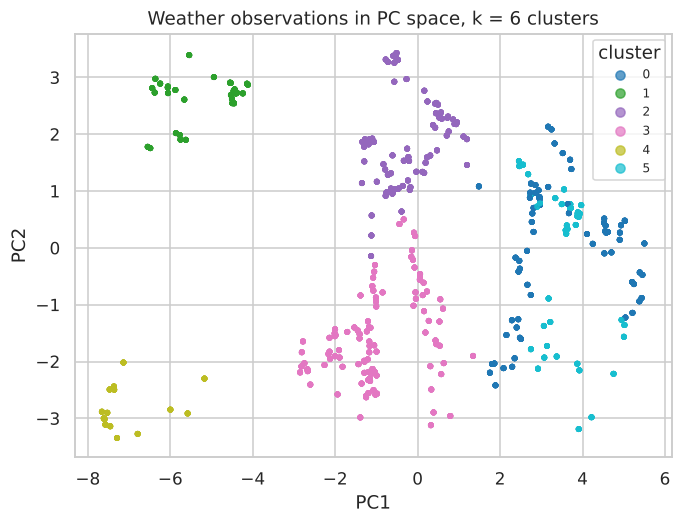

In [40]:
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(pcs[:, 0], pcs[:, 1], c=weather["weather_cluster"], cmap="tab10", s=8, alpha=0.7)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"Weather observations in PC space, k = {K_WEATHER} clusters")
ax.legend(*sc.legend_elements(), title="cluster", fontsize=8)
savefig("A3_1_clusters")

In [41]:
# Do the weather summaries help to predict price? Compare a price model with and without them.
wfeat = weather[["source", "datetime"]].copy()
for i in range(3):
    wfeat[f"wPC{i + 1}"] = pcs[:, i]
wfeat["weather_cluster"] = weather["weather_cluster"]
df = df.merge(wfeat, on=["source", "datetime"], how="left")
df_model = df_model.merge(wfeat, on=["source", "datetime"], how="left")

base_X = pd.concat([df_model[["distance", "surge_multiplier"]],
                    pd.get_dummies(df_model["name"], drop_first=True, dtype=int)], axis=1)
with_w = pd.concat([base_X, df_model[["wPC1", "wPC2", "wPC3"]],
                    pd.get_dummies(df_model["weather_cluster"], prefix="wc", drop_first=True, dtype=int)], axis=1)
for label, X in {"without weather": base_X, "with 3 weather PCs + cluster": with_w}.items():
    Xtr, Xte, ytr, yte = train_test_split(X, df_model["price"], test_size=0.2, random_state=SEED)
    p = LinearRegression().fit(Xtr, ytr).predict(Xte)
    print(f"{label:30s} R2 = {r2_score(yte, p):.5f}   MAE = {mean_absolute_error(yte, p):.4f}")

without weather                R2 = 0.94366   MAE = 1.5779


with 3 weather PCs + cluster   R2 = 0.94366   MAE = 1.5779


So PCA and clustering both summarise the weather well: 7 components keep 90% of the information in 21
columns, and the 6 clusters are easy to interpret. But adding them to a price model changes nothing (R²
is identical to five decimals). Weather has no measurable effect on these prices. We use the components
again in A-3.2, where weather is the actual subject.

### A-3.2 Predicting rain
Target: `rain = 1` if `precipIntensity > 0`.

The inputs must not contain the answer. `precipIntensity` is the target, `precipProbability` is almost the
same thing, and `short_summary` / `long_summary` literally say "Rain" or "Drizzle", so all of them are
out. The next cell shows what happens if you leave `precipProbability` in: a perfect and meaningless
score.

Zones next to each other have nearly the same weather in the same hour, so a random train/test split
would still leak. We use 5-fold cross-validation grouped by date instead, so every fold is tested on
days the model has never seen.

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, matthews_corrcoef, balanced_accuracy_score,
                             confusion_matrix, roc_curve, precision_recall_curve)

weather["rain"] = (weather["precipIntensity"] > 0).astype(int)
print("Rain share:", round(weather["rain"].mean(), 3), "| counts:", weather["rain"].value_counts().to_dict())

RAIN_FEATURES = PCA_COLS + ["hour"]               # no precipitation columns, no text summaries
X_rain, y_rain = weather[RAIN_FEATURES], weather["rain"]
cv_groups = weather["date"]
gkf = GroupKFold(n_splits=5)

# Leakage demonstration: include precipProbability
leaky = cross_val_predict(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
                          weather[RAIN_FEATURES + ["precipProbability"]], y_rain, cv=gkf, groups=cv_groups)
print("WITH precipProbability (leaky) -> accuracy %.3f, F1 %.3f" % (accuracy_score(y_rain, leaky), f1_score(y_rain, leaky)))

Rain share: 0.208 | counts: {0: 3156, 1: 828}


WITH precipProbability (leaky) -> accuracy 1.000, F1 1.000


In [43]:
rain_models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Logistic regression (PCs)": make_pipeline(StandardScaler(), PCA(n_components=n90, random_state=SEED),
                                               LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced",
                                            random_state=SEED, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                        class_weight="balanced", random_state=SEED),
}
# Rain is the minority class (21%), so the default 0.5 cut-off is not necessarily right. For each outer
# fold the threshold that maximises F1 is chosen with an inner grouped CV on the *training* days only,
# then applied to the unseen test days (nested, so no information from the test fold is used).
from sklearn.base import clone


def best_threshold(y, prob):
    grid = np.linspace(0.05, 0.95, 91)
    return grid[int(np.argmax([f1_score(y, prob >= t) for t in grid]))]


rain_proba, rain_pred, rain_thr = {}, {}, {}
for name, model in rain_models.items():
    proba = np.zeros(len(y_rain)); pred = np.zeros(len(y_rain), dtype=int); thrs = []
    for tr, te in gkf.split(X_rain, y_rain, cv_groups):
        inner = cross_val_predict(clone(model), X_rain.iloc[tr], y_rain.iloc[tr], cv=GroupKFold(4),
                                  groups=cv_groups.iloc[tr], method="predict_proba")[:, 1]
        t = best_threshold(y_rain.iloc[tr], inner)
        m = clone(model).fit(X_rain.iloc[tr], y_rain.iloc[tr])
        proba[te] = m.predict_proba(X_rain.iloc[te])[:, 1]
        pred[te] = (proba[te] >= t).astype(int)
        thrs.append(t)
    rain_proba[name], rain_pred[name], rain_thr[name] = proba, pred, np.mean(thrs)
print("Average tuned threshold per model:", {k: round(v, 2) for k, v in rain_thr.items()})

Average tuned threshold per model: {'Logistic regression': np.float64(0.38), 'Logistic regression (PCs)': np.float64(0.61), 'Random forest': np.float64(0.24), 'Gradient boosting': np.float64(0.39)}


### A-3.3 Confusion matrices and picking a model

In [44]:
def clf_report(y, p, prob):
    tn, fp, fn, tp = confusion_matrix(y, p).ravel()
    return {"accuracy": accuracy_score(y, p), "balanced acc.": balanced_accuracy_score(y, p),
            "precision": precision_score(y, p), "recall": recall_score(y, p), "specificity": tn / (tn + fp),
            "F1": f1_score(y, p), "MCC": matthews_corrcoef(y, p), "ROC-AUC": roc_auc_score(y, prob),
            "PR-AUC": average_precision_score(y, prob)}


rain_table = pd.DataFrame({n: clf_report(y_rain, rain_pred[n], rain_proba[n]) for n in rain_models}).T
baseline_acc = 1 - y_rain.mean()
print(f"Baseline (always predict 'no rain') accuracy = {baseline_acc:.3f}")
rain_table.round(3)

Baseline (always predict 'no rain') accuracy = 0.792


,accuracy,balanced acc.,precision,recall,specificity,F1,MCC,ROC-AUC,PR-AUC
Logistic regression,0.786,0.790,0.491,0.797,0.783,0.608,0.498,0.897,0.643
Logistic regression (PCs),0.792,0.789,0.500,0.783,0.795,0.610,0.500,0.891,0.650
Random forest,0.867,0.852,0.640,0.826,0.878,0.722,0.645,0.945,0.767
Gradient boosting,0.834,0.719,0.621,0.522,0.916,0.567,0.468,0.922,0.706


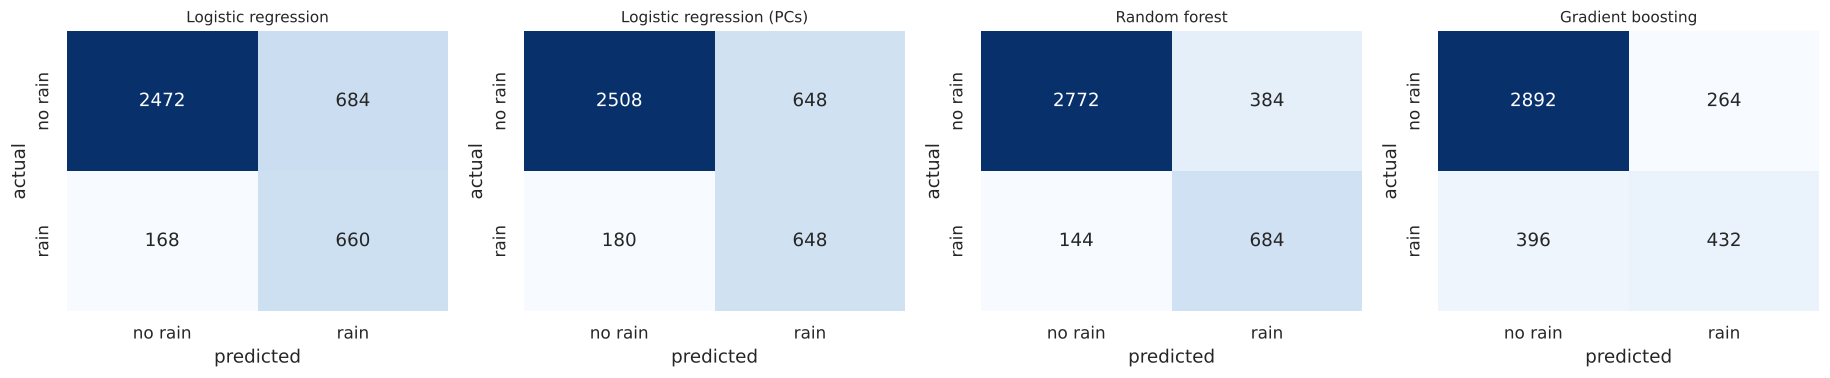

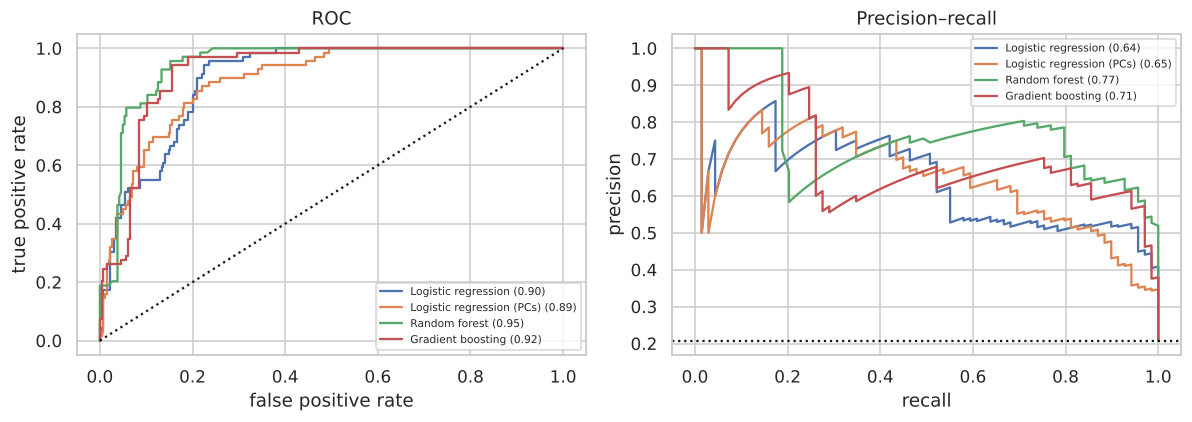

Best model by MCC / F1: Random forest


In [45]:
fig, axes = plt.subplots(1, len(rain_models), figsize=(4.2 * len(rain_models), 3.6))
for ax, name in zip(axes, rain_models):
    cm = confusion_matrix(y_rain, rain_pred[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no rain", "rain"], yticklabels=["no rain", "rain"])
    ax.set_title(name, fontsize=10); ax.set_xlabel("predicted"); ax.set_ylabel("actual")
plt.tight_layout()
savefig("A3_3_confusion")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in rain_models:
    fpr, tpr, _ = roc_curve(y_rain, rain_proba[name]); axes[0].plot(fpr, tpr, label=f"{name} ({rain_table.loc[name, 'ROC-AUC']:.2f})")
    pr, rc, _ = precision_recall_curve(y_rain, rain_proba[name]); axes[1].plot(rc, pr, label=f"{name} ({rain_table.loc[name, 'PR-AUC']:.2f})")
axes[0].plot([0, 1], [0, 1], "k:"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].set_title("ROC")
axes[1].axhline(y_rain.mean(), ls=":", color="k"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Precision–recall")
for a in axes:
    a.legend(fontsize=7)
plt.tight_layout()
savefig("A3_3_roc_pr")

best_rain = rain_table["MCC"].idxmax()
print("Best model by MCC / F1:", best_rain)

In [46]:
# Which weather variables does the forest rely on?
rf_rain = rain_models["Random forest"].fit(X_rain, y_rain)
imp_rain = pd.Series(rf_rain.feature_importances_, index=RAIN_FEATURES).sort_values(ascending=False)
imp_rain.head(10).round(3)

visibility                0.200
cloudCover                0.146
humidity                  0.142
dewPoint                  0.104
temperatureMin            0.045
windSpeed                 0.041
apparentTemperatureMin    0.040
windGust                  0.038
windBearing               0.036
pressure                  0.033
dtype: float64

Accuracy is the wrong yardstick here: always saying "no rain" already gets 79%. Precision, recall, F1,
MCC and PR-AUC focus on the rain class and are more honest. The random forest wins on nearly all of them:
F1 around 0.72, MCC around 0.65, ROC-AUC around 0.95. It catches about 83% of the rainy hours with a
specificity near 88%. Logistic regression has similar recall but far more false alarms (precision about
0.49). The forest leans mostly on visibility, cloud cover, humidity and dew point, which is what you
would expect physically.

## A-4. Feature selection and price models
The outlier-filtered data from A-2.7 has 616k rows, but it is very repetitive (the same route, product and
hour are quoted over and over), so we work with a random sample of 200,000 rows. It is split 80/20 once
and every model is scored on the same test rows.

Candidate inputs: distance, surge, hour, weekday, all weather variables and the three weather PCs from
A-3.1, plus one-hot `name`, `source`, `destination` and `short_summary`. `cab_type` is left out because
`name` already determines it.

In [47]:
import xgboost as xgb
from sklearn.feature_selection import mutual_info_regression, RFECV, f_regression
from sklearn.linear_model import LassoCV, Ridge
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error

MODEL_N = 200_000
dm = df_model.sample(n=MODEL_N, random_state=SEED).reset_index(drop=True)
dm["weekday_num"] = dm["datetime"].dt.dayofweek

NUM_FEATS = ["distance", "surge_multiplier", "hour", "weekday_num", "temperature", "apparentTemperature",
             "humidity", "windSpeed", "windGust", "visibility", "precipIntensity", "precipProbability",
             "dewPoint", "pressure", "windBearing", "cloudCover", "uvIndex", "ozone", "moonPhase",
             "wPC1", "wPC2", "wPC3"]
CAT_FEATS = ["name", "source", "destination", "short_summary"]
X_all = pd.concat([dm[NUM_FEATS],
                   pd.get_dummies(dm[CAT_FEATS], prefix=CAT_FEATS, prefix_sep="=", drop_first=True, dtype=float)],
                  axis=1)
# A column of pure random noise is added as a yardstick: a real feature should beat it clearly.
X_all["random_noise"] = rng.normal(size=len(X_all))
y_all = dm["price"].to_numpy()
idx_tr, idx_te = train_test_split(np.arange(len(dm)), test_size=0.2, random_state=SEED)
print("Candidate features after one-hot encoding:", X_all.shape[1])
print("Train rows:", len(idx_tr), "| test rows:", len(idx_te))

# Feature-selection methods run on a 40k subsample of the TRAIN rows only (the test set stays untouched).
fs_idx = rng.choice(idx_tr, size=40_000, replace=False)
X_fs, y_fs = X_all.iloc[fs_idx], y_all[fs_idx]
scaler_fs = StandardScaler().fit(X_fs)
X_fs_s = pd.DataFrame(scaler_fs.transform(X_fs), columns=X_all.columns)

Candidate features after one-hot encoding: 64
Train rows: 160000 | test rows: 40000


### A-4.1 Picking the useful columns, three ways
| Method | Type | Idea | Good | Not so good |
|---|---|---|---|---|
| Mutual information | filter | scores each column on its own: how much does knowing it tell you about price? | model-free, picks up non-linear relations, fast | ignores interactions and redundancy, noisy estimate |
| RFE with cross-validation (linear regression) | wrapper | fit, drop the weakest column, refit, and keep the subset with the best CV error | judges columns together, inside the model you'll actually use | lots of refits, depends on the chosen model |
| Lasso (L1) | embedded | the L1 penalty pushes useless coefficients to exactly zero | selection and fitting in one go, CV chooses the penalty | linear only, needs scaling, picks somewhat arbitrarily among correlated columns |

As a fourth check with a non-linear model we also compute random-forest permutation importance (how much
the error goes up when a column is shuffled). A column of pure random noise is added to the candidates
as a yardstick: anything useful should clearly beat it.

In [48]:
discrete = np.array([c.count("=") > 0 for c in X_all.columns])
mi = pd.Series(mutual_info_regression(X_fs.iloc[:20_000], y_fs[:20_000], discrete_features=discrete,
                                      random_state=SEED), index=X_all.columns)
f_stat, f_p = f_regression(X_fs, y_fs)

rfe = RFECV(make_pipeline(StandardScaler(), LinearRegression()), step=1, cv=3,
            scoring="neg_root_mean_squared_error", min_features_to_select=1,
            importance_getter="named_steps.linearregression.coef_", n_jobs=-1)
rfe.fit(X_fs, y_fs)

lasso = LassoCV(cv=3, random_state=SEED, n_jobs=-1).fit(X_fs_s, y_fs)
lasso_coef = pd.Series(lasso.coef_, index=X_all.columns)

rf_fs = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=0.5, random_state=SEED, n_jobs=-1)
rf_fs.fit(X_fs.iloc[:20_000], y_fs[:20_000])
perm = permutation_importance(rf_fs, X_fs.iloc[30_000:35_000], y_fs[30_000:35_000], n_repeats=3,
                              random_state=SEED, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_all.columns)

fs = pd.DataFrame({
    "MI": mi, "F-stat": f_stat, "RFE rank": rfe.ranking_, "Lasso |coef|": lasso_coef.abs(),
    "RF perm. imp.": perm_imp})
# Selection rules
#  * MI: at least 0.02 nats (the noise column scores ~0).
#  * RFE: RFECV's curve is very flat, so instead of the absolute minimum we keep the SMALLEST subset whose
#    CV error is within 1% of the best (a "one-standard-error"-style rule), then refit RFE with that size.
#  * Lasso: standardised coefficient of at least $0.05 per standard deviation (a practically visible effect).
k_1pct = int(np.argmax(-rfe.cv_results_["mean_test_score"] <= 1.01 * (-rfe.cv_results_["mean_test_score"]).min()) + 1)
from sklearn.feature_selection import RFE
rfe_k = RFE(make_pipeline(StandardScaler(), LinearRegression()), n_features_to_select=k_1pct, step=1,
            importance_getter="named_steps.linearregression.coef_").fit(X_fs, y_fs)
fs["RFE rank"] = rfe_k.ranking_
fs["MI ✓"] = fs["MI"] >= 0.02
fs["RFE ✓"] = fs["RFE rank"] == 1
fs["Lasso ✓"] = fs["Lasso |coef|"] >= 0.05
fs["votes (of 3)"] = fs[["MI ✓", "RFE ✓", "Lasso ✓"]].sum(axis=1)
fs = fs.sort_values(["votes (of 3)", "RF perm. imp."], ascending=False)
print(f"RFECV minimum at {rfe.n_features_} columns; smallest subset within 1% of best: {k_1pct} columns")
print(f"Lasso alpha = {lasso.alpha_:.4f}; columns with |coef| >= 0.05: {(lasso_coef.abs() >= 0.05).sum()}")
print("Noise column ->", fs.loc["random_noise", ["MI", "RFE rank", "Lasso |coef|", "RF perm. imp."]].round(4).to_dict())
fs.round(4).head(30)

RFECV minimum at 35 columns; smallest subset within 1% of best: 13 columns
Lasso alpha = 0.0043; columns with |coef| >= 0.05: 22
Noise column -> {'MI': 0.0, 'RFE rank': 48.0, 'Lasso |coef|': 0.0, 'RF perm. imp.': 0.0001}


,MI,F-stat,RFE rank,Lasso |coef|,RF perm. imp.,MI ✓,RFE ✓,Lasso ✓,votes (of 3)
name=Lux Black XL,0.1815,13243.3720,1,2.8772,0.3629,True,True,True,3
name=Black SUV,0.1889,11731.6210,1,2.6984,0.3351,True,True,True,3
name=Shared,0.2016,5570.1420,1,3.8960,0.2612,True,True,True,3
distance,0.4936,3955.2987,1,2.8651,0.2491,True,True,True,3
name=UberPool,0.1456,3130.7362,1,3.3011,0.2163,True,True,True,3
name=WAV,0.0912,2286.8674,1,2.9453,0.1529,True,True,True,3
name=UberX,0.0927,2292.7827,1,2.9598,0.1489,True,True,True,3
name=Lyft,0.1083,2161.6539,1,3.0464,0.1347,True,True,True,3
name=Lux Black,0.1157,2158.6944,1,0.5676,0.0786,True,True,True,3
name=Lyft XL,0.0967,65.1201,1,1.5118,0.0311,True,True,True,3


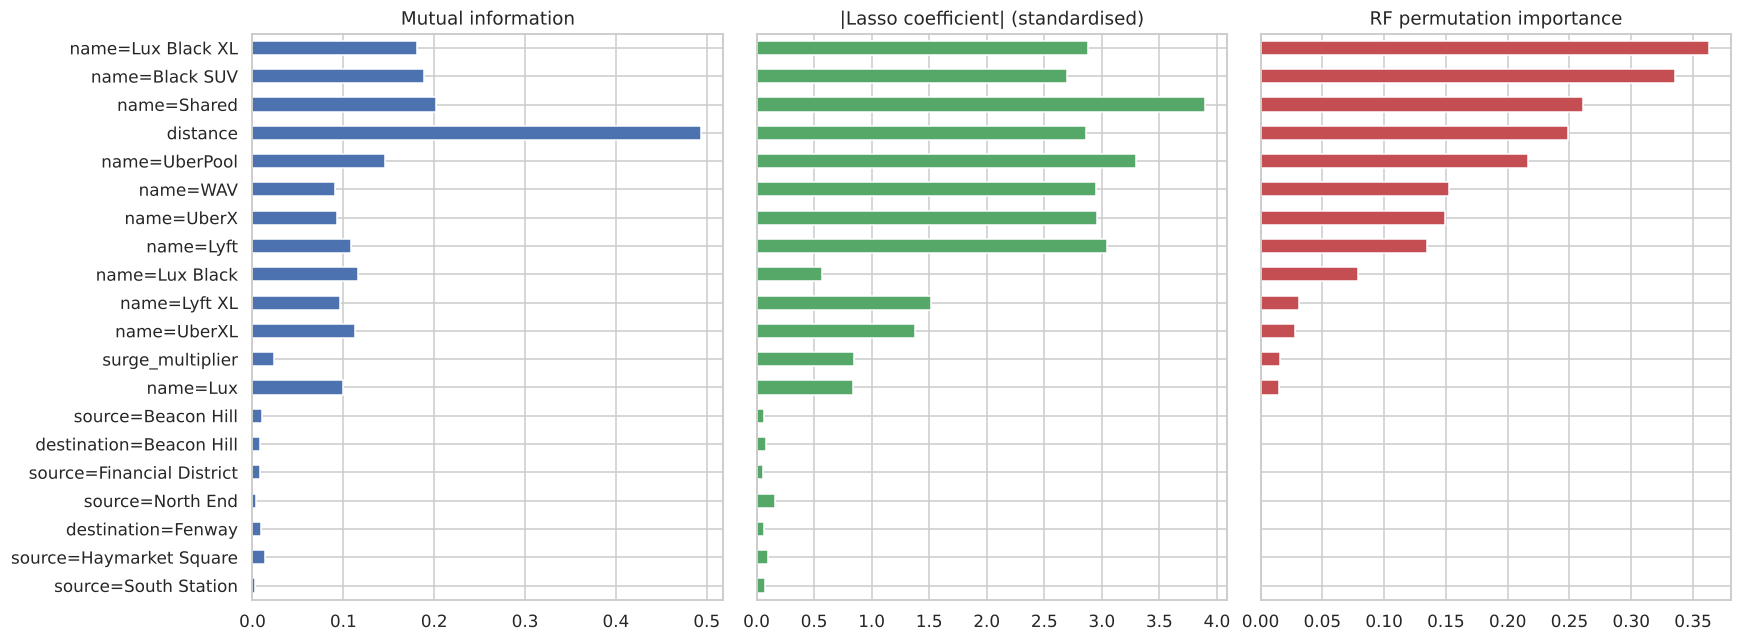

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
top = fs.index[:20]
fs.loc[top, "MI"].iloc[::-1].plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set_title("Mutual information")
fs.loc[top, "Lasso |coef|"].iloc[::-1].plot.barh(ax=axes[1], color="#55A868"); axes[1].set_title("|Lasso coefficient| (standardised)")
fs.loc[top, "RF perm. imp."].iloc[::-1].plot.barh(ax=axes[2], color="#C44E52"); axes[2].set_title("RF permutation importance")
for a in axes[1:]:
    a.set_yticklabels([])
plt.tight_layout()
savefig("A4_1_feature_selection")

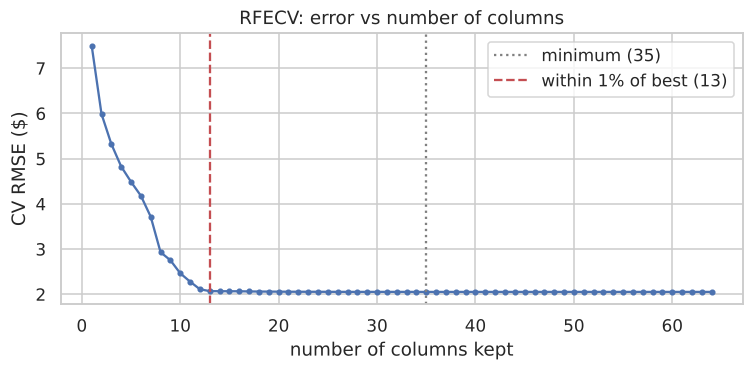

Columns chosen by at least 2 of the 3 methods (13):
['name=Lux Black XL', 'name=Black SUV', 'name=Shared', 'distance', 'name=UberPool', 'name=WAV', 'name=UberX', 'name=Lyft', 'name=Lux Black', 'name=Lyft XL', 'name=UberXL', 'surge_multiplier', 'name=Lux']
Weather columns among them: []


In [50]:
rfe_curve = -rfe.cv_results_["mean_test_score"]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(1, len(rfe_curve) + 1), rfe_curve, "o-", ms=3)
ax.axvline(rfe.n_features_, ls=":", color="grey", label=f"minimum ({rfe.n_features_})")
ax.axvline(k_1pct, ls="--", color="#C44E52", label=f"within 1% of best ({k_1pct})"); ax.legend()
ax.set_xlabel("number of columns kept"); ax.set_ylabel("CV RMSE ($)"); ax.set_title("RFECV: error vs number of columns")
savefig("A4_1_rfecv_curve")

SELECTED = fs.index[fs["votes (of 3)"] >= 2].tolist()
print(f"Columns chosen by at least 2 of the 3 methods ({len(SELECTED)}):")
print(SELECTED)
weather_like = [c for c in SELECTED if c in NUM_FEATS[4:] or c.startswith("short_summary")]
print("Weather columns among them:", weather_like)

All three methods pick the same 13 columns: distance, surge and the 11 service dummies. Source and
destination dummies get one vote at most (effects of a few cents), and no weather column survives any of
the methods. In the random-forest check they score no better than the noise column. The RFECV curve is
flat after about 13 columns, which is why the "within 1% of the best" rule stops there.

### A-4.2 Two linear models with different columns
* LR-A: distance, surge and the service dummies.
* LR-B: the columns from A-4.1 plus `service × distance`, `service × surge` and `distance × surge`. This is
  roughly how ride-hailing fares are built: each service has its own base fare and its own per-mile rate,
  and surge multiplies the lot.

We compare them on MAE (average error in dollars), RMSE (punishes big misses more) and R², with MAPE for
reference.

In [51]:
NAME_DUMMIES = [c for c in X_all.columns if c.startswith("name=")]


def add_interactions(X):
    X = X.copy()
    for c in NAME_DUMMIES:
        X[f"{c}×distance"] = X[c] * X["distance"]
        X[f"{c}×surge"] = X[c] * X["surge_multiplier"]
    X["distance×surge"] = X["distance"] * X["surge_multiplier"]
    return X


def regression_scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "MAPE %": np.mean(np.abs((y_true - y_pred) / y_true)) * 100}


FEATS_A = ["distance", "surge_multiplier"] + NAME_DUMMIES
FEATS_B = sorted(set(SELECTED) | set(FEATS_A), key=list(X_all.columns).index)
XA, XB = X_all[FEATS_A], add_interactions(X_all[FEATS_B])
y_tr, y_te = y_all[idx_tr], y_all[idx_te]

results, preds, fit_time = {}, {}, {}
for label, X in {"LR-A (basic)": XA, "LR-B (selected + interactions)": XB}.items():
    t0 = time.time()
    m = LinearRegression().fit(X.iloc[idx_tr], y_tr)
    fit_time[label] = time.time() - t0
    preds[label] = m.predict(X.iloc[idx_te])
    results[label] = regression_scores(y_te, preds[label])
    results[label]["n columns"] = X.shape[1]
lr_b = m
pd.DataFrame(results).T.round(4)

,MAE,RMSE,R2,MAPE %,n columns
LR-A (basic),1.5752,2.0619,0.9434,12.4082,13.0
LR-B (selected + interactions),1.1771,1.5766,0.9669,8.8848,36.0


LR-B wins on every metric (RMSE 1.58 vs 2.06 dollars, MAE 1.18 vs 1.58, R² 0.967 vs 0.943) even though
it uses exactly the same information. It just arranges it the way fares are actually computed.

### A-4.3 Random forest and XGBoost
Trees don't need dummies or interaction terms, so they get the same information in compact form:
distance, surge, the tier code, source and destination codes, hour and weekday.

In [52]:
dm["source_code"] = dm["source"].astype("category").cat.codes
dm["destination_code"] = dm["destination"].astype("category").cat.codes
TREE_FEATS = ["distance", "surge_multiplier", "name_tier", "source_code", "destination_code", "hour", "weekday_num"] \
    + [c for c in weather_like if c in dm.columns]
XT = dm[TREE_FEATS]
print("Tree inputs:", TREE_FEATS)

tree_models = {
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=0.7,
                                           random_state=SEED, n_jobs=-1),
    "XGBoost": xgb.XGBRegressor(n_estimators=500, max_depth=8, learning_rate=0.1, subsample=0.8,
                                colsample_bytree=0.9, tree_method="hist", random_state=SEED, n_jobs=-1),
}
fitted = {}
for label, model in tree_models.items():
    t0 = time.time()
    model.fit(XT.iloc[idx_tr], y_tr)
    fit_time[label] = time.time() - t0
    fitted[label] = model
    preds[label] = model.predict(XT.iloc[idx_te])
    results[label] = regression_scores(y_te, preds[label])
    results[label]["n columns"] = XT.shape[1]
pd.DataFrame(results).T.round(4)

Tree inputs: ['distance', 'surge_multiplier', 'name_tier', 'source_code', 'destination_code', 'hour', 'weekday_num']


,MAE,RMSE,R2,MAPE %,n columns
LR-A (basic),1.5752,2.0619,0.9434,12.4082,13.0
LR-B (selected + interactions),1.1771,1.5766,0.9669,8.8848,36.0
Random Forest,0.9642,1.3772,0.9748,7.5078,7.0
XGBoost,0.9495,1.3333,0.9763,7.3967,7.0


### A-4.4 All models side by side
Besides the single test split, every model also gets a 3-fold CV score on 40k training rows, to make sure
the ranking isn't down to a lucky split.

In [53]:
cv = KFold(3, shuffle=True, random_state=SEED)
cv_idx = idx_tr[:40_000]
cv_models = {
    "LR-A (basic)": (LinearRegression(), XA),
    "LR-B (selected + interactions)": (LinearRegression(), XB),
    "Random Forest": (clone(tree_models["Random Forest"]), XT),
    "XGBoost": (clone(tree_models["XGBoost"]), XT),
}
for label, (model, X) in cv_models.items():
    sc = -cross_val_score(model, X.iloc[cv_idx], y_all[cv_idx], cv=cv, scoring="neg_root_mean_squared_error")
    results[label]["CV RMSE (mean)"] = sc.mean()
    results[label]["CV RMSE (std)"] = sc.std()
    results[label]["fit time (s)"] = fit_time[label]
comparison = pd.DataFrame(results).T
comparison.round(4)

,MAE,RMSE,R2,MAPE %,n columns,CV RMSE (mean),CV RMSE (std),fit time (s)
LR-A (basic),1.5752,2.0619,0.9434,12.4082,13.0,2.0556,0.0126,0.0713
LR-B (selected + interactions),1.1771,1.5766,0.9669,8.8848,36.0,1.5656,0.0097,0.2948
Random Forest,0.9642,1.3772,0.9748,7.5078,7.0,1.4121,0.0128,17.2640
XGBoost,0.9495,1.3333,0.9763,7.3967,7.0,1.4471,0.0129,3.2994


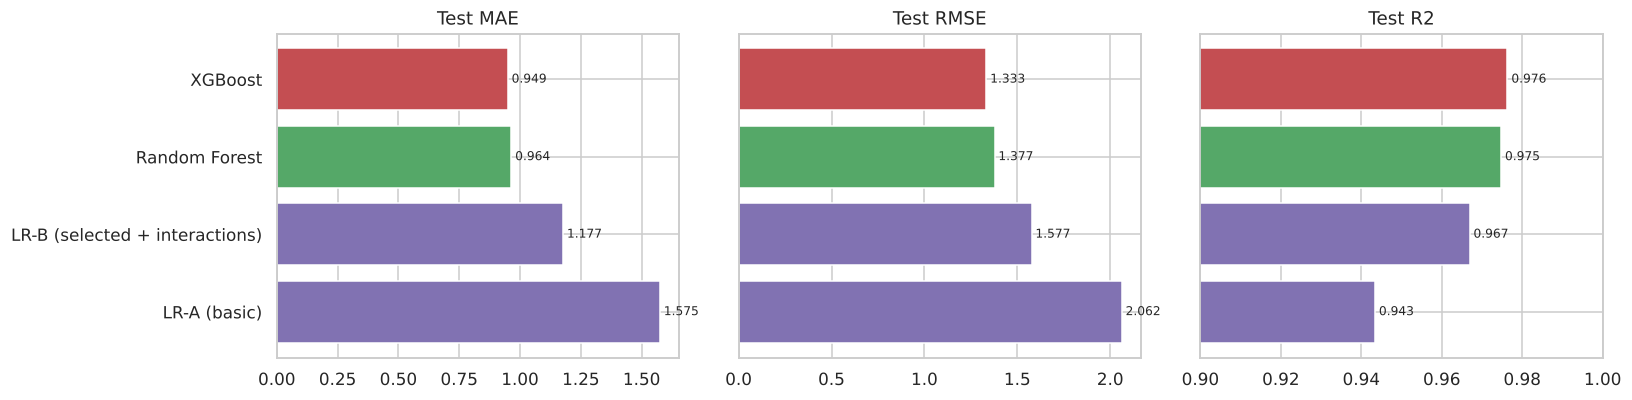

Best model on the test set: XGBoost


In [54]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, met in zip(axes, ["MAE", "RMSE", "R2"]):
    vals = comparison[met]
    ax.barh(vals.index, vals.values, color=["#8172B2", "#8172B2", "#55A868", "#C44E52"])
    for i, v in enumerate(vals.values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    ax.set_title(f"Test {met}")
    if met == "R2":
        ax.set_xlim(min(0.9, vals.min() - 0.01), 1.0)
for a in axes[1:]:
    a.set_yticklabels([])
plt.tight_layout()
savefig("A4_4_model_comparison")

best_44 = comparison["RMSE"].idxmin()
print("Best model on the test set:", best_44)

Both tree models beat the best linear model (test R² about 0.975, RMSE about 1.33 to 1.38 dollars) because
they learn the fare structure, including non-linear bits like minimum fares, on their own. XGBoost is
best on the test set and trains about five times faster than the forest; in CV the two are within one
standard deviation. We go with XGBoost. Part of the remaining error (MAE about 95 cents) can't be removed:
prices are rounded to 50 cents and the exact route length isn't in the data.

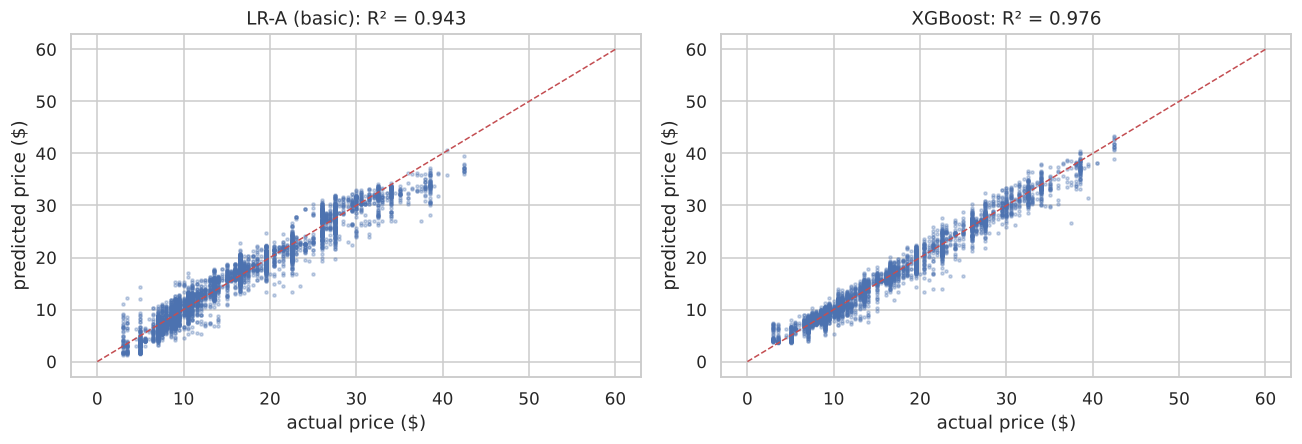

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sub = rng.choice(len(idx_te), min(5000, len(idx_te)), replace=False)
for ax, label in zip(axes, ["LR-A (basic)", best_44]):
    ax.scatter(y_te[sub], preds[label][sub], s=4, alpha=0.3)
    ax.plot([0, 60], [0, 60], "r--", lw=1)
    ax.set_xlabel("actual price ($)"); ax.set_ylabel("predicted price ($)")
    ax.set_title(f"{label}: R² = {results[label]['R2']:.3f}")
plt.tight_layout()
savefig("A4_4_pred_vs_actual")

### A-4.5 Tuning: Taguchi vs grid search
Both methods tune the same four XGBoost parameters at three levels each, scored by 3-fold CV RMSE on 30k
training rows:

| factor | level 1 | level 2 | level 3 |
|---|---|---|---|
| A `n_estimators` | 100 | 300 | 600 |
| B `max_depth` | 4 | 6 | 8 |
| C `learning_rate` | 0.03 | 0.1 | 0.3 |
| D `subsample` | 0.6 | 0.8 | 1.0 |

Grid search tries all 3⁴ = 81 combinations. Taguchi uses the L9(3⁴) orthogonal array, only 9 runs, chosen
so every level of every factor meets every level of every other factor equally often. For each run we
compute the smaller-the-better signal-to-noise ratio S/N = -10·log₁₀(mean(RMSE²)) over the folds, average
it per level to get the main effects, take the best level of each factor and confirm with one more run.
We do the same Taguchi run for the random forest (trees, depth, max_features, min_samples_leaf).

In [56]:
tune_idx = idx_tr[:30_000]
XT_tune, y_tune = XT.iloc[tune_idx], y_all[tune_idx]
cv3 = KFold(3, shuffle=True, random_state=SEED)

L9 = np.array([[1, 1, 1, 1], [1, 2, 2, 2], [1, 3, 3, 3],
               [2, 1, 2, 3], [2, 2, 3, 1], [2, 3, 1, 2],
               [3, 1, 3, 2], [3, 2, 1, 3], [3, 3, 2, 1]])
XGB_LEVELS = {"n_estimators": [100, 300, 600], "max_depth": [4, 6, 8],
              "learning_rate": [0.03, 0.1, 0.3], "subsample": [0.6, 0.8, 1.0]}


def cv_rmse_folds(model, X, y):
    return -cross_val_score(model, X, y, cv=cv3, scoring="neg_root_mean_squared_error")


def make_xgb(**p):
    return xgb.XGBRegressor(tree_method="hist", colsample_bytree=0.9, random_state=SEED, n_jobs=-1, **p)


def taguchi(levels, make_model, X, y):
    factors = list(levels)
    rows = []
    t0 = time.time()
    for run in L9:
        params = {f: levels[f][lvl - 1] for f, lvl in zip(factors, run)}
        folds = cv_rmse_folds(make_model(**params), X, y)
        rows.append({**params, "RMSE": folds.mean(), "S/N": -10 * np.log10(np.mean(folds ** 2))})
    elapsed = time.time() - t0
    runs = pd.DataFrame(rows)
    effects = pd.DataFrame({f: [runs.loc[L9[:, i] == l, "S/N"].mean() for l in (1, 2, 3)]
                            for i, f in enumerate(factors)}, index=["level 1", "level 2", "level 3"])
    ss = {f: 3 * ((effects[f] - runs["S/N"].mean()) ** 2).sum() for f in factors}
    contribution = pd.Series(ss) / sum(ss.values()) * 100
    best = {f: levels[f][int(np.argmax(effects[f]))] for f in factors}
    return runs, effects, contribution, best, elapsed


tg_runs, tg_effects, tg_contrib, tg_best, tg_time = taguchi(XGB_LEVELS, make_xgb, XT_tune, y_tune)
tg_conf = cv_rmse_folds(make_xgb(**tg_best), XT_tune, y_tune).mean()
print(tg_runs.round(4).to_string())
print("\nMain effects (mean S/N per level):\n", tg_effects.round(3))
print("\nContribution of each factor to S/N variation (%):\n", tg_contrib.round(1).to_string())
print(f"\nTaguchi optimum: {tg_best} -> confirmation CV RMSE = {tg_conf:.4f}  ({tg_time:.0f}s for 9 runs)")

   n_estimators  max_depth  learning_rate  subsample    RMSE     S/N
0           100          4           0.03        0.6  1.7014 -4.6160
1           100          6           0.10        0.8  1.3802 -2.7993
2           100          8           0.30        1.0  1.4486 -3.2192
3           300          4           0.10        1.0  1.3786 -2.7887
4           300          6           0.30        0.6  1.4933 -3.4830
5           300          8           0.03        0.8  1.3891 -2.8547
6           600          4           0.30        0.8  1.4052 -2.9552
7           600          6           0.03        1.0  1.3739 -2.7594
8           600          8           0.10        0.6  1.5055 -3.5538

Main effects (mean S/N per level):
          n_estimators  max_depth  learning_rate  subsample
level 1        -3.545     -3.453         -3.410     -3.884
level 2        -3.042     -3.014         -3.047     -2.870
level 3        -3.089     -3.209         -3.219     -2.922

Contribution of each factor to S/N v

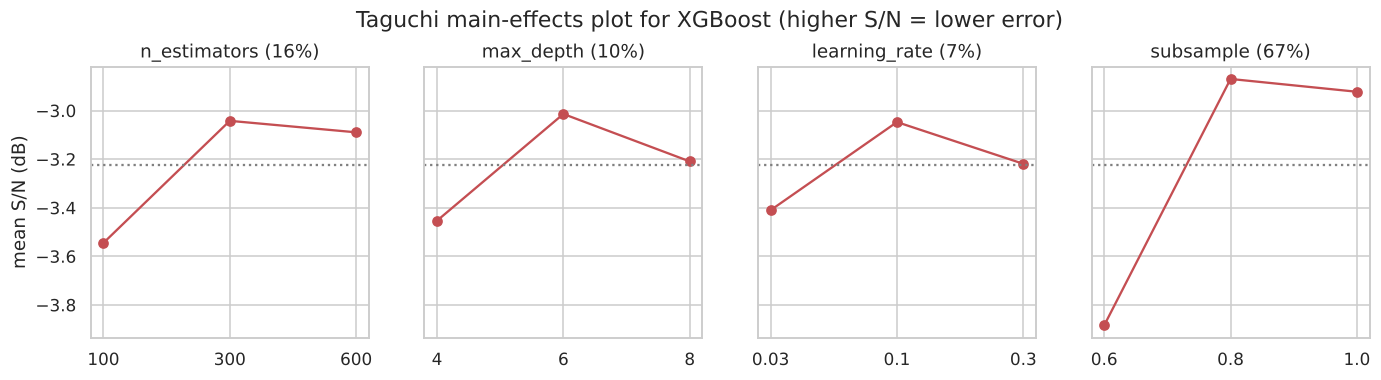

In [57]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, f in zip(axes, XGB_LEVELS):
    ax.plot([str(v) for v in XGB_LEVELS[f]], tg_effects[f], "o-", color="#C44E52")
    ax.set_title(f"{f} ({tg_contrib[f]:.0f}%)"); ax.axhline(tg_runs["S/N"].mean(), ls=":", color="grey")
axes[0].set_ylabel("mean S/N (dB)")
fig.suptitle("Taguchi main-effects plot for XGBoost (higher S/N = lower error)", y=1.04)
savefig("A4_5_taguchi_effects")

In [58]:
from sklearn.model_selection import GridSearchCV

t0 = time.time()
grid = GridSearchCV(make_xgb(), XGB_LEVELS, cv=cv3, scoring="neg_root_mean_squared_error", n_jobs=1)
grid.fit(XT_tune, y_tune)
grid_time = time.time() - t0
grid_res = pd.DataFrame(grid.cv_results_)
print(f"Grid search best: {grid.best_params_} -> CV RMSE = {-grid.best_score_:.4f}  ({grid_time:.0f}s for 81 runs)")
rank_of_taguchi = int((grid_res["mean_test_score"] > -tg_conf).sum()) + 1
print(f"The Taguchi optimum would rank #{rank_of_taguchi} of 81 in the full grid.")

Grid search best: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 600, 'subsample': 1.0} -> CV RMSE = 1.3719  (91s for 81 runs)
The Taguchi optimum would rank #17 of 81 in the full grid.


In [59]:
RF_LEVELS = {"n_estimators": [100, 200, 400], "max_depth": [10, 20, None],
             "max_features": [0.4, 0.7, 1.0], "min_samples_leaf": [1, 3, 10]}


def make_rf(**p):
    return RandomForestRegressor(random_state=SEED, n_jobs=-1, **p)


rf_runs, rf_effects, rf_contrib, rf_best, rf_tg_time = taguchi(RF_LEVELS, make_rf, XT_tune, y_tune)
rf_conf = cv_rmse_folds(make_rf(**rf_best), XT_tune, y_tune).mean()
print(rf_runs.round(4).to_string())
print("\nContribution (%):", rf_contrib.round(1).to_dict())
print(f"Taguchi optimum for RF: {rf_best} -> confirmation CV RMSE = {rf_conf:.4f} ({rf_tg_time:.0f}s)")

t0 = time.time()
rf_grid = GridSearchCV(make_rf(n_estimators=200), {"max_depth": [10, 20, None], "min_samples_leaf": [1, 3, 10]},
                       cv=cv3, scoring="neg_root_mean_squared_error", n_jobs=1).fit(XT_tune, y_tune)
rf_grid_time = time.time() - t0
print(f"RF grid (depth × leaf, 9 runs): {rf_grid.best_params_} -> CV RMSE = {-rf_grid.best_score_:.4f} ({rf_grid_time:.0f}s)")

   n_estimators  max_depth  max_features  min_samples_leaf    RMSE     S/N
0           100       10.0           0.4                 1  1.6979 -4.5984
1           100       20.0           0.7                 3  1.4074 -2.9685
2           100        NaN           1.0                10  1.4440 -3.1916
3           200       10.0           0.7                10  1.4370 -3.1497
4           200       20.0           1.0                 1  1.4653 -3.3184
5           200        NaN           0.4                 3  1.4900 -3.4640
6           400       10.0           1.0                 3  1.4115 -2.9940
7           400       20.0           0.4                10  1.6194 -4.1882
8           400        NaN           0.7                 1  1.4478 -3.2141

Contribution (%): {'n_estimators': 4.5, 'max_depth': 5.3, 'max_features': 70.6, 'min_samples_leaf': 19.7}
Taguchi optimum for RF: {'n_estimators': 200, 'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 3} -> confirmation CV RMSE = 1.4076 (

RF grid (depth × leaf, 9 runs): {'max_depth': 10, 'min_samples_leaf': 1} -> CV RMSE = 1.4102 (82s)


In [60]:
# Refit the tuned models on the full training set and score them on the test set
xgb_tuned = make_xgb(**grid.best_params_).fit(XT.iloc[idx_tr], y_tr)
xgb_taguchi = make_xgb(**tg_best).fit(XT.iloc[idx_tr], y_tr)
rf_tuned = make_rf(**rf_best).fit(XT.iloc[idx_tr], y_tr)
for label, model in {"XGBoost (grid-tuned)": xgb_tuned, "XGBoost (Taguchi-tuned)": xgb_taguchi,
                     "Random Forest (Taguchi-tuned)": rf_tuned}.items():
    preds[label] = model.predict(XT.iloc[idx_te])
    results[label] = regression_scores(y_te, preds[label])
    results[label]["n columns"] = XT.shape[1]

tuning_summary = pd.DataFrame({
    "method": ["XGB default (4-3)", "XGB Taguchi L9", "XGB full grid", "RF default (4-3)", "RF Taguchi L9", "RF grid (2 factors)"],
    "configurations tried": [1, 9, 81, 1, 9, 9],
    "tuning time (s)": [np.nan, tg_time, grid_time, np.nan, rf_tg_time, rf_grid_time],
    "CV RMSE (30k)": [cv_rmse_folds(clone(tree_models["XGBoost"]), XT_tune, y_tune).mean(), tg_conf, -grid.best_score_,
                      cv_rmse_folds(clone(tree_models["Random Forest"]), XT_tune, y_tune).mean(), rf_conf, -rf_grid.best_score_],
    "test RMSE": [results["XGBoost"]["RMSE"], results["XGBoost (Taguchi-tuned)"]["RMSE"], results["XGBoost (grid-tuned)"]["RMSE"],
                  results["Random Forest"]["RMSE"], results["Random Forest (Taguchi-tuned)"]["RMSE"], np.nan],
})
tuning_summary.round(4)

,method,configurations tried,tuning time (s),CV RMSE (30k),test RMSE
0,XGB default (4-3),1,NaN,1.4767,1.3333
1,XGB Taguchi L9,9,10.1075,1.3860,1.3362
2,XGB full grid,81,91.0444,1.3719,1.3544
3,RF default (4-3),1,NaN,1.4162,1.3772
4,RF Taguchi L9,9,63.1505,1.4076,1.3582
5,RF grid (2 factors),9,82.1877,1.4102,NaN


Taguchi found a good XGBoost setting in 9 runs and about 11 seconds. In the full grid it would rank 17th
of 81, only 0.014 dollars worse in CV RMSE than the grid's best, which took 81 runs and roughly ten times
as long. `subsample` was the most influential factor (about two thirds of the S/N variation). Taguchi
assumes the factors act independently; interactions such as more trees plus a higher learning rate are
why it doesn't land exactly on the grid optimum.

On the test set, tuning barely matters (everything within about 2 cents), and the grid's choice is even a
bit worse than the defaults, probably because it was tuned on a 30k slice. The defaults were already
close to what the noise in the data allows. For the random forest, `max_features` dominates and the
Taguchi setting lowers the test RMSE from 1.377 to 1.358.

### A-4.6 Hybrid models
We try three ways of combining models from the literature:

1. Stacking (Wolpert, 1992; Breiman, 1996): out-of-fold predictions of LR-B, the tuned random forest and
   the tuned XGBoost feed a ridge regression that learns how much to trust each one.
2. An optimally weighted average: non-negative weights that minimise the out-of-fold squared error.
3. Linear model plus boosting on the residuals, along the lines of Zhang (2003), who paired a linear
   time-series model with a neural network fitted to its residuals. Here LR-B captures the fare formula
   and XGBoost only learns what LR-B gets wrong.

In [61]:
from scipy.optimize import nnls

base_for_stack = {
    "LR-B": (LinearRegression(), XB),
    "RF (tuned)": (make_rf(**rf_best), XT),
    "XGB (tuned)": (make_xgb(**grid.best_params_), XT),
}
kf = KFold(3, shuffle=True, random_state=SEED)
oof = np.zeros((len(idx_tr), len(base_for_stack)))
test_level1 = np.zeros((len(idx_te), len(base_for_stack)))
for j, (label, (model, X)) in enumerate(base_for_stack.items()):
    for tr, va in kf.split(idx_tr):
        m = clone(model).fit(X.iloc[idx_tr[tr]], y_tr[tr])
        oof[va, j] = m.predict(X.iloc[idx_tr[va]])
    test_level1[:, j] = clone(model).fit(X.iloc[idx_tr], y_tr).predict(X.iloc[idx_te])

meta = Ridge(alpha=1.0).fit(oof, y_tr)
preds["Hybrid 1: stacking (ridge meta)"] = meta.predict(test_level1)
w, _ = nnls(oof, y_tr)
w = w / w.sum()
preds["Hybrid 2: weighted average"] = test_level1 @ w
print("Stacking meta-coefficients:", dict(zip(base_for_stack, np.round(meta.coef_, 3))), "intercept", round(meta.intercept_, 3))
print("Optimal average weights:  ", dict(zip(base_for_stack, np.round(w, 3))))

# Residual hybrid: XGB on the residuals of LR-B (residuals computed out-of-fold to avoid optimism)
lr_full = LinearRegression().fit(XB.iloc[idx_tr], y_tr)
resid_oof = y_tr - oof[:, 0]
xgb_resid = make_xgb(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8)
xgb_resid.fit(pd.concat([XT.iloc[idx_tr].reset_index(drop=True),
                         pd.Series(oof[:, 0], name="lr_pred")], axis=1), resid_oof)
lr_test = lr_full.predict(XB.iloc[idx_te])
preds["Hybrid 3: LR-B + XGB on residuals"] = lr_test + xgb_resid.predict(
    pd.concat([XT.iloc[idx_te].reset_index(drop=True), pd.Series(lr_test, name="lr_pred")], axis=1))

for label in ["Hybrid 1: stacking (ridge meta)", "Hybrid 2: weighted average", "Hybrid 3: LR-B + XGB on residuals"]:
    results[label] = regression_scores(y_te, preds[label])

final = pd.DataFrame(results).T[["MAE", "RMSE", "R2", "MAPE %"]].sort_values("RMSE")
final.round(4)

Stacking meta-coefficients: {'LR-B': np.float64(-0.035), 'RF (tuned)': np.float64(0.389), 'XGB (tuned)': np.float64(0.646)} intercept -0.008
Optimal average weights:   {'LR-B': np.float64(0.0), 'RF (tuned)': np.float64(0.391), 'XGB (tuned)': np.float64(0.609)}


,MAE,RMSE,R2,MAPE %
XGBoost,0.9495,1.3333,0.9763,7.3967
Hybrid 1: stacking (ridge meta),0.9550,1.3352,0.9763,7.4161
Hybrid 2: weighted average,0.9561,1.3355,0.9763,7.4289
XGBoost (Taguchi-tuned),0.9615,1.3362,0.9762,7.4831
Hybrid 3: LR-B + XGB on residuals,0.9655,1.3412,0.9761,7.5080
XGBoost (grid-tuned),0.9795,1.3544,0.9756,7.5988
Random Forest (Taguchi-tuned),0.9533,1.3582,0.9754,7.4212
Random Forest,0.9642,1.3772,0.9748,7.5078
LR-B (selected + interactions),1.1771,1.5766,0.9669,8.8848
LR-A (basic),1.5752,2.0619,0.9434,12.4082


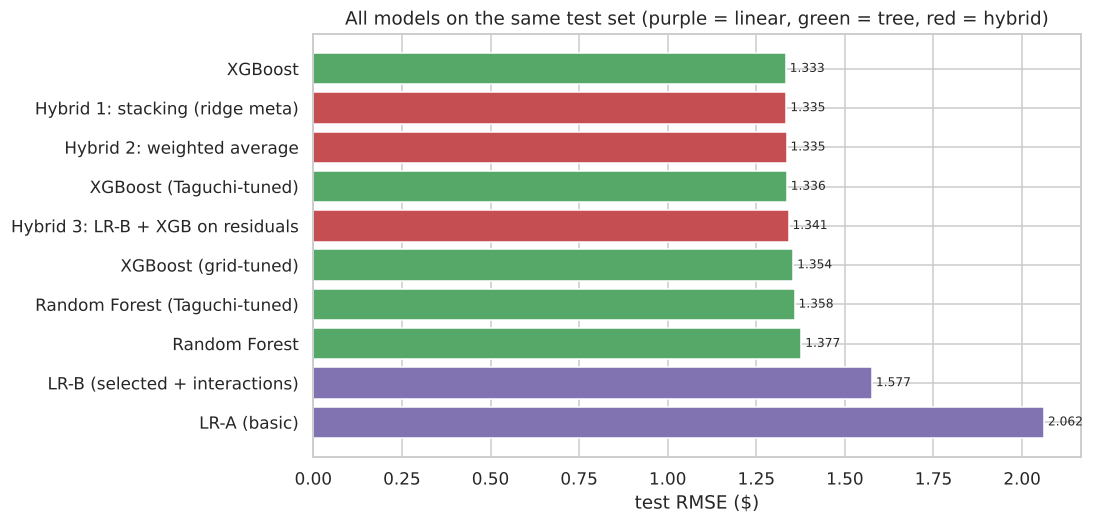

Best overall: XGBoost {'MAE': 0.9495, 'RMSE': 1.3333, 'R2': 0.9763, 'MAPE %': 7.3967}


In [62]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#C44E52" if "Hybrid" in i else "#55A868" if ("XGB" in i or "Forest" in i) else "#8172B2" for i in final.index]
ax.barh(final.index[::-1], final["RMSE"][::-1], color=colors[::-1])
for i, v in enumerate(final["RMSE"][::-1]):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
ax.set_xlabel("test RMSE ($)"); ax.set_title("All models on the same test set (purple = linear, green = tree, red = hybrid)")
savefig("A4_6_all_models")

best_final = final.index[0]
print("Best overall:", best_final, final.loc[best_final].round(4).to_dict())

In [63]:
# Residual check of the best model: where are the remaining errors?
res_best = y_te - preds[best_final]
err = pd.DataFrame({"name": dm["name"].iloc[idx_te].values, "surge": dm["surge_multiplier"].iloc[idx_te].values,
                    "abs_err": np.abs(res_best)})
print("Mean absolute error by surge level:\n", err.groupby("surge")["abs_err"].agg(["mean", "size"]).round(3).to_string())
print("\nMean absolute error by service:\n", err.groupby("name")["abs_err"].mean().sort_values().round(3).to_string())

Mean absolute error by surge level:
         mean   size
surge              
1.00   0.945  39023
1.25   1.081    644
1.50   1.171    225
1.75   1.097     71
2.00   1.682     36
2.50   5.339      1

Mean absolute error by service:
 name
Lyft            0.541
WAV             0.723
UberX           0.755
UberPool        0.801
Lyft XL         0.851
Lux             0.897
Lux Black       0.973
Shared          1.056
Black           1.148
UberXL          1.183
Black SUV       1.206
Lux Black XL    1.248


The hybrids are as good as XGBoost but not better (stacking RMSE 1.335 vs 1.333). The ridge meta-model
puts about 0.65 on XGBoost, 0.39 on the forest and nothing on LR-B. Combining helps when the base models
make different mistakes, and here the forest and XGBoost make almost the same ones. We keep plain XGBoost
since it's the simplest of the top group. Errors grow with surge and with how expensive the service is,
as you'd expect.

References for A-4.6

* Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241-259.
* Breiman, L. (1996). Stacked regressions. *Machine Learning*, 24(1), 49-64.
* Zhang, G. P. (2003). Time series forecasting using a hybrid ARIMA and neural network model. *Neurocomputing*, 50, 159-175.
* Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.
* Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proc. KDD 2016*, 785-794.
* Taguchi, G., Chowdhury, S., & Wu, Y. (2005). *Taguchi's Quality Engineering Handbook*. Wiley.

In [64]:
TOL = 0.01          # default error (1%)
MAX_ITER = 1000     # default iteration cap

df = raw.copy()
for c in ["source", "destination", "name", "cab_type"]:
    df[c] = df[c].str.strip()
df["datetime"] = pd.to_datetime(dict(year=2018, month=df["month"], day=df["day"], hour=df["hour"]))
df["date"] = df["datetime"].dt.normalize()
df["weekday"] = pd.Categorical(df["datetime"].dt.day_name(), categories=WEEKDAYS, ordered=True)
ZONES = sorted(df["source"].unique())
print(df.shape, "| zones:", len(ZONES), "| dates:", df["date"].nunique())

(693071, 42) | zones: 12 | dates: 17


---
# Part B: Phase 2
The phase 2 statement asks for the raw data with no cleaning, so this part starts again from `raw`
(Taxi rows included).

## B-1. OD matrices
### B-1.1 Overall OD matrix

Total trips (records): 693071 | non-zero cells: 72 of 144


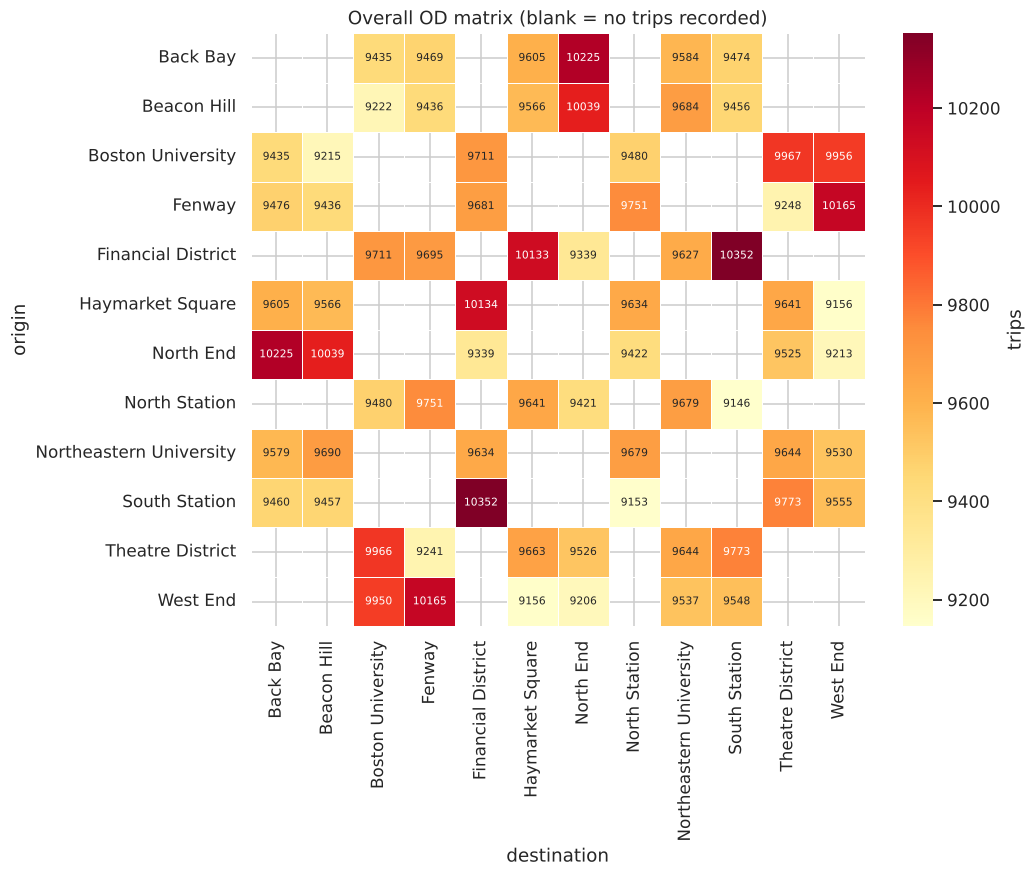

destination,Back Bay,Beacon Hill,Boston University,Fenway,Financial District,Haymarket Square,North End,North Station,Northeastern University,South Station,Theatre District,West End
source,,,,,,,,,,,,
Back Bay,0,0,9435,9469,0,9605,10225,0,9584,9474,0,0
Beacon Hill,0,0,9222,9436,0,9566,10039,0,9684,9456,0,0
Boston University,9435,9215,0,0,9711,0,0,9480,0,0,9967,9956
Fenway,9476,9436,0,0,9681,0,0,9751,0,0,9248,10165
Financial District,0,0,9711,9695,0,10133,9339,0,9627,10352,0,0
Haymarket Square,9605,9566,0,0,10134,0,0,9634,0,0,9641,9156
North End,10225,10039,0,0,9339,0,0,9422,0,0,9525,9213
North Station,0,0,9480,9751,0,9641,9421,0,9679,9146,0,0
Northeastern University,9579,9690,0,0,9634,0,0,9679,0,0,9644,9530


In [65]:
od = pd.crosstab(df["source"], df["destination"]).reindex(index=ZONES, columns=ZONES, fill_value=0)
print("Total trips (records):", int(od.values.sum()), "| non-zero cells:", int((od > 0).sum().sum()), "of", od.size)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(od.replace(0, np.nan), annot=True, fmt=".0f", cmap="YlOrRd", annot_kws={"size": 7},
            linewidths=0.5, cbar_kws={"label": "trips"}, ax=ax)
ax.set_title("Overall OD matrix (blank = no trips recorded)"); ax.set_xlabel("destination"); ax.set_ylabel("origin")
savefig("B1_od_all")
od

Same structure as in A-1.2: two groups of six zones, trips only between the groups, so 60 of the 144
cells (diagonal included) are structurally zero. Every non-zero cell has between 9.1k and 10.4k trips.

### B-1.2 One OD matrix per weekday
The 17 dates are spread unevenly over the week (Monday 4, Wednesday 1, and so on), so raw weekday totals
mostly reflect how many dates of each weekday the file has. We compare the matrices as average trips per
date, and as shares (each matrix divided by its own total), which takes size out of the picture and
leaves only the pattern.

In [66]:
dates_per_wd = df.groupby("weekday", observed=False)["date"].nunique()
od_wd = {d: pd.crosstab(g["source"], g["destination"]).reindex(index=ZONES, columns=ZONES, fill_value=0)
         for d, g in df.groupby("weekday", observed=False)}
od_wd_avg = {d: m / dates_per_wd[d] for d, m in od_wd.items()}
od_wd_share = {d: m / m.values.sum() for d, m in od_wd.items()}

wd_summary = pd.DataFrame({
    "dates": dates_per_wd,
    "total trips": {d: int(m.values.sum()) for d, m in od_wd.items()},
    "avg trips per date": {d: round(m.values.sum(), 0) for d, m in od_wd_avg.items()},
    "busiest pair": {d: " → ".join(m.stack().idxmax()) for d, m in od_wd.items()},
})
wd_summary

,dates,total trips,avg trips per date,busiest pair
Monday,4,124216,31054.0,Financial District → South Station
Tuesday,3,124949,41650.0,North End → Back Bay
Wednesday,1,73691,73691.0,Beacon Hill → North End
Thursday,2,98505,49252.0,Beacon Hill → South Station
Friday,2,90012,45006.0,South Station → Financial District
Saturday,2,90168,45084.0,Fenway → West End
Sunday,3,91530,30510.0,West End → Fenway


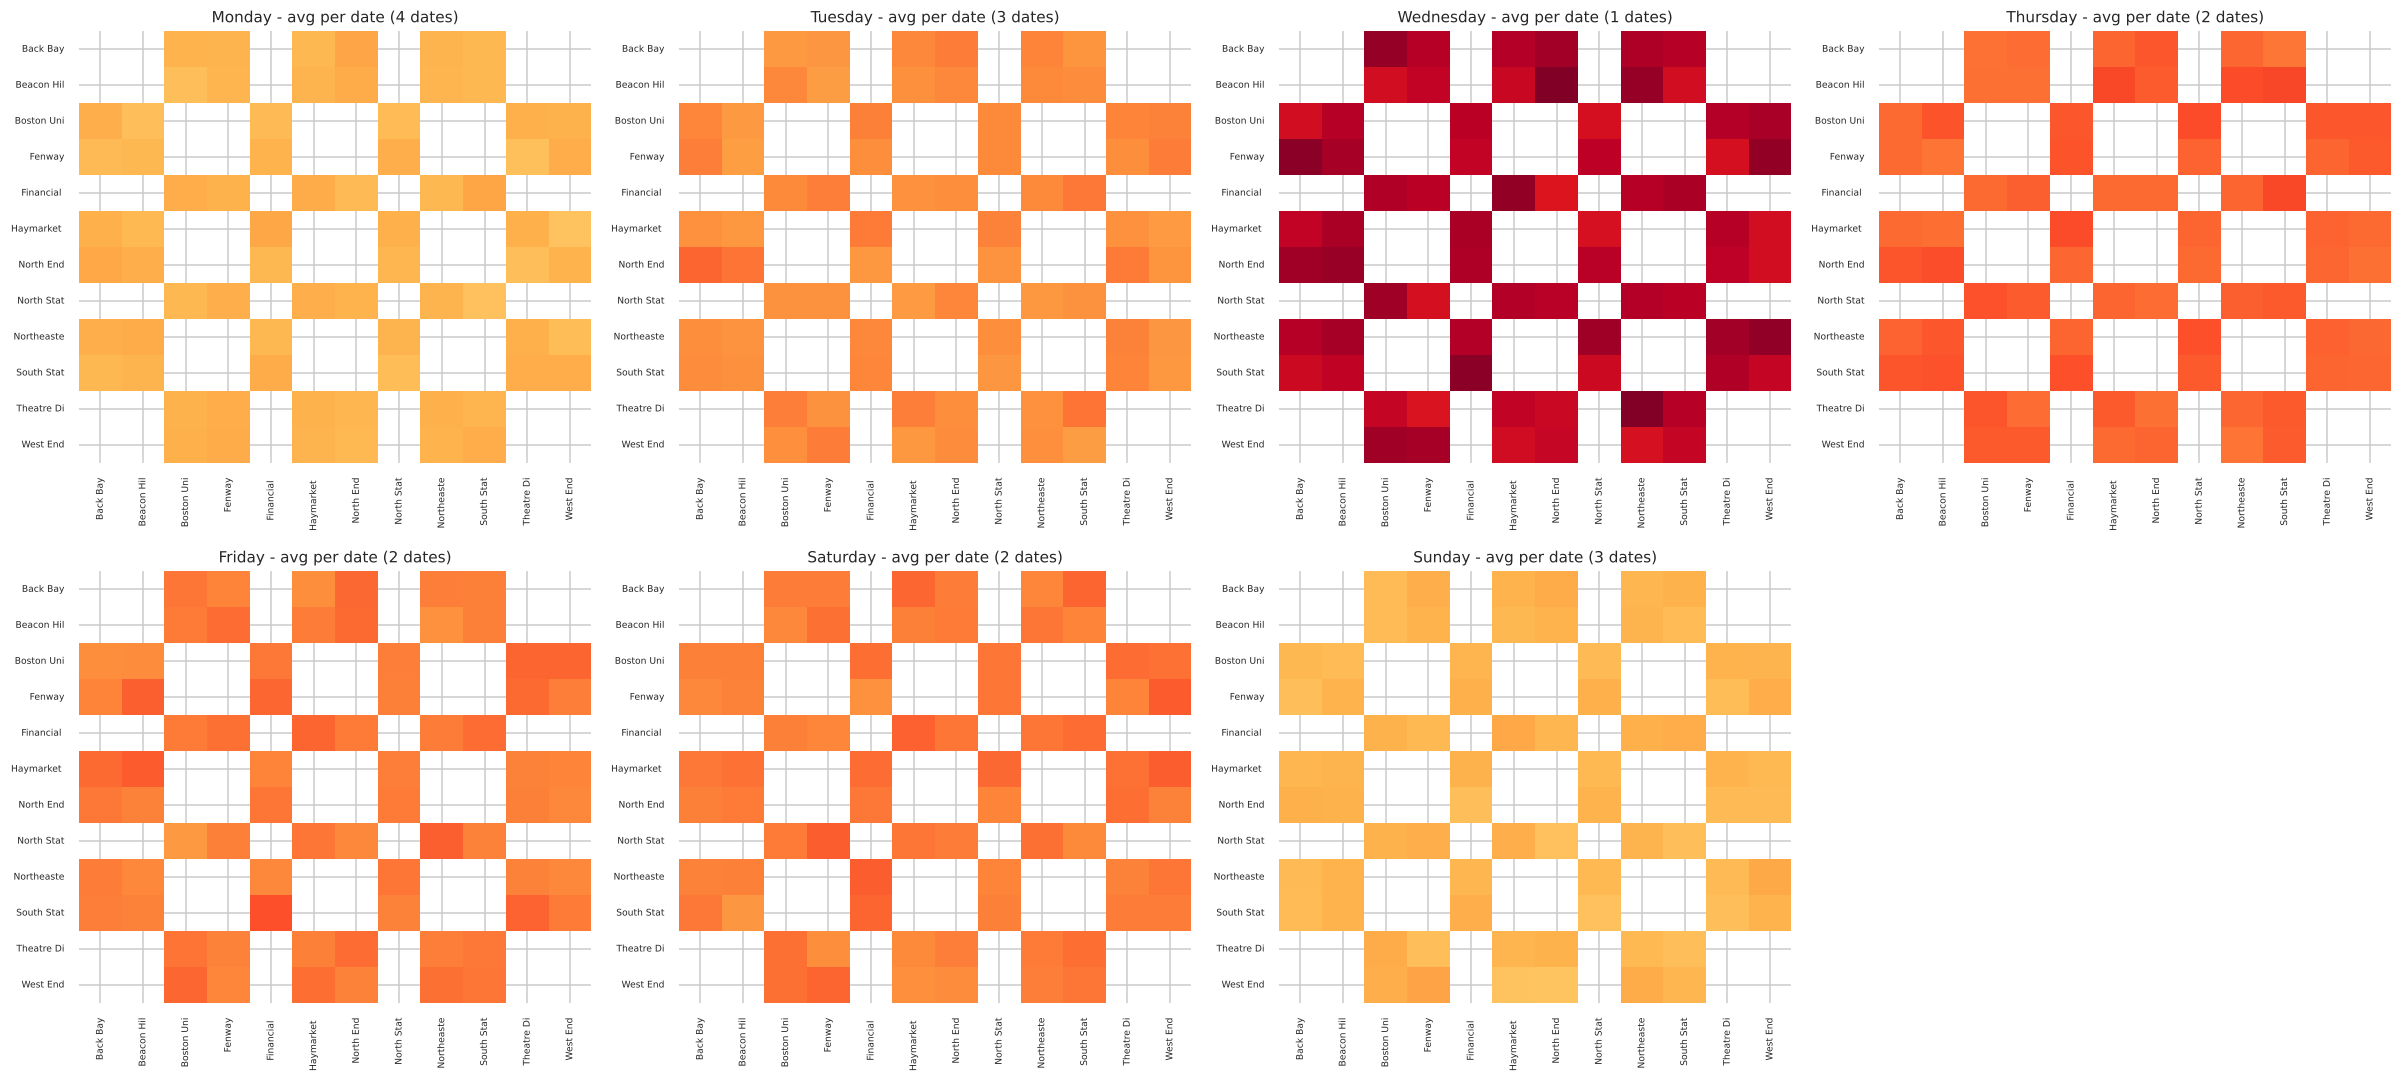

In [67]:
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
vmax = max(m.values.max() for m in od_wd_avg.values())
for ax, d in zip(axes.flat, WEEKDAYS):
    sns.heatmap(od_wd_avg[d].replace(0, np.nan), cmap="YlOrRd", vmin=0, vmax=vmax, cbar=False, ax=ax,
                xticklabels=[z[:10] for z in ZONES], yticklabels=[z[:10] for z in ZONES])
    ax.set_title(f"{d} - avg per date ({dates_per_wd[d]} dates)", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(labelsize=6)
axes.flat[-1].axis("off")
plt.tight_layout()
savefig("B1_od_weekdays")

Correlation between weekday share matrices: min -0.081, mean 0.194
Largest difference in any cell share between two weekdays: 0.325 percentage points
Chi-square homogeneity: chi2 = 1,374, dof = 426, p = 3.47e-100, Cramér's V = 0.0182


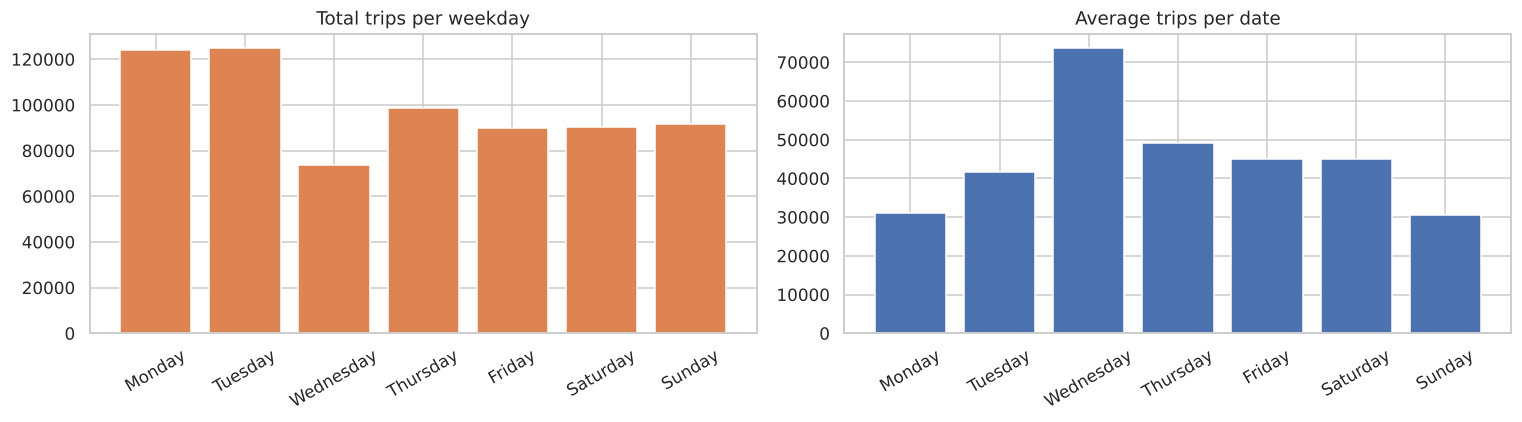

In [68]:
# Are the seven patterns different? (1) correlation of share matrices, (2) largest share difference,
# (3) chi-square test of homogeneity on the counts of the 84 non-zero cells.
mask = od.values > 0
share_vec = pd.DataFrame({d: od_wd_share[d].values[mask] for d in WEEKDAYS})
corr_wd = share_vec.corr()
max_diff = pd.DataFrame({a: {b: np.abs(share_vec[a] - share_vec[b]).max() * 100 for b in WEEKDAYS} for a in WEEKDAYS})
counts = np.array([od_wd[d].values[mask] for d in WEEKDAYS])
chi2, chi_p, chi_dof, _ = stats.chi2_contingency(counts)
cramers_v = np.sqrt(chi2 / (counts.sum() * (min(counts.shape) - 1)))
print(f"Correlation between weekday share matrices: min {corr_wd.values[np.triu_indices(7, 1)].min():.3f}, "
      f"mean {corr_wd.values[np.triu_indices(7, 1)].mean():.3f}")
print(f"Largest difference in any cell share between two weekdays: {max_diff.values.max():.3f} percentage points")
print(f"Chi-square homogeneity: chi2 = {chi2:,.0f}, dof = {chi_dof}, p = {chi_p:.2e}, Cramér's V = {cramers_v:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(WEEKDAYS, wd_summary["total trips"], color="#DD8452"); axes[0].set_title("Total trips per weekday")
axes[1].bar(WEEKDAYS, wd_summary["avg trips per date"], color="#4C72B0"); axes[1].set_title("Average trips per date")
for a in axes:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
savefig("B1_weekday_totals")

Is there a clear difference between the seven matrices? In size, yes, but it's an artefact. The average
per date goes from about 30k (Sunday, Monday) to 74k (Wednesday) only because the scraper ran at
different speeds on different dates, and the one Wednesday in the file (28 Nov) was a fast day. In
pattern, no: every weekday has the same 72 active cells and no cell's share differs by more than about
0.33 percentage points between any two days. The chi-square test is significant, but with 693k records
anything is; Cramér's V of 0.018 says the link between weekday and OD cell is negligible. The "busiest
pair" changes from day to day only because all pairs are within a few percent of each other.

### B-1.3 Are origins and destinations balanced?

In [69]:
bal = pd.DataFrame({"outflow (row sum)": od.sum(axis=1), "inflow (column sum)": od.sum(axis=0)})
bal["inflow − outflow"] = bal["inflow (column sum)"] - bal["outflow (row sum)"]
bal["imbalance %"] = (bal["inflow − outflow"] / bal["outflow (row sum)"] * 100).round(3)
print("Balanced zones:", int((bal["inflow − outflow"] == 0).sum()), "of", len(bal))
print("System total: outflow", int(bal.iloc[:, 0].sum()), "= inflow", int(bal.iloc[:, 1].sum()))
bal.sort_values("inflow − outflow")

Balanced zones: 3 of 12
System total: outflow 693071 = inflow 693071


,outflow (row sum),inflow (column sum),inflow − outflow,imbalance %
Theatre District,57813,57798,-15,-0.026
Back Bay,57792,57780,-12,-0.021
North End,57763,57756,-7,-0.012
Financial District,58857,58851,-6,-0.010
Northeastern University,57756,57755,-1,-0.002
South Station,57750,57749,-1,-0.002
Fenway,57757,57757,0,0.000
Beacon Hill,57403,57403,0,0.000
Boston University,57764,57764,0,0.000
North Station,57118,57119,1,0.002


Only 3 of the 12 zones balance exactly, but the gaps are tiny (28 trips, 0.05%, at most) since nearly
every route is recorded both ways about equally often. The system as a whole balances by definition.

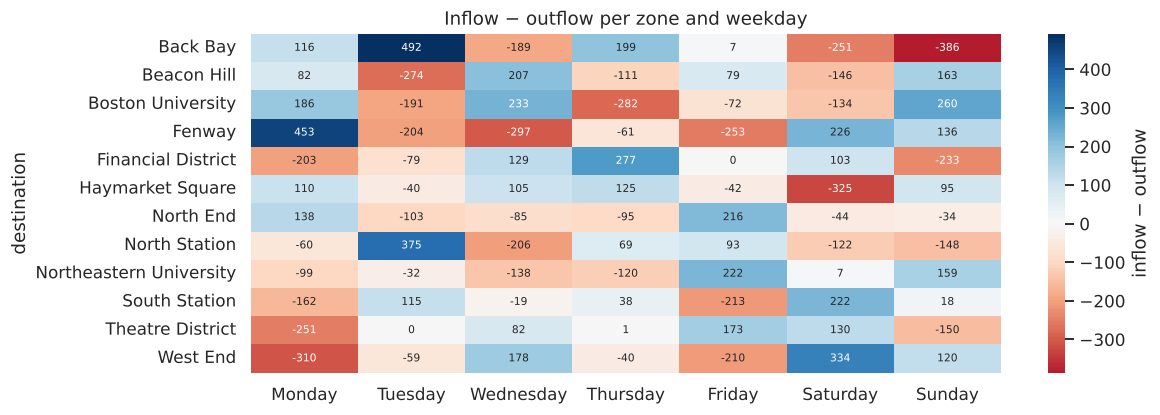

In [70]:
bal_wd = pd.DataFrame({d: (m.sum(axis=0) - m.sum(axis=1)) for d, m in od_wd.items()})
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(bal_wd, cmap="RdBu", center=0, annot=True, fmt=".0f", annot_kws={"size": 7}, ax=ax,
            cbar_kws={"label": "inflow − outflow"})
ax.set_title("Inflow − outflow per zone and weekday")
savefig("B1_balance_weekday")

## B-2. Trip distribution models
The future productions and attractions from the statement don't add up to the same total, so we scale the
origins to the destination total (factor about 1.0075). The base matrix is the overall OD matrix from
B-1.1.

In [71]:
future = pd.DataFrame({
    "zone": ["Financial District", "Theatre District", "Back Bay", "Haymarket Square", "Boston University",
             "Fenway", "North End", "Northeastern University", "South Station", "West End", "Beacon Hill",
             "North Station"],
    "O": [56850, 57820, 57799, 57836, 57714, 57750, 57963, 55756, 58750, 57560, 57483, 56228],
    "D": [59700, 57900, 58600, 56840, 59500, 56750, 58750, 56950, 58700, 56600, 58200, 56200],
}).set_index("zone").reindex(ZONES)
assert future.notna().all().all()
scale = future["D"].sum() / future["O"].sum()
O_fut = (future["O"] * scale).to_numpy(float)
D_fut = future["D"].to_numpy(float)
T0 = od.to_numpy(float)
print(f"Sum O = {future['O'].sum():,}, sum D = {future['D'].sum():,}, origin scale factor = {scale:.6f}")
print(f"Base total = {T0.sum():,.0f}; future total = {D_fut.sum():,.0f}; overall growth = {D_fut.sum() / T0.sum():.4f}")
pd.DataFrame({"base O": T0.sum(1), "future O": O_fut, "growth O": O_fut / T0.sum(1),
              "base D": T0.sum(0), "future D": D_fut, "growth D": D_fut / T0.sum(0)}, index=ZONES).round(4)

Sum O = 689,509, sum D = 694,690, origin scale factor = 1.007514
Base total = 693,071; future total = 694,690; overall growth = 1.0023


,base O,future O,growth O,base D,future D,growth D
Back Bay,57792.0,58233.3041,1.0076,57780.0,58600.0,1.0142
Beacon Hill,57403.0,57914.9297,1.0089,57403.0,58200.0,1.0139
Boston University,57764.0,58147.6655,1.0066,57764.0,59500.0,1.0301
Fenway,57757.0,58183.9360,1.0074,57757.0,56750.0,0.9826
Financial District,58857.0,57277.1733,0.9732,58851.0,59700.0,1.0144
Haymarket Square,57736.0,58270.5822,1.0093,57764.0,56840.0,0.9840
North End,57763.0,58398.5365,1.0110,57756.0,58750.0,1.0172
North Station,57118.0,56650.4996,0.9918,57119.0,56200.0,0.9839
Northeastern University,57756.0,56174.9530,0.9726,57755.0,56950.0,0.9861
South Station,57750.0,59191.4500,1.0250,57749.0,58700.0,1.0165


To compare the methods fairly they all use the same stopping rule: every row total and every column total
has to be within the tolerance of its target, i.e. all growth factors O_i/O_i(k) and D_j/D_j(k) lie in
[1 - tol, 1 + tol]. The statement fixes [0.99, 1.01] for Detroit, and the default 1% error gives the same
band for the others.

The four methods, in short:
* Furness: scale the rows to their targets, then the columns, and repeat.
* Detroit: T_ij(k+1) = T_ij(k) · E_i · E_j / E, with E_i = O_i/O_i(k), E_j = D_j/D_j(k) and E the overall growth.
* Fratar: T_ij(k+1) = T_ij(k) · E_i · E_j · (L_i + L_j)/2, where the location factors are
  L_i = O_i(k) / Σ_j T_ij(k) E_j and L_j = D_j(k) / Σ_i T_ij(k) E_i.
* Doubly constrained gravity: T_ij = A_i O_i B_j D_j f(c_ij), with the balancing factors A_i and B_j found
  iteratively.

In [72]:
def converged(T, O, D, tol):
    fi, fj = O / T.sum(1), D / T.sum(0)
    return max(np.abs(fi - 1).max(), np.abs(fj - 1).max()) <= tol, max(np.abs(fi - 1).max(), np.abs(fj - 1).max())


def furness(T0, O, D, tol=TOL, max_iter=MAX_ITER):
    T, hist = T0.copy(), []
    for k in range(1, max_iter + 1):
        T = T * (O / T.sum(1))[:, None]          # balance rows
        T = T * (D / T.sum(0))[None, :]          # balance columns
        ok, err = converged(T, O, D, tol); hist.append(err)
        if ok:
            return T, k, hist
    return T, max_iter, hist


def detroit(T0, O, D, tol=TOL, max_iter=MAX_ITER):
    """T_ij(k+1) = T_ij(k) · E_i · E_j / E,  E_i = O_i/O_i(k), E_j = D_j/D_j(k), E = T/T(k)."""
    T, hist = T0.copy(), []
    for k in range(1, max_iter + 1):
        Ei, Ej, E = O / T.sum(1), D / T.sum(0), D.sum() / T.sum()
        T = T * Ei[:, None] * Ej[None, :] / E
        ok, err = converged(T, O, D, tol); hist.append(err)
        if ok:
            return T, k, hist
    return T, max_iter, hist


def fratar(T0, O, D, tol=TOL, max_iter=MAX_ITER):
    """T_ij(k+1) = T_ij(k) · E_i · E_j · (L_i + L_j)/2,
    L_i = O_i(k) / Σ_j T_ij(k) E_j,   L_j = D_j(k) / Σ_i T_ij(k) E_i."""
    T, hist = T0.copy(), []
    for k in range(1, max_iter + 1):
        Oi_k, Dj_k = T.sum(1), T.sum(0)
        Ei, Ej = O / Oi_k, D / Dj_k
        Li = Oi_k / (T @ Ej)
        Lj = Dj_k / (Ei @ T)
        T = T * Ei[:, None] * Ej[None, :] * (Li[:, None] + Lj[None, :]) / 2
        ok, err = converged(T, O, D, tol); hist.append(err)
        if ok:
            return T, k, hist
    return T, max_iter, hist


def gravity(C, O, D, deterrence, tol=TOL, max_iter=MAX_ITER, allowed=None, alpha=1.0):
    """Doubly-constrained gravity: T_ij = A_i O_i B_j D_j f(c_ij), balancing factors found iteratively."""
    F = alpha * deterrence(C)
    if allowed is not None:
        F = np.where(allowed, F, 0.0)
    A, B, hist = np.ones(len(O)), np.ones(len(D)), []
    for k in range(1, max_iter + 1):
        A = 1.0 / (F @ (B * D))
        B = 1.0 / (F.T @ (A * O))
        T = (A * O)[:, None] * (B * D)[None, :] * F
        ok, err = converged(T, O, D, tol); hist.append(err)
        if ok:
            return T, k, hist
    return T, max_iter, hist

### Cost matrix
c_ij is the average recorded `distance` (miles) between i and j. Only the 84 connected pairs have one. In
the main gravity model the other 60 cells stay empty (f = 0), the same as in the base matrix and in the
growth-factor methods, so every method spreads trips over the same network. As a sensitivity check we also
fill the missing distances with shortest paths through the network (Floyd-Warshall) and give each zone an
intrazonal cost of half the distance to its nearest neighbour, which lets the gravity model use every
cell.

In [73]:
dist = df.groupby(["source", "destination"])["distance"].mean().unstack().reindex(index=ZONES, columns=ZONES)
allowed = dist.notna().to_numpy()
C = dist.to_numpy(float)

C_full = np.where(np.isnan(C), np.inf, C)
for k in range(len(ZONES)):                                 # Floyd–Warshall shortest paths
    C_full = np.minimum(C_full, C_full[:, [k]] + C_full[[k], :])
np.fill_diagonal(C_full, 0.5 * np.nanmin(np.where(allowed, C, np.nan), axis=1))
C_main = np.where(allowed, C, 1.0)                          # placeholder value, masked out by `allowed`

obs_mean_len = (T0 * np.nan_to_num(C)).sum() / T0.sum()
print(f"Observed mean trip length (base matrix): {obs_mean_len:.3f} miles")
dist.round(2)

Observed mean trip length (base matrix): 2.189 miles


destination,Back Bay,Beacon Hill,Boston University,Fenway,Financial District,Haymarket Square,North End,North Station,Northeastern University,South Station,Theatre District,West End
source,,,,,,,,,,,,
Back Bay,NaN,NaN,1.43,1.38,NaN,2.38,2.87,NaN,1.13,2.72,NaN,NaN
Beacon Hill,NaN,NaN,2.29,2.34,NaN,1.35,1.79,NaN,2.23,2.22,NaN,NaN
Boston University,1.57,2.74,NaN,NaN,4.55,NaN,NaN,3.43,NaN,NaN,2.90,3.07
Fenway,1.50,2.46,NaN,NaN,4.29,NaN,NaN,3.15,NaN,NaN,2.62,2.79
Financial District,NaN,NaN,5.17,4.48,NaN,1.16,1.18,NaN,4.06,0.42,NaN,NaN
Haymarket Square,2.18,1.17,NaN,NaN,0.97,NaN,NaN,0.51,NaN,NaN,1.21,0.64
North End,2.82,1.89,NaN,NaN,1.11,NaN,NaN,1.01,NaN,NaN,1.48,1.20
North Station,NaN,NaN,3.07,3.10,NaN,0.66,1.09,NaN,3.30,2.04,NaN,NaN
Northeastern University,1.49,2.53,NaN,NaN,4.18,NaN,NaN,3.22,NaN,NaN,2.08,2.86


### Deterrence functions
The statement gives an exponential deterrence with parameter 0.2, f(c) = e^(-0.2c). Any constant in front
of it (the α = 0.05 in the statement, or the 0.2 of the density 0.2·e^(-0.2c)) cancels out in a doubly
constrained model because A_i and B_j absorb it. We check that numerically below.

For the second function we use a power law, f(c) = c^(-γ). The usual way to pick γ is Hyman's method:
choose the value that reproduces the observed mean trip length. We try that first, but it turns out these
data show no distance decay at all (every route was logged about equally often, however long), so the
calibrated value is zero. Instead we set γ so the power model gives the same mean trip length as the
given exponential model. That way both functions have the same overall strength and only their shape
differs: the power law punishes the first fraction of a mile harder, the exponential punishes long trips
harder.

Calibrated to the OBSERVED mean trip length: power γ = 0.000, exponential β = 0.000
  (mean length with no decay at all = 2.184 mi vs observed 2.189 mi)


Mean trip length of the exp(−0.2c) model = 2.0624 mi -> matching power exponent γ = 0.37
Max |T(α=1) − T(α=0.05)| = 5.4569682106375694e-12


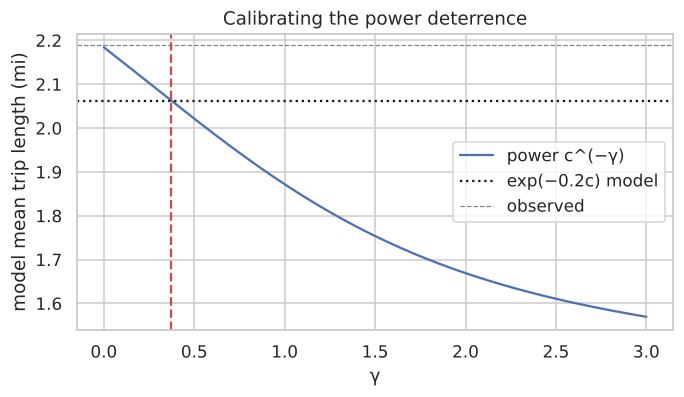

In [74]:
def mean_len(T, Cm):
    return (T * Cm).sum() / T.sum()


def calibrate(make_f, lo, hi, target, Cm, allowed_mask, n=60):
    grid = np.linspace(lo, hi, n)
    lens = [mean_len(gravity(Cm, O_fut, D_fut, make_f(g), tol=1e-8, allowed=allowed_mask)[0], np.nan_to_num(Cm)) for g in grid]
    return grid[int(np.argmin(np.abs(np.array(lens) - target)))], grid, lens


f_exp = lambda c: np.exp(-0.2 * c)
# (a) Hyman calibration against the observed mean trip length
gamma_obs, _, _ = calibrate(lambda g: (lambda c: c ** (-g)), 0.0, 3.0, obs_mean_len, C_main, allowed, n=121)
beta_obs, _, _ = calibrate(lambda b: (lambda c: np.exp(-b * c)), 0.0, 2.0, obs_mean_len, C_main, allowed, n=81)
print(f"Calibrated to the OBSERVED mean trip length: power γ = {gamma_obs:.3f}, exponential β = {beta_obs:.3f}")
T_noDecay = gravity(C_main, O_fut, D_fut, lambda c: np.ones_like(c), tol=1e-9, allowed=allowed)[0]
print(f"  (mean length with no decay at all = {mean_len(T_noDecay, np.nan_to_num(C_main)):.3f} mi vs observed {obs_mean_len:.3f} mi)")

# (b) power exponent giving the same mean trip length as the given exponential model
exp_len = mean_len(gravity(C_main, O_fut, D_fut, f_exp, tol=1e-9, allowed=allowed)[0], np.nan_to_num(C_main))
gamma_pow, g_grid, g_lens = calibrate(lambda g: (lambda c: c ** (-g)), 0.0, 3.0, exp_len, C_main, allowed, n=301)
f_pow = lambda c: c ** (-gamma_pow)
print(f"Mean trip length of the exp(−0.2c) model = {exp_len:.4f} mi -> matching power exponent γ = {gamma_pow:.2f}")

T_a1 = gravity(C_main, O_fut, D_fut, f_exp, allowed=allowed, alpha=1.0, tol=1e-9)[0]
T_a005 = gravity(C_main, O_fut, D_fut, f_exp, allowed=allowed, alpha=0.05, tol=1e-9)[0]
print("Max |T(α=1) − T(α=0.05)| =", float(np.abs(T_a1 - T_a005).max()))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(g_grid, g_lens, label="power c^(−γ)"); ax.axhline(exp_len, ls=":", color="k", label="exp(−0.2c) model")
ax.axhline(obs_mean_len, ls="--", color="grey", lw=0.8, label="observed")
ax.axvline(gamma_pow, ls="--", color="#C44E52")
ax.set_xlabel("γ"); ax.set_ylabel("model mean trip length (mi)"); ax.legend(); ax.set_title("Calibrating the power deterrence")
savefig("B2_calibration")

### Running everything (1% tolerance, at most 1000 iterations)

In [75]:
methods = {
    "Furness": lambda tol: furness(T0, O_fut, D_fut, tol),
    "Detroit": lambda tol: detroit(T0, O_fut, D_fut, tol),
    "Fratar": lambda tol: fratar(T0, O_fut, D_fut, tol),
    "Gravity – exp(−0.2c)": lambda tol: gravity(C_main, O_fut, D_fut, f_exp, tol, allowed=allowed),
    f"Gravity – power (γ={gamma_pow:.2f})": lambda tol: gravity(C_main, O_fut, D_fut, f_pow, tol, allowed=allowed),
}
out = {name: run(TOL) for name, run in methods.items()}
T_sens = gravity(C_full, O_fut, D_fut, f_exp, TOL)[0]


def summarise(name, T, k):
    return {"iterations": k, "total": T.sum(),
            "max row error %": np.abs(T.sum(1) / O_fut - 1).max() * 100,
            "max col error %": np.abs(T.sum(0) / D_fut - 1).max() * 100,
            "mean trip length (mi)": mean_len(T, np.nan_to_num(C_full)),
            "RMSE vs scaled base": np.sqrt(np.mean((T - T0 * D_fut.sum() / T0.sum()) ** 2)),
            "trips on unconnected pairs": T[~allowed].sum()}


comp = pd.DataFrame({n: summarise(n, T, k) for n, (T, k, _) in out.items()}).T
comp.loc["Gravity – exp, all cells (sensitivity)"] = summarise("s", T_sens, gravity(C_full, O_fut, D_fut, f_exp, TOL)[1])
comp.round(3)

,iterations,total,max row error %,max col error %,mean trip length (mi),RMSE vs scaled base,trips on unconnected pairs
Furness,1.0,694690.000,0.369,0.000,2.148,150.971,0.000
Detroit,1.0,694689.936,0.073,0.322,2.148,152.336,0.000
Fratar,1.0,694690.000,0.185,0.180,2.148,151.212,0.000
Gravity – exp(−0.2c),2.0,694690.000,0.410,0.000,2.032,1108.994,0.000
Gravity – power (γ=0.37),2.0,694690.000,0.400,0.000,2.032,1143.354,0.000
"Gravity – exp, all cells (sensitivity)",2.0,694690.000,0.039,0.000,2.062,4855.601,342249.092


With a 1% tolerance every method stops after one or two iterations. Two reasons:

1. The base matrix is already nearly balanced and the future totals are within 4% of the base totals for
   every zone, so the first correction already lands inside 1%.
2. The targets can't be met exactly on this network. Since trips only go between the two groups, the
   origins of group A have to equal the destinations of group B. In the future table they differ by
   about 0.34%, so no matrix with these structural zeros can hit all the row and column targets. The
   methods settle at an error of about 0.34%. That's under 1%, so the 1% rule is satisfied, but any
   tighter rule never is.

In [76]:
A_grp = [z for z in ZONES if allowed[ZONES.index("Boston University")][ZONES.index(z)]]   # zones reached from BU
inA = np.array([z in A_grp for z in ZONES])
print("Group A:", A_grp)
print(f"Σ O(A) = {O_fut[inA].sum():,.0f} vs Σ D(B) = {D_fut[~inA].sum():,.0f}  (ratio {O_fut[inA].sum() / D_fut[~inA].sum():.4f})")
print(f"Σ O(B) = {O_fut[~inA].sum():,.0f} vs Σ D(A) = {D_fut[inA].sum():,.0f}  (ratio {O_fut[~inA].sum() / D_fut[inA].sum():.4f})")
print("Error floor reached by Furness after 1000 iterations: %.4f%%" % (furness(T0, O_fut, D_fut, 1e-12)[2][-1] * 100))

Group A: ['Back Bay', 'Beacon Hill', 'Financial District', 'North Station', 'Theatre District', 'West End']
Σ O(A) = 346,323 vs Σ D(B) = 347,490  (ratio 0.9966)
Σ O(B) = 348,367 vs Σ D(A) = 347,200  (ratio 1.0034)
Error floor reached by Furness after 1000 iterations: 0.3362%


To compare speed properly, we rescale the origin targets within each group so they fit the network
(a change of ±0.34%) and rerun everything with tolerances from 1% down to 10⁻⁸.

In [77]:
O_feas = O_fut.copy()
O_feas[inA] *= D_fut[~inA].sum() / O_fut[inA].sum()
O_feas[~inA] *= D_fut[inA].sum() / O_fut[~inA].sum()
methods_feas = {
    "Furness": lambda tol: furness(T0, O_feas, D_fut, tol),
    "Detroit": lambda tol: detroit(T0, O_feas, D_fut, tol),
    "Fratar": lambda tol: fratar(T0, O_feas, D_fut, tol),
    "Gravity – exp(−0.2c)": lambda tol: gravity(C_main, O_feas, D_fut, f_exp, tol, allowed=allowed),
    f"Gravity – power (γ={gamma_pow:.2f})": lambda tol: gravity(C_main, O_feas, D_fut, f_pow, tol, allowed=allowed),
}
speed = pd.DataFrame({tol: {n: run(tol)[1] for n, run in methods_feas.items()} for tol in [1e-2, 1e-3, 1e-4, 1e-6, 1e-8]})
speed.columns = [f"tol = {c:g}" for c in speed.columns]
print(speed)

print("Detroit error after 1, 2, 5, 50 iterations:",
      [f"{e:.2e}" for e in np.array(detroit(T0, O_feas, D_fut, 1e-12, 50)[2])[[0, 1, 4, 49]]])

                          tol = 0.01  tol = 0.001  tol = 0.0001  tol = 1e-06  tol = 1e-08
Furness                            1            1             2            2            3
Detroit                            1            1          1000         1000         1000
Fratar                             1            1             2            3            4
Gravity – exp(−0.2c)               2            2             3            4            5
Gravity – power (γ=0.37)           2            2             3            4            5
Detroit error after 1, 2, 5, 50 iterations: ['7.34e-04', '3.98e-04', '3.90e-04', '3.90e-04']


Furness and Fratar are the fastest and reach machine precision in a handful of iterations. The gravity
models need one or two more because they start from the deterrence matrix instead of the base matrix,
but they also converge to any tolerance. Detroit meets the [0.99, 1.01] band after one iteration and then
gets stuck at about 0.04%: dividing by the overall growth factor keeps the total right but leaves a small
permanent mismatch in the rows and columns. That's a known weakness of Detroit; it's a heuristic rather
than a real balancing algorithm like Furness.

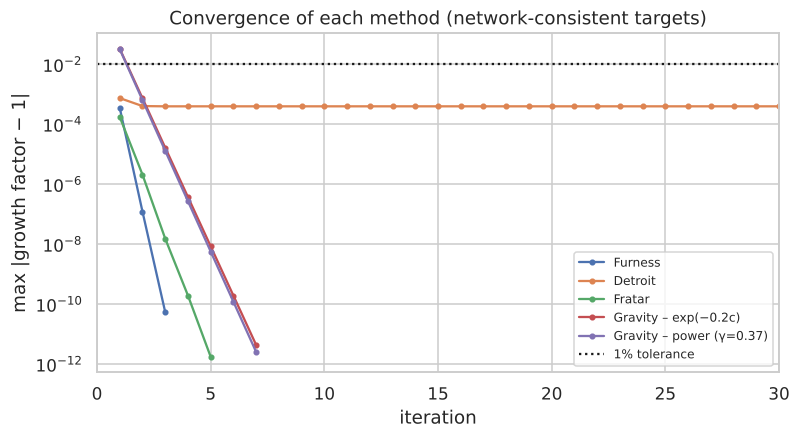

In [78]:
fig, ax = plt.subplots(figsize=(8, 4))
for n, run in methods_feas.items():
    h = run(1e-10)[2]
    ax.semilogy(range(1, len(h) + 1), h, "o-", ms=3, label=n)
ax.axhline(TOL, ls=":", color="k", label="1% tolerance")
ax.set_xlabel("iteration"); ax.set_ylabel("max |growth factor − 1|"); ax.set_xlim(0, 30)
ax.set_title("Convergence of each method (network-consistent targets)"); ax.legend(fontsize=8)
savefig("B2_convergence")

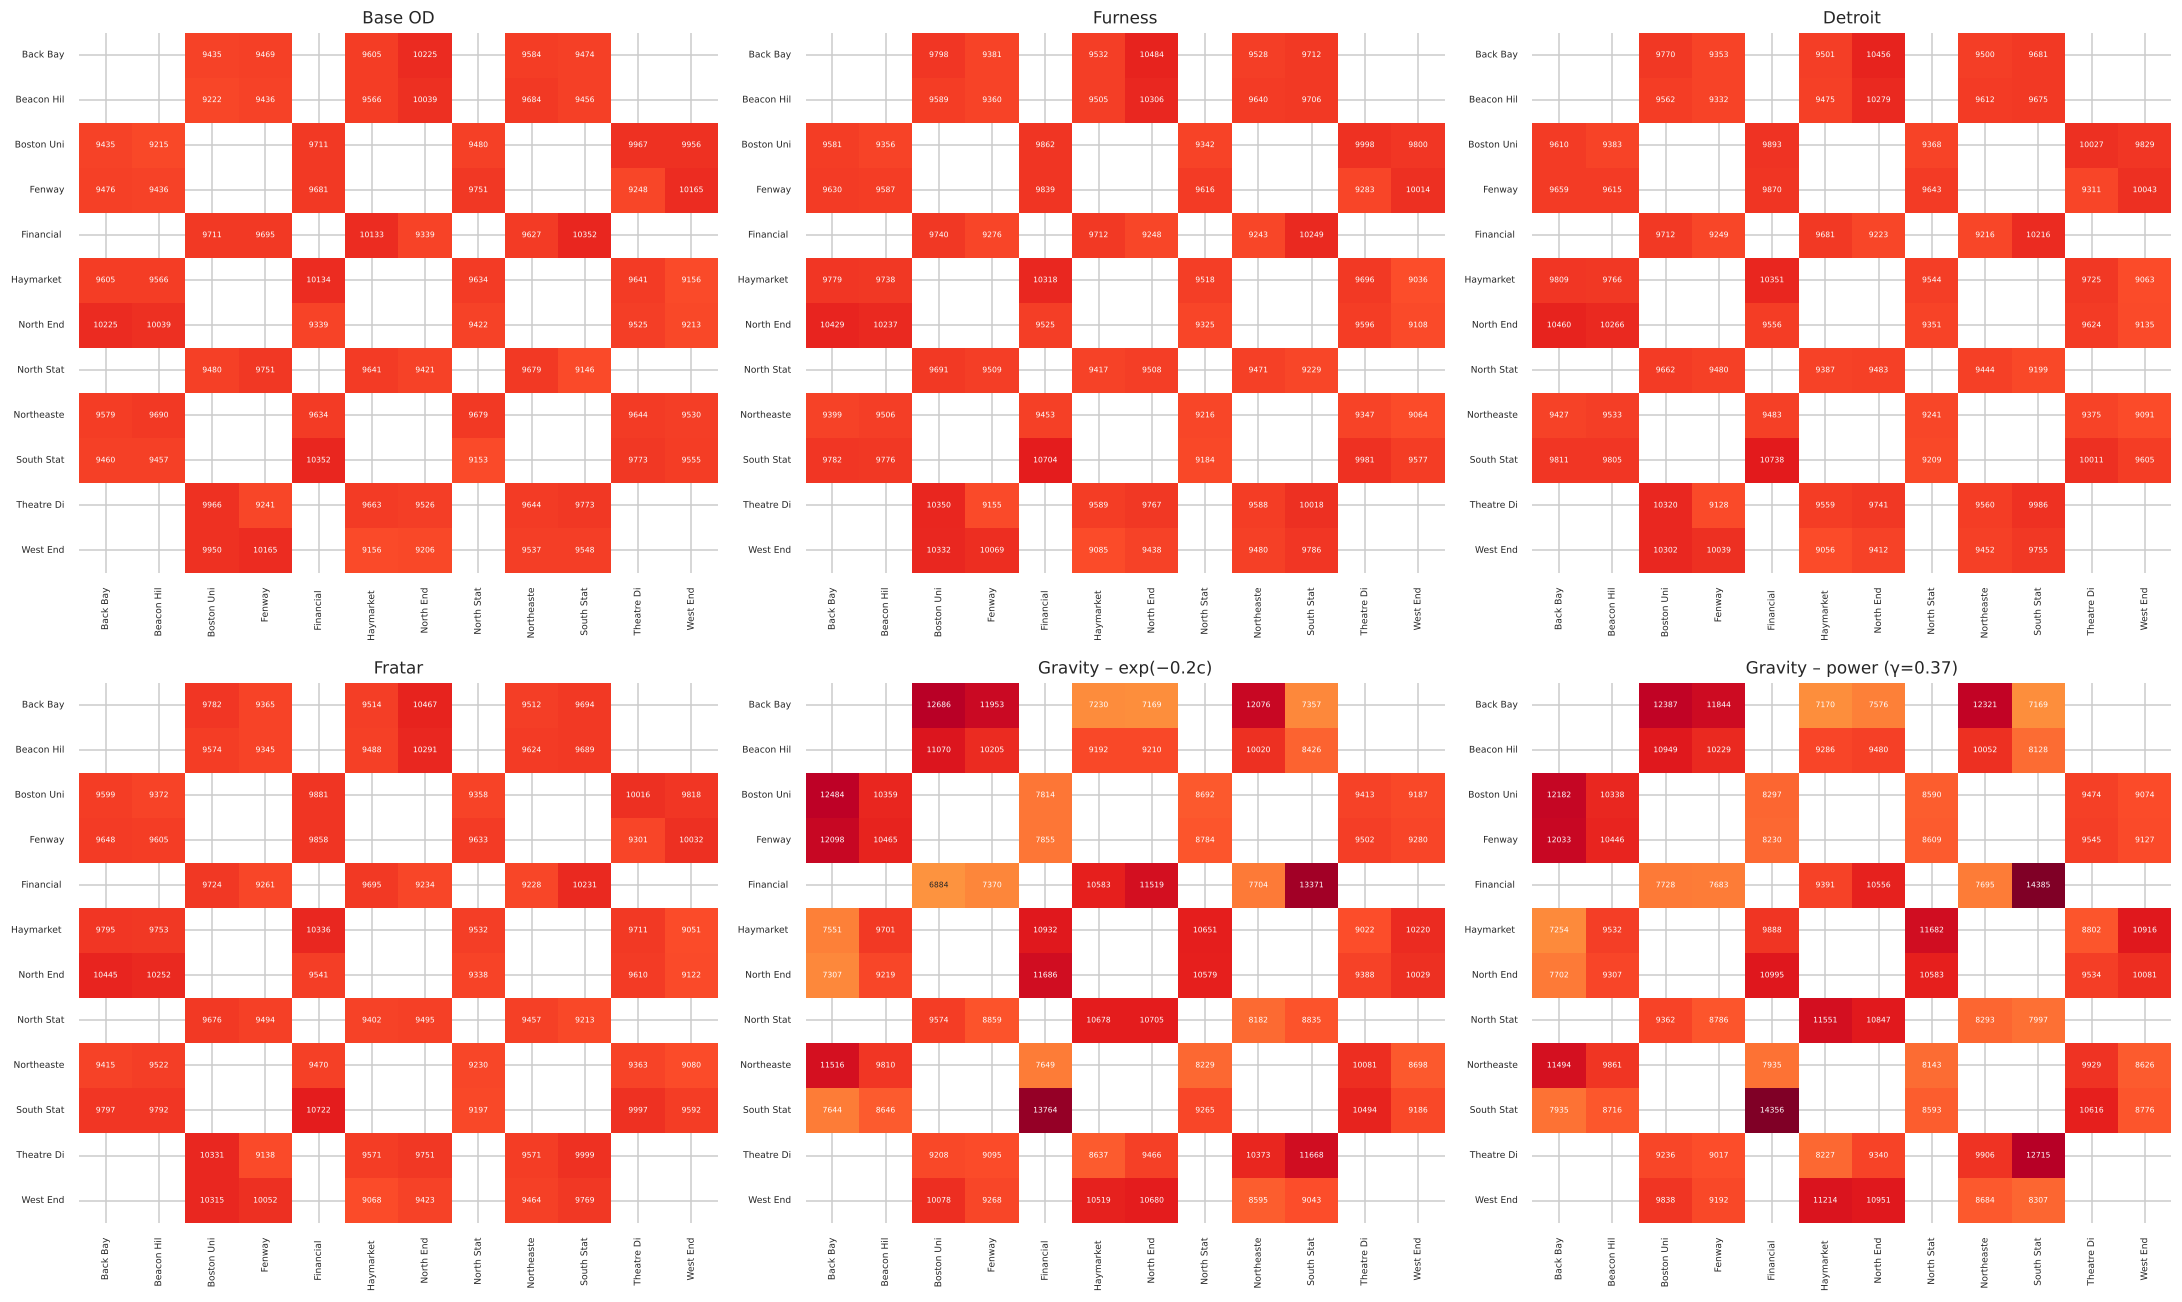

In [79]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
mats = {"Base OD": T0, **{n: T for n, (T, k, _) in out.items()}}
vmax = max(m.max() for m in mats.values())
for ax, (n, M) in zip(axes.flat, mats.items()):
    sns.heatmap(pd.DataFrame(M, index=ZONES, columns=ZONES).replace(0, np.nan), cmap="YlOrRd", vmin=0, vmax=vmax,
                annot=True, fmt=".0f", annot_kws={"size": 5}, cbar=False, ax=ax,
                xticklabels=[z[:10] for z in ZONES], yticklabels=[z[:10] for z in ZONES])
    ax.set_title(n, fontsize=11); ax.tick_params(labelsize=6)
plt.tight_layout()
savefig("B2_matrices")

In [80]:
# How different are the four forecasts? Cell-by-cell comparison with Furness.
ref = out["Furness"][0]
diff = pd.DataFrame({n: {"max |T − T_Furness|": np.abs(T - ref).max(),
                         "mean |T − T_Furness|": np.abs(T - ref)[allowed].mean(),
                         "correlation with Furness": np.corrcoef(T[allowed], ref[allowed])[0, 1]}
                     for n, (T, k, _) in out.items()}).T
diff.round(3)

,max |T − T_Furness|,mean |T − T_Furness|,correlation with Furness
Furness,0.000,0.000,1.000
Detroit,34.446,28.657,0.997
Fratar,19.454,16.210,0.999
Gravity – exp(−0.2c),3314.829,1280.443,0.051
Gravity – power (γ=0.37),4135.657,1339.690,0.086


Furness, Detroit and Fratar give practically the same forecast (correlation above 0.997, differences of a
few dozen trips per cell). With growth factors this close to 1, all three just rescale the base matrix.

The gravity models don't use the base pattern at all, only zone totals and distances. They send many
more trips to short pairs (Haymarket and North Station are 0.5 to 0.7 miles apart) and fewer to long ones,
so their correlation with Furness is near zero and the mean trip length drops from 2.15 to 2.03 miles.

If you have a base matrix you trust, growth-factor methods are the safer choice for a short horizon; the
gravity model is for when there's no base matrix or the network changes. Here the "observed" matrix is
itself a product of uniform scraping, so neither forecast should be read as real demand.

In [81]:
with pd.ExcelWriter(OUT_DIR / "phase2_results.xlsx") as w:
    od.to_excel(w, sheet_name="OD_all")
    for d in WEEKDAYS:
        od_wd[d].to_excel(w, sheet_name=f"{d[:3]}_total")
        od_wd_avg[d].round(2).to_excel(w, sheet_name=f"{d[:3]}_avg_per_date")
    bal.to_excel(w, sheet_name="balance")
    for n, (T, k, _) in out.items():
        pd.DataFrame(T, index=ZONES, columns=ZONES).round(2).to_excel(w, sheet_name=n[:28].replace("–", "-").replace("(", "").replace(")", "").replace("=", ""))
    comp.to_excel(w, sheet_name="comparison")
print("Saved outputs/phase2_results.xlsx")

Saved outputs/phase2_results.xlsx


## B-3. Revenue-maximising trip plan for a new competitor
The setting: we enter the market as a third company. The day is split into four 6-hour periods (00-06,
06-12, 12-18, 18-24). For every weekday and period, our price on route i to j is the average price Uber
and Lyft charged on that route, weekday and period. The fleet can drive at most 20 km a day, and there is
no service on Saturday or Sunday. How many trips should we run on each route in each period of each day?

Some choices the statement leaves open:
* There are no cost figures, so profit is simply revenue.
* `distance` is in miles, so 20 km is 12.43 miles.
* On each route, day and period we can't run more trips than the average number recorded there per date
  (the statement allows using averages from the OD matrix).
* Trips are whole numbers. The model is solved with SciPy's MILP solver (HiGHS), so nothing extra needs
  installing.

For each service day d:

max Σ p_ijdt · x_ijdt   subject to   Σ c_ij · x_ijdt ≤ 20 km,   0 ≤ x_ijdt ≤ u_ijdt,   x integer.

A second version adds flow conservation per zone over the day (Σ_j x_ij = Σ_j x_ji): every zone the car
drives into, it also leaves. That's much closer to what one car can actually do.

In [82]:
from scipy.optimize import milp, LinearConstraint, Bounds

KM_PER_MILE = 1.609344
BUDGET_KM = 20.0
PERIODS = {0: "00–06", 1: "06–12", 2: "12–18", 3: "18–24"}
SERVICE_DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

priced = df.dropna(subset=["price"]).copy()
priced["period"] = priced["hour"] // 6
price = priced.groupby(["weekday", "period", "source", "destination"], observed=True)["price"].mean()
dist_km = df.groupby(["source", "destination"])["distance"].mean() * KM_PER_MILE
trips = df.assign(period=df["hour"] // 6).groupby(["weekday", "period", "source", "destination"], observed=True).size()
cap = (trips / trips.index.get_level_values(0).map(dates_per_wd).to_numpy()).round()

data3 = pd.DataFrame({"price": price, "cap": cap}).dropna().reset_index()
data3["km"] = data3.set_index(["source", "destination"]).index.map(dist_km).to_numpy()
data3["revenue per km"] = data3["price"] / data3["km"]
data3 = data3[data3["weekday"].isin(SERVICE_DAYS)].reset_index(drop=True)
print("Decision variables (route × period × service day):", len(data3))
data3.sort_values("revenue per km", ascending=False).head(10).round(3)

Decision variables (route × period × service day): 1440


,weekday,period,source,destination,price,cap,km,revenue per km
101,Monday,1,Financial District,South Station,13.183,110.0,0.673,19.588
965,Thursday,1,Financial District,South Station,12.737,178.0,0.673,18.926
389,Tuesday,1,Financial District,South Station,12.677,168.0,0.673,18.835
893,Thursday,0,Financial District,South Station,12.652,248.0,0.673,18.799
533,Tuesday,3,Financial District,South Station,12.566,97.0,0.673,18.670
1037,Thursday,2,Financial District,South Station,12.548,136.0,0.673,18.644
317,Tuesday,0,Financial District,South Station,12.543,230.0,0.673,18.637
461,Tuesday,2,Financial District,South Station,12.496,132.0,0.673,18.567
29,Monday,0,Financial District,South Station,12.395,111.0,0.673,18.418
1181,Friday,0,Financial District,South Station,12.333,148.0,0.673,18.325


In [83]:
def solve_day(day_df, flow_balance=False):
    """Integer programme for one day, solved with SciPy's MILP solver (HiGHS)."""
    day_df = day_df.reset_index(drop=True)
    n = len(day_df)
    c = -day_df["price"].to_numpy()                                   # milp minimises
    cons = [LinearConstraint(day_df["km"].to_numpy()[None, :], -np.inf, BUDGET_KM)]
    if flow_balance:
        A = np.zeros((len(ZONES), n))
        for z_i, z in enumerate(ZONES):
            A[z_i, (day_df["source"] == z).to_numpy()] += 1
            A[z_i, (day_df["destination"] == z).to_numpy()] -= 1
        cons.append(LinearConstraint(A, 0, 0))
    res = milp(c, constraints=cons, integrality=np.ones(n), bounds=Bounds(0, day_df["cap"].to_numpy()))
    chosen = day_df.assign(trips=np.round(res.x).astype(int))
    return ("Optimal" if res.status == 0 else res.message), -res.fun, chosen[chosen["trips"] > 0]


plans, rows = {}, []
for version, fb in [("knapsack", False), ("with flow balance", True)]:
    for d in SERVICE_DAYS:
        status, rev, chosen = solve_day(data3[data3["weekday"] == d], flow_balance=fb)
        plans[(version, d)] = chosen
        rows.append({"version": version, "day": d, "status": status, "revenue ($)": rev,
                     "trips": int(chosen["trips"].sum()), "km used": (chosen["trips"] * chosen["km"]).sum()})
summary3 = pd.DataFrame(rows)
print(summary3.round(2).to_string(index=False))
print("\nWeekly revenue:", summary3.groupby("version")["revenue ($)"].sum().round(2).to_dict())

          version       day  status  revenue ($)  trips  km used
         knapsack    Monday Optimal       382.85     29    19.79
         knapsack   Tuesday Optimal       368.16     29    19.79
         knapsack Wednesday Optimal       349.91     29    19.97
         knapsack  Thursday Optimal       370.00     29    19.94
         knapsack    Friday Optimal       358.57     29    19.87
with flow balance    Monday Optimal       312.88     24    19.69
with flow balance   Tuesday Optimal       305.59     24    19.69
with flow balance Wednesday Optimal       299.62     24    19.93
with flow balance  Thursday Optimal       303.71     24    19.93
with flow balance    Friday Optimal       298.59     24    19.93

Weekly revenue: {'knapsack': 1829.49, 'with flow balance': 1520.39}


With only 20 km a day, the distance budget is the only constraint that binds (the demand caps on the
chosen routes are 60 to 450 trips per period), so it becomes a knapsack problem: run the trips with the
most revenue per kilometre. Every day that is Financial District to South Station, 0.67 km for about \$12
to 13, so \$18 to 20 per km. That's about 28 trips a day, plus one or two other short trips to use up the
last bit of distance, for \$350 to 383 a day and about \$1,829 a week. The best period changes from day
to day because the average price on that route peaks at different times on different days.

A real car can't do the same one-way trip 28 times without driving back. With flow conservation the model
pairs Financial District to South Station with the return trip (about 12 + 12 trips), revenue drops by
about 17% to roughly \$1,520 a week, and the car always leaves the zones it enters. Driving empty to
reposition is still not counted; adding empty kilometres or a cost per kilometre would be the obvious
next step.

In [84]:
for version in ["knapsack", "with flow balance"]:
    print(f"\n=== {version} ===")
    for d in SERVICE_DAYS:
        c = plans[(version, d)].copy()
        c["period"] = c["period"].map(PERIODS)
        print(f"-- {d}")
        print(c[["period", "source", "destination", "trips", "price", "km", "revenue per km"]].round(2).to_string(index=False))


=== knapsack ===
-- Monday
period             source   destination  trips  price   km  revenue per km
 00–06   Theatre District South Station      1  13.73 0.94           14.57
 06–12 Financial District South Station     28  13.18 0.67           19.59
-- Tuesday
period             source   destination  trips  price   km  revenue per km
 06–12 Financial District South Station     28  12.68 0.67           18.84
 06–12   Theatre District South Station      1  13.21 0.94           14.03
-- Wednesday
period             source   destination  trips  price   km  revenue per km
 00–06   Haymarket Square North Station      3  12.93 0.82           15.69
 12–18 Financial District South Station     26  11.97 0.67           17.78
-- Thursday
period             source   destination  trips  price   km  revenue per km
 06–12 Financial District South Station     27  12.74 0.67           18.93
 06–12   Theatre District South Station      1  13.33 0.94           14.15
 12–18   Haymarket Square North Stat

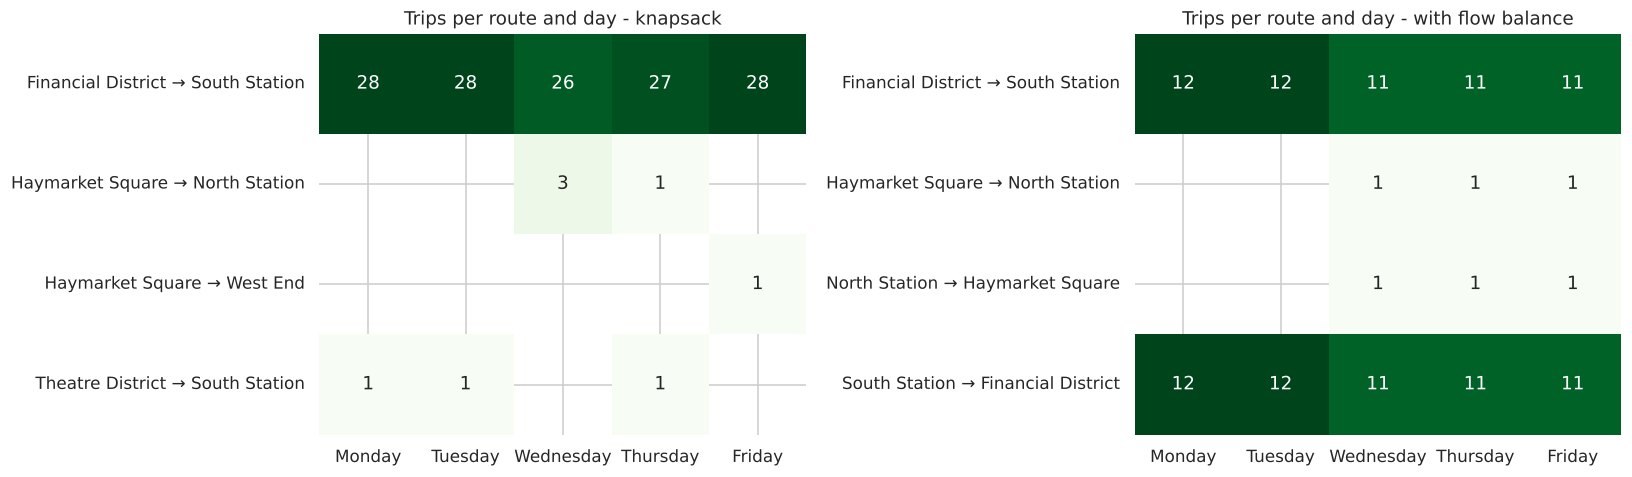

Saved outputs/phase2_part3_plan.xlsx


In [85]:
plan_tbl = pd.concat([p.assign(version=v) for (v, d), p in plans.items()])
plan_tbl["period"] = plan_tbl["period"].map(PERIODS)
plan_tbl["route"] = plan_tbl["source"] + " → " + plan_tbl["destination"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=False)
for ax, v in zip(axes, ["knapsack", "with flow balance"]):
    pv = plan_tbl[plan_tbl.version == v].pivot_table(index="route", columns="weekday", values="trips",
                                                     aggfunc="sum", observed=True).reindex(columns=SERVICE_DAYS)
    sns.heatmap(pv, annot=True, fmt=".0f", cmap="Greens", cbar=False, ax=ax)
    ax.set_title(f"Trips per route and day - {v}"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
savefig("B3_plan")

with pd.ExcelWriter(OUT_DIR / "phase2_part3_plan.xlsx") as w:
    summary3.to_excel(w, sheet_name="summary", index=False)
    plan_tbl.to_excel(w, sheet_name="trip plan", index=False)
    data3.to_excel(w, sheet_name="prices and caps", index=False)
print("Saved outputs/phase2_part3_plan.xlsx")